In [1]:
# ======================================================================
# EMS 異常檢測系統 — v13（ESS 儲能 / PV 太陽光電 / EV 電動車）
# ----------------------------------------------------------------------
#   ★ v13 新增（相對 v12）：
#    a) ZOO_TUNE_EVERY_SEED：可改成每個種子都重新調參（預設只在第一個種子調）
#    b) 非監督『無標籤』版本：預設參數、門檻只看訓練分數分布，和『上限』並列報告
#    c) 臨界差異圖：測試段切 5 個時間區塊（5 種子 → 25 個區塊）
#   ★ v12 新增（相對 v11.1）：
#    1) 特徵清理（不看標籤：刪掉幾乎不變、彼此相關 > 0.95 的欄位）＋排列重要度圖，取代肘部法
#    2) 時間序列交叉驗證（3 段擴張視窗，驗證前留 24 筆間隔）
#    3) 臨界差異圖：Friedman ＋ Nemenyi 檢定，標出哪些模型在統計上並列
#    4) Optuna 調參：每個模型同樣 15 次試驗，目標＝交叉驗證平均 PR-AUC
#    5) 事件層級評估＋告警持續條件（連續 n 筆中 k 筆超過門檻才告警，k/n 在驗證段選）
#    所有結果放在 outputs_v13/
# ----------------------------------------------------------------------
#   ★ v11 新增（相對 v10）：
#    A) 多模型公平比較：最常見的非監督 6 種、監督 6 種（＋數位孿生參考），
#       各類驗證最佳的前 3 名放進候選池，2、3、4 個的所有組合（平均／最大值）；ESS、PV、EV 各自比較
#       公平：同一組訓練資料、同一組特徵、每個模型最多 4 組參數且都用驗證 PR-AUC 挑、同樣的門檻規則
#       → 回答「哪一種模型在哪個子系統表現最好」，不預設混合一定比較好
#    B) 兩種門檻並列：驗證 F1 最高、誤報率 ≤ 0.5%；並報 ROC-AUC、PR-AUC、各異常類型偵測率
#    C) ESS、PV、EV 各自出圖（這一版所有結果都放在 outputs_v13/ 同一個資料夾）
#    D) PV 改善：新增「功率 ÷ 日照」「與過去 7 天比值」「功率變化」特徵；
#       PV 衰退只注入在日照 ≥ 200 的時段（低日照時本來就無法判斷）
#    E) v11.1：第二部分（訓練與比較）全部改用 6＋6＋組合的公平比較，所有性能圖都換成這些模型；
#       舊的 Hybrid 訓練移到附錄，只有現場運行需要；所有結果放在 outputs_v13/
# ----------------------------------------------------------------------
# （以下為 v9 說明）
# ----------------------------------------------------------------------
#   ★ v9 修正（相對 v8）：
#    1) 可重現：互資訊固定 random_state、LightGBM deterministic、執行緒數固定 N_JOBS
#       → 同一份程式、同一個種子，重跑結果相同
#    2) PV/EV Hybrid：驗證 F1 與最高值相差 HYBRID_W_TOL 以內時，優先用較大的孿生權重
#       （v8 平手一律取 w=0，PV 永遠沒用到孿生）；報告同時列出 v8 選法的 w
#    3) PV：新增「資料檢查」格；讀取時剔除疑似尖峰；PV 發電殘差改成相對殘差（實際/預期）
#    4) 每次訓練另開時間戳資料夾，不覆蓋舊結果；資料夾內『最新版本.txt』指向最新一次
#    5) 「快速恢復」改為第三部分 C-0，載入的是最新的 ESS 部署版模型
#    6) EV 紀錄器可寫成獨立腳本，用 Windows 工作排程器執行（不用一直開 Jupyter）
#       ＋ 資料源停更檢查（PV / EV 超過一定時間沒有新資料會警告）
#    7) 肘部法新增「第一個達到最高 F1 99.5% 的 k」選法（PV/EV 使用；ESS 維持論文版選法）
#    8) PV/EV 多分類改用全部特徵（不沿用二元分類的 k）
#    9) ESS 現場運行：從 Firebase ems_data 預載最近的現場資料，不用每次空等 30 分鐘
#   10) PV 資料檢查會印出實際有效資料期間
#   11) 圖：分數分布標示正規化門檻、時序圖分出命中/漏報/誤報、多分類加比例版、
#       PV 加 ROC/PR 與數值標籤、多種子圖改為突顯最佳模型
# ======================================================================
# （以下為 v5 以來的歷史說明）
# EMS 異常檢測系統 — 完整版 v5（本機 Jupyter / .ipynb 版本，SOC 來源修正版）
# ----------------------------------------------------------------------
#   ★ v5 更動（整合邱老師實驗室同後台、已驗證可讀到 SOC 的連線方式）：
#   SOC 改從「儲能主機」192.168.1.200:502、FC03 位址 199 讀取，取代原本連
#   不上的 EMS（192.168.1.204:2000）。邱老師實驗室同學是透過 VPN 連進同一套
#   後台，其餘設定與本檔相同，其 ems_other_laboratory_renew.py 已驗證這組
#   位址可穩定讀到 SOC。EMS 相關程式碼原封不動保留、預設停用，之後排查通了
#   只要把 EMS_CFG['enabled'] 改回 True，讀到的值會優先覆蓋。
# ----------------------------------------------------------------------
#   【階段一】離線訓練：讀歷史 CSV + 混搭模擬異常 → 訓練 Hybrid(IF+RF/XGB) +
#            多分類診斷模型 → 存檔（joblib）
#   【階段二】線上即時運行：pymodbus 讀現場 Modbus TCP 端點 → 用階段一
#            訓練好的模型推論 → 寫回 Firebase（Dashboard 自動更新）
#
# ★ 本版（v4）根據現場實際 Modbus 診斷結果做的修正：
#   1) 主表 / 儲能電表暫存器位址修正為 Acuvim II 手冊的
#      FC03、0x4022~0x4023、float32（原本 v3 用的 0x4006 + FC04 是錯的佔位值）。
#      現場實測：主表 88.13 kW、儲能電表 -0.637 kW，且跟現場儀表板數字吻合。
#   2) 確認「儲能電表」量到的 Psum 就是 ESS 功率本身（不是另一組負載），
#      調節後負載改用 before_load - ess_power 現場運算得出，
#      不再需要從 EMS 額外讀一次 ess_power。
#      （已用現場儀表板截圖數字交叉驗證：90.06 - (-0.63) = 90.69，兩邊對得上）
#   3) EMS（192.168.1.204:2000）目前現場連線異常：TCP 連得上，但標準 Modbus TCP
#      請求完全沒有回應；改用 RTU framer 測試時，設備會在 ~25ms 內主動關閉連線，
#      代表設備確實有在解析封包但拒絕/不認得這組請求 —— 高度懷疑是 unit_id
#      或暫存器位址跟這台實際設備不符，而非單純網路/硬體故障。
#      在排查出正確參數前，EMS 預設停用（EMS_CFG['enabled'] = False），
#      SOC / SOH 會明確標記為 EMS_DISABLED，不會偷偷補 0 或沿用上一筆冒充。
#   4) 移除「Modbus 讀取失敗時沿用上一筆資料」的行為：讀取失敗一律標記狀態
#      （BAD / EMS_DISABLED），絕不用舊資料或 0 冒充本次量測。
#   5) 新增【執行區塊：Modbus 診斷】，開始長時間輪詢 / 寫 Firebase 之前，
#      先用這一格單獨測試 TCP + Modbus 是否正常，不需要模型、不需要 Firebase。
#   6) 離線訓練 use_synthetic_diagnostic_features 預設改為 False：
#      正式現場模型預設只用真實欄位（before_load/after_load/contract_capacity/
#      ess_power/soc）衍生特徵；SOC 仍然需要 EMS 才有現場即時值，若 EMS 沒打開，
#      即時異常偵測模組會明確標記為「本輪略過」，不會假造 SOC。
#      如需研究對照，請用 run_ablation_comparison()。
#
# ⚠ 這份是「現場 Modbus 診斷版」修正，主表/儲能電表的讀值路徑已用現場
#   數值交叉驗證過，可信；EMS 讀值路徑仍待現場排查 unit_id / 位址後再啟用。
# ======================================================================


## ⚡ 快速恢復（Kernel 重開後）

v9 起，快速恢復改放在 **第三部分 → C-0 載入已訓練模型**。

做法：從上往下執行「第一段」到「執行紀錄工具」為止的所有**函式格**（只是定義函式，很快，不會重新訓練），然後直接跳到 C-0。

（v8 這裡用的是舊的 `ems_realtime_lib`，會載入根目錄的舊模型，所以拿掉了。）

> 本格在 v9 已移除（原本的快速恢復會載入舊模型）。

## 第一段：安裝套件與環境導入
第一次在這台電腦上執行時，取消下一行的註解來安裝套件（之後可以註解掉）。

In [2]:
%pip install firebase-admin pandas numpy scikit-learn matplotlib seaborn imbalanced-learn xgboost psutil pymodbus joblib lightgbm -q optuna


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from collections import deque
import glob
import os
import re
import time
import psutil
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.ensemble import IsolationForest, RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import (precision_score, recall_score, f1_score,
                            accuracy_score, confusion_matrix, classification_report,
                            roc_curve, auc, precision_recall_curve)
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# 中文字型：Windows 常見中文字型優先，其餘平台 fallback
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial Unicode MS', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print("✓ 套件載入完成")

# ★ v13：這一版所有結果都放在同一個最外層資料夾 outputs_v13/（ESS儲能、PV太陽光電、EV電動車、三子系統總表）
#   以前的 outputs_ESS儲能、outputs_PV太陽光電、outputs_EV電動車、outputs_新增模型版 本版只可能『讀取』，絕不寫入
OUT_ROOT = Path.cwd() / "outputs_v13"
NEW_OUT = OUT_ROOT / "ESS儲能"
NEW_OUT.mkdir(parents=True, exist_ok=True)
PREV_OUT = {'ESS': Path.cwd() / "outputs_ESS儲能", 'PV': Path.cwd() / "outputs_PV太陽光電",
            'EV': Path.cwd() / "outputs_EV電動車"}          # v10 以前的結果（只讀）
OLD_OUT = Path.cwd() / "outputs_新增模型版"   # 上次的結果：本版只可能『讀取』舊模型，絕不寫入
def OUT(name):
    return str(NEW_OUT / name)
print(f"✓ v13 所有結果輸出到：{OUT_ROOT}")
print(f"  （上次結果保留在 {OLD_OUT}，本版不會寫入）")



# ---------- v9（問題 1）：可重現性 ----------
import random
GLOBAL_SEED = 42
N_JOBS = 4                      # 固定執行緒數，結果不受電腦當下忙碌程度影響
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
from sklearn.feature_selection import mutual_info_classif as _mutual_info_classif_orig


def mutual_info_classif(X, y, **kw):
    """v8 沒有固定 random_state，互資訊每次估計會有小差異 → 選到的特徵、最後結果跟著變。v9 固定。"""
    kw.setdefault('random_state', GLOBAL_SEED)
    return _mutual_info_classif_orig(X, y, **kw)


LGBM_DET = dict(deterministic=True, force_row_wise=True, n_jobs=N_JOBS)


# ---------- v9（問題 4）：每次執行另開時間戳資料夾，不覆蓋舊結果 ----------
LATEST_MARK = '最新版本.txt'


def new_run_dir(base):
    """base/YYYYMMDD_HHMMSS/；同一秒重複呼叫時往後順延"""
    base = Path(base)
    d = base / datetime.now().strftime('%Y%m%d_%H%M%S')
    while d.exists():
        time.sleep(1)
        d = base / datetime.now().strftime('%Y%m%d_%H%M%S')
    d.mkdir(parents=True)
    return d


def mark_latest(base, run_dir):
    """執行成功後才寫入：base/最新版本.txt → 這次的資料夾名稱"""
    (Path(base) / LATEST_MARK).write_text(Path(run_dir).name, encoding='utf-8')


def latest_file(base, filename):
    """找最新一次執行的檔案；沒有 v9 紀錄時，退回 v8 放在 base 底下的舊檔（只讀）"""
    base = Path(base)
    mark = base / LATEST_MARK
    if mark.exists():
        p = base / mark.read_text(encoding='utf-8').strip() / filename
        if p.exists():
            return p
    p = base / filename
    return p if p.exists() else None


import logging
logging.getLogger('matplotlib.mathtext').setLevel(logging.ERROR)
plt.rcParams['font.sans-serif'] = plt.rcParams['font.sans-serif'] + ['DejaVu Sans']

print(f"✓ v9：可重現性設定（種子 {GLOBAL_SEED}、執行緒 {N_JOBS}）與版本資料夾工具已載入")

✓ 套件載入完成
✓ v13 所有結果輸出到：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13
  （上次結果保留在 d:\260916數位孿生目前最終版計劃案代碼\outputs_新增模型版，本版不會寫入）
✓ v9：可重現性設定（種子 42、執行緒 4）與版本資料夾工具已載入


## 第二段：Firebase 初始化函數（本機版）
原本 Colab 版本用 `google.colab.files.upload()` 跳出上傳視窗選金鑰檔，
本機 Jupyter 沒有這個功能，改成直接指定金鑰 JSON 檔案的路徑。

請把下面 `FIREBASE_CRED_JSON_PATH` 改成你自己下載的 Firebase 服務帳號金鑰 JSON 檔路徑，
例如：`r"C:\Users\User\Desktop\firebase-key.json"`

In [4]:
FIREBASE_CRED_JSON_PATH = r"D:\260916數位孿生目前最終版計劃案代碼\essssimulation3-firebase-adminsdk-fbsvc-6b270aedbf.json"  # ← 改成你自己的金鑰路徑
FIREBASE_DATABASE_URL = 'https://essssimulation3-default-rtdb.asia-southeast1.firebasedatabase.app/'

In [5]:
def init_firebase(cred_json_path=None, database_url=FIREBASE_DATABASE_URL):
    """
    本機版初始化：不再跳出瀏覽器上傳視窗，改成直接讀取本機的金鑰 JSON 檔路徑。
    """
    print("\n=== Firebase 初始化 ===")
    import firebase_admin
    from firebase_admin import credentials, db

    try:
        app = firebase_admin.get_app()
        print("⚠ Firebase 已經初始化，刪除舊連接...")
        firebase_admin.delete_app(app)
    except ValueError:
        pass

    if cred_json_path is None:
        cred_json_path = FIREBASE_CRED_JSON_PATH

    cred_path = Path(cred_json_path)
    if not cred_path.exists():
        raise FileNotFoundError(
            f"找不到 Firebase 金鑰檔案: {cred_path}\n"
            f"請先把 FIREBASE_CRED_JSON_PATH 改成你實際的金鑰 JSON 檔案路徑。"
        )

    with open(cred_path, 'r', encoding='utf-8') as f:
        cred_data = json.load(f)
        project_id = cred_data.get('project_id', 'your-project-id')

    cred = credentials.Certificate(str(cred_path))

    print(f"📊 專案 ID: {project_id}")
    print(f"🔗 資料庫 URL: {database_url}")

    firebase_admin.initialize_app(cred, {'databaseURL': database_url})
    print("✓ Firebase 連接成功!")
    return db.reference()


def clear_firebase_data(ref, confirm=False):
    """
    ⚠ 安全版：原本會刪除 Firebase 根目錄『所有』節點（含其他人的太陽能、電動車資料），已停用。
    現在只會刪除自己的 ems_data 節點，而且必須明確傳入 confirm=True 才會執行。
    """
    print("\n=== 清除 ems_data（僅限本專案節點）===")
    if not confirm:
        print("⊘ 未確認（confirm=False），不刪除任何資料")
        return
    ref.child('ems_data').delete()
    print("✓ 已刪除 ems_data（其他節點完全不動）")


def upload_to_firebase(ref, df, batch_size=500):
    """
    批次寫入：先在記憶體組好「相對於 ems_data 節點」的巢狀字典
    （key 用 'date/time' 表示路徑），再分批呼叫 ems_data_ref.update(batch)，
    一次送出一批，大幅減少 HTTP 往返次數。
    """
    print("\n=== 上傳數據到 Firebase（批次寫入）===")
    COLS = ['ess_power', 'soc', 'soh', 'cell_v_diff', 'self_discharge_rate',
            'contract_capacity', 'before_load', 'after_load', 'over_contract',
            'is_anomaly', 'anomaly_type']

    ems_data_ref = ref.child('ems_data')
    total = len(df)
    batch = {}
    uploaded = 0

    for _, row in df.iterrows():
        record = {'timestamp': row['timestamp'].isoformat()}
        for col in COLS:
            record[col] = row[col] if col in row.index else 0
        record['source'] = 'historical'  # ★ 新增：標記這是歷史 CSV 批次資料（模擬標記，非模型即時判斷）
        batch[f"{row['date']}/{row['time']}"] = record

        if len(batch) >= batch_size:
            ems_data_ref.update(batch)
            uploaded += len(batch)
            print(f"  ✓ 已上傳 {uploaded}/{total} 筆")
            batch = {}

    if batch:
        ems_data_ref.update(batch)
        uploaded += len(batch)
        print(f"  ✓ 已上傳 {uploaded}/{total} 筆")

    print(f"✓ 上傳完成，共 {uploaded} 筆")

    first_date = df['date'].iloc[0]
    first_time = df['time'].iloc[0]
    ref.update({'viewerDate': first_date, 'viewerTime': first_time})
    print(f"✓ 已初始化 viewerDate={first_date}, viewerTime={first_time}")


def upload_single_record_to_firebase(ref, record: dict):
    """
    階段二即時推論用：只上傳『這一筆』最新資料，並同步更新 viewer 指標。

    ★ 修正：record['timestamp'] 是 datetime 物件，Firebase REST API 底層用
      json.dumps 序列化時不認得 datetime，會丟 TypeError。這裡另外複製一份
      要上傳的字典，把 timestamp 轉成字串，不動原本 record（buffer 裡的
      resample 還是需要真正的 datetime）。
    """
    date_key = record['date']
    time_key = record['time']

    record_to_send = dict(record)
    ts = record_to_send.get('timestamp')
    if hasattr(ts, 'isoformat'):
        record_to_send['timestamp'] = ts.isoformat()
    record_to_send.setdefault('source', 'live')  # ★ 新增：保底標記為即時監測資料（模型即時判斷）

    ref.child('ems_data').child(date_key).child(time_key).set(record_to_send)
    ref.update({'viewerDate': date_key, 'viewerTime': time_key})

## 第三段：讀取歷史 CSV
中原大學 102kWh 儲能系統場域運轉資訊，每日一個檔案，1 分鐘一筆，UTF-8 BOM 編碼。
欄位：資料時間 / 調度前(原始負載)(kW) / 調節後負載(kW) / 契約容量 (kW) / ESS功率(kW) / SOC(%)

In [6]:
def load_historical_csv(folder_path, resample_to='15min'):
    """
    讀取資料夾內全部歷史 CSV，組合成單一 DataFrame。
    resample_to: 若不是 None，會把 1 分鐘資料降採樣成指定頻率的平均值
                 （原特徵工程的滑動視窗 [4,8,12,24] 是以 15 分鐘為單位設計，
                   所以預設先重採樣成 15 分鐘，維持跟原本模擬資料一致的時間刻度）
    """
    print(f"\n=== 讀取歷史 CSV：{folder_path} ===")
    files = sorted(glob.glob(os.path.join(folder_path, "*.csv")))
    print(f"  找到 {len(files)} 個檔案")

    col_map = {
        '資料時間': 'timestamp',
        '調度前(原始負載)(kW)': 'before_load',
        '調節後負載(kW)': 'after_load',
        '契約容量 (kW)': 'contract_capacity',
        'ESS功率(kW)': 'ess_power',
        'SOC(%)': 'soc',
    }

    frames = []
    skipped = 0
    for fp in files:
        try:
            df_day = pd.read_csv(fp, encoding='utf-8-sig')
        except Exception as e:
            print(f"  ⚠ 讀取失敗，略過: {os.path.basename(fp)} ({e})")
            skipped += 1
            continue

        if df_day.empty or '資料時間' not in df_day.columns:
            skipped += 1
            continue

        df_day = df_day.rename(columns=col_map)
        needed = ['timestamp', 'before_load', 'after_load', 'contract_capacity', 'ess_power', 'soc']
        missing = [c for c in needed if c not in df_day.columns]
        if missing:
            print(f"  ⚠ {os.path.basename(fp)} 缺欄位 {missing}，略過")
            skipped += 1
            continue

        frames.append(df_day[needed])

    if not frames:
        raise RuntimeError("沒有任何一個歷史 CSV 讀取成功，請確認資料夾路徑與檔案內容")

    df = pd.concat(frames, ignore_index=True)
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    for c in ['before_load', 'after_load', 'contract_capacity', 'ess_power', 'soc']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['timestamp']).sort_values('timestamp').drop_duplicates(subset='timestamp')
    df = df.dropna(subset=['before_load', 'after_load', 'soc'])

    if resample_to:
        NUMERIC_COLS = ['before_load', 'after_load', 'contract_capacity', 'ess_power', 'soc']
        df = (df.set_index('timestamp')
                .resample(resample_to)
                .mean(numeric_only=True)
                .dropna(subset=NUMERIC_COLS)
                .reset_index())

    # ★ 定義一致性檢查（只印出，不改資料）：Dashboard / 即時端定義為 調度前 = 調節後 + ESS功率
    _m = df['ess_power'].abs() > 1
    if _m.any():
        ok_plus  = ((df.loc[_m, 'before_load'] - (df.loc[_m, 'after_load'] + df.loc[_m, 'ess_power'])).abs() < 1).mean()
        ok_minus = ((df.loc[_m, 'before_load'] - (df.loc[_m, 'after_load'] - df.loc[_m, 'ess_power'])).abs() < 1).mean()
        print(f"  定義檢查（ESS≠0 的資料）：調度前=調節後+ESS 符合 {ok_plus*100:.1f}%｜調度前=調節後−ESS 符合 {ok_minus*100:.1f}%")
        if ok_minus > ok_plus:
            print("  ⚠ 歷史 CSV 的 ESS 正負號定義跟 Dashboard/即時端相反，訓練與即時資料不一致，請先確認！")

    df['over_contract'] = (df['after_load'] - df['contract_capacity']).clip(lower=0)
    df['date'] = df['timestamp'].dt.strftime('%Y-%m-%d')
    df['time'] = df['timestamp'].dt.strftime('%H:%M')

    print(f"✓ 歷史資料讀取完成：{len(df)} 筆（略過 {skipped} 個檔案）")
    print(f"  時間範圍：{df['timestamp'].min()} ~ {df['timestamp'].max()}")
    print(f"  平均契約容量：{df['contract_capacity'].mean():.1f} kW（現場實際簽約值）")

    n_nan = df[['before_load', 'after_load', 'contract_capacity', 'ess_power', 'soc']].isna().sum().sum()
    if n_nan > 0:
        print(f"  ⚠ 警告：讀取後仍偵測到 {n_nan} 個 NaN（不應發生，請檢查資料源）")

    return df

## 第三段之二：真實資料 × 模擬異常「混搭」

In [7]:
def augment_real_data_with_synthetic_anomalies(df_real, anomaly_rate=0.08, seed=42):
    """
    把讀進來的『真實』場域資料（負載/ESS功率/SOC）當作正常運轉的基底，
    在上面疊加『模擬』的三種電池診斷異常與診斷特徵（SOH、cell 電壓差、
    自放電率），因為現場 CSV 匯出檔本身沒有這些感測值。
    """
    np.random.seed(seed)
    df = df_real.copy().reset_index(drop=True)
    n = len(df)

    soh = 100.0
    is_anomaly = np.zeros(n, dtype=int)
    anomaly_type = np.array(['normal'] * n, dtype=object)
    cell_v_diff = np.zeros(n)
    self_discharge_rate = np.zeros(n)
    soh_arr = np.zeros(n)

    ess_power = df['ess_power'].to_numpy(dtype=float).copy()
    soc = df['soc'].to_numpy(dtype=float).copy()

    for i in range(n):
        cell_v_diff[i] = 0.01 + np.random.normal(0, 0.002)
        self_discharge_rate[i] = 0.002

        anomaly = np.random.random() < anomaly_rate
        atype = 'normal'

        if anomaly:
            r = np.random.random()
            if r < 0.33:
                atype = 'cell_inconsistency'
                cell_v_diff[i] = np.random.uniform(0.08, 0.15)
            elif r < 0.67:
                atype = 'internal_short'
                self_discharge_rate[i] = np.random.uniform(0.40, 0.60)
            else:
                atype = 'soh_degradation'
                soh = max(60, soh - np.random.uniform(0.5, 2.0))
                soc[i] = max(0, soc[i] - np.random.uniform(1, 5))

        if atype == 'normal':
            soh = max(60, soh - 0.0001)

        is_anomaly[i] = int(anomaly)
        anomaly_type[i] = atype
        soh_arr[i] = soh

    df['ess_power'] = ess_power
    df['soc'] = np.clip(soc, 0, 100)
    df['soh'] = np.round(soh_arr, 2)
    df['cell_v_diff'] = np.round(cell_v_diff, 4)
    df['self_discharge_rate'] = np.round(self_discharge_rate, 4)
    df['is_anomaly'] = is_anomaly
    df['anomaly_type'] = anomaly_type
    df['over_contract'] = (df['after_load'] - df['contract_capacity']).clip(lower=0)

    print(f"\n✓ 混搭完成：{len(df)} 筆（真實負載/SOC/ESS功率 + 模擬電池診斷異常）")
    print(f"  異常率: {df['is_anomaly'].mean()*100:.2f}%")
    print("\n異常類型分布:")
    for atype_, cnt in df['anomaly_type'].value_counts().items():
        print(f"  {atype_:22s}: {cnt:5d} 筆 ({cnt/len(df)*100:.1f}%)")

    return df

## 第五段：進階特徵工程

In [8]:
def engineer_features_advanced(df, window_sizes=[4, 8, 12, 24]):
    print(f"\n=== 進階特徵工程 ===")
    print(f"  滑動視窗大小: {window_sizes}")
    df_p = df.copy()

    df_p['hour']         = df_p['timestamp'].dt.hour
    df_p['day_of_week']  = df_p['timestamp'].dt.dayofweek
    df_p['is_weekend']   = (df_p['day_of_week'] >= 5).astype(int)
    df_p['is_peak_hour'] = ((df_p['hour'] >= 9) & (df_p['hour'] <= 17)).astype(int)
    df_p['is_night']     = ((df_p['hour'] >= 22) | (df_p['hour'] <= 6)).astype(int)
    df_p['is_daytime']   = ((df_p['hour'] >= 6)  & (df_p['hour'] <= 18)).astype(int)
    df_p['hour_sin']     = np.sin(2*np.pi*df_p['hour']/24)
    df_p['hour_cos']     = np.cos(2*np.pi*df_p['hour']/24)
    df_p['day_sin']      = np.sin(2*np.pi*df_p['day_of_week']/7)
    df_p['day_cos']      = np.cos(2*np.pi*df_p['day_of_week']/7)

    df_p['cell_v_diff_ma']   = df_p['cell_v_diff'].rolling(4,  min_periods=1).mean()
    df_p['cell_v_diff_std']  = df_p['cell_v_diff'].rolling(8,  min_periods=1).std().fillna(0)
    df_p['cell_v_diff_max']  = df_p['cell_v_diff'].rolling(12, min_periods=1).max()
    df_p['cell_v_high_flag'] = (df_p['cell_v_diff'] > 0.05).astype(int)

    df_p['self_dis_ma']   = df_p['self_discharge_rate'].rolling(4, min_periods=1).mean()
    df_p['self_dis_std']  = df_p['self_discharge_rate'].rolling(8, min_periods=1).std().fillna(0)
    df_p['self_dis_high'] = (df_p['self_discharge_rate'] > 0.05).astype(int)

    df_p['soh_diff']        = df_p['soh'].diff().fillna(0)
    df_p['soh_low_flag']    = (df_p['soh'] < 80).astype(int)
    df_p['soh_soc_interact'] = df_p['soh'] * df_p['soc'] / 10000.0
    df_p['soc_change_rate'] = df_p['soc'].diff().fillna(0) / 0.25
    df_p['dv_dq_proxy']     = df_p['soc_change_rate'].abs() / (df_p['ess_power'].abs() + 1e-6)

    df_p['soc_diff']    = df_p['soc'].diff().fillna(0)
    df_p['soc_diff2']   = df_p['soc_diff'].diff().fillna(0)
    df_p['power_diff']  = df_p['ess_power'].diff().fillna(0)
    df_p['power_diff2'] = df_p['power_diff'].diff().fillna(0)
    df_p['load_diff']   = df_p['before_load'].diff().fillna(0)

    for w in window_sizes:
        df_p[f'soc_mean_{w}']   = df_p['soc'].rolling(w, min_periods=1).mean()
        df_p[f'soc_std_{w}']    = df_p['soc'].rolling(w, min_periods=1).std().fillna(0)
        df_p[f'soc_range_{w}']  = (df_p['soc'].rolling(w, min_periods=1).max() -
                                    df_p['soc'].rolling(w, min_periods=1).min())
        df_p[f'power_mean_{w}'] = df_p['ess_power'].rolling(w, min_periods=1).mean()
        df_p[f'power_std_{w}']  = df_p['ess_power'].rolling(w, min_periods=1).std().fillna(0)
        df_p[f'load_std_{w}']   = df_p['before_load'].rolling(w, min_periods=1).std().fillna(0)

    df_p['power_to_load_ratio']   = df_p['ess_power']    / (df_p['before_load'] + 1e-6)
    df_p['soc_power_interaction'] = df_p['soc']          * df_p['ess_power']
    df_p['load_reduction_rate']   = (df_p['before_load'] - df_p['after_load']) / (df_p['before_load'] + 1e-6)
    df_p['contract_violation']    = (df_p['after_load']  > df_p['contract_capacity']).astype(int)
    df_p['over_contract_ratio']   = df_p['over_contract'] / (df_p['contract_capacity'] + 1e-6)
    df_p['soc_extreme']           = ((df_p['soc'] < 10) | (df_p['soc'] > 95)).astype(int)
    df_p['power_extreme']         = (np.abs(df_p['ess_power']) > 200).astype(int)
    df_p['power_volatility']      = df_p['ess_power'].rolling(8, min_periods=1).std().fillna(0)

    for lag in [1, 2, 4]:
        df_p[f'soc_lag_{lag}']   = df_p['soc'].shift(lag).bfill()
        df_p[f'power_lag_{lag}'] = df_p['ess_power'].shift(lag).bfill()

    print(f"✓ 特徵工程完成，總欄數: {df_p.shape[1]}")
    return df_p


CONTRACT_RELATED_COLS = ['contract_capacity', 'contract_violation', 'over_contract', 'over_contract_ratio']
SYNTHETIC_ONLY_RAW_COLS = ['soh', 'cell_v_diff', 'self_discharge_rate']

SYNTHETIC_ONLY_ENGINEERED_COLS = [
    'cell_v_diff_ma', 'cell_v_diff_std', 'cell_v_diff_max', 'cell_v_high_flag',
    'self_dis_ma', 'self_dis_std', 'self_dis_high',
    'soh_diff', 'soh_low_flag', 'soh_soc_interact',
]
# 注意：soc_change_rate / dv_dq_proxy 只用到 soc 與 ess_power（都是真實欄位），
# 不放進排除清單。


def select_features_for_if(df_processed, use_synthetic_diagnostic_features=True):
    """
    use_synthetic_diagnostic_features:
      True（預設）：使用全部特徵，含模擬電池診斷特徵。
      False（對照實驗）：排除模擬電池診斷特徵（soh, cell_v_diff,
      self_discharge_rate 及其衍生欄位），只留下由真實現場欄位
      （before_load/after_load/contract_capacity/ess_power/soc）
      衍生的特徵，得到不依賴模擬感測值的基準指標。
    """
    exclude_cols = ['timestamp', 'date', 'time', 'is_anomaly', 'anomaly_type']
    # ★ 契約容量是『設定值』不是電池狀態，且歷史 CSV（平均 163.4 kW）與現場（250 kW）不同，
    #   放進模型會造成訓練/現場資料不一致 → 契約相關特徵一律不進模型（over_contract 仍保留在資料裡上傳 Firebase）
    exclude_cols = exclude_cols + CONTRACT_RELATED_COLS
    if not use_synthetic_diagnostic_features:
        exclude_cols = exclude_cols + SYNTHETIC_ONLY_RAW_COLS + SYNTHETIC_ONLY_ENGINEERED_COLS

    feature_cols = [col for col in df_processed.columns if col not in exclude_cols]
    mode_str = "含模擬電池診斷特徵（原始模式）" if use_synthetic_diagnostic_features else "僅真實欄位衍生特徵（對照實驗基準）"
    print(f"  選擇特徵數: {len(feature_cols)} ({mode_str})")
    return feature_cols


def clean_nan_inf(df_processed, feature_cols):
    """
    NaN / Inf 安全網。
    在特徵工程之後、切 X/y 之前呼叫，先用 ffill/bfill 補值，
    仍殘留 NaN 的整列直接捨棄（極少數，通常是資料開頭的邊界情況）。
    """
    n_before = len(df_processed)
    df_clean = df_processed.copy()
    df_clean[feature_cols] = (
        df_clean[feature_cols]
        .replace([np.inf, -np.inf], np.nan)
        .ffill()
        .bfill()
    )
    df_clean = df_clean.dropna(subset=feature_cols).reset_index(drop=True)
    n_after = len(df_clean)
    if n_after < n_before:
        print(f"  ⚠ NaN/Inf 安全網：捨棄 {n_before - n_after} 筆殘留缺失值的資料")
    else:
        print(f"  ✓ NaN/Inf 安全網：無殘留缺失值")
    return df_clean

## 第六段：特徵選擇

In [9]:
def find_optimal_k_features(X, y, feature_names, k_range=None, plot=True, rule='original', tol=0.005):
    """rule='original'：v8 / 論文版選法（ESS 使用）
       rule='first_within'：v9 新選法，第一個 F1 ≥ 最高 F1 × (1 − tol) 的 k（PV / EV 使用）"""
    print("\n" + "="*70)
    print("   自動特徵數量優化 (肘部法則)")
    print("="*70)

    if k_range is None:
        max_k = min(50, X.shape[1])
        k_range = list(range(5, max_k + 1, 5))

    val_size = int(len(X) * 0.2)
    X_train_temp = X[:-val_size]
    y_train_temp = y[:-val_size]
    X_val_temp   = X[-val_size:]
    y_val_temp   = y[-val_size:]

    f1_scores = []
    print(f"\n測試特徵數量範圍: {k_range}")
    for k in k_range:
        selector = SelectKBest(mutual_info_classif, k=min(k, X.shape[1]))
        X_train_selected = selector.fit_transform(X_train_temp, y_train_temp)
        X_val_selected   = selector.transform(X_val_temp)

        model = RandomForestClassifier(
            n_estimators=100, max_depth=10, class_weight='balanced',
            random_state=42, n_jobs=N_JOBS
        )
        model.fit(X_train_selected, y_train_temp)
        y_pred = model.predict(X_val_selected)
        f1 = f1_score(y_val_temp, y_pred, zero_division=0)
        f1_scores.append(f1)
        print(f"  k={k:2d}: F1={f1:.4f}")

    if len(f1_scores) >= 3:
        f1_arr    = np.array(f1_scores)
        f1_smooth = np.convolve(f1_arr, np.ones(3)/3, mode='same')
        f1_smooth[0]  = f1_arr[0]
        f1_smooth[-1] = f1_arr[-1]

        gains     = np.diff(f1_smooth)
        max_gain  = gains.max() if gains.max() > 0 else 1e-6
        threshold = max(0.003, max_gain * 0.15)
        saturated = np.where(gains < threshold)[0]

        if len(saturated) > 0:
            sat_start  = saturated[0] + 1
            candidates = list(range(sat_start, len(k_range)))
            optimal_k  = k_range[candidates[int(np.argmax(f1_arr[candidates]))]]
            method_used = f'邊際收益飽和（門檻={threshold:.4f}）'
        else:
            optimal_k   = k_range[int(np.argmax(f1_smooth))]
            method_used = 'F1最高點（收益持續顯著）'

        best_f1  = f1_arr[k_range.index(optimal_k)]
        first_f1 = f1_arr[0]
        if optimal_k == k_range[-1] and (best_f1 - first_f1) < 0.005:
            optimal_k   = k_range[0]
            method_used = '簡約原則（最大k無明顯優勢）'

        print(f'\n  選擇方法: {method_used}')
    else:
        optimal_k = k_range[int(np.argmax(f1_scores))]

    if rule == 'first_within' and len(f1_scores):
        f1_arr = np.array(f1_scores)
        optimal_k = k_range[int(np.argmax(f1_arr >= f1_arr.max() * (1 - tol)))]
        print(f"  ★ v9 選法：第一個達到最高 F1 {1 - tol:.1%} 的 k（最高 F1 = {f1_arr.max():.4f}）")
        if f1_arr.max() - f1_arr.min() < 0.002:
            print("  ⚠ 各 k 的 F1 幾乎相同：特徵數量對結果沒有影響，取最小 k")

    print(f"\n✓ 最佳特徵數量: k={optimal_k} (F1={f1_scores[k_range.index(optimal_k)]:.4f})")

    if plot:
        plt.figure(figsize=(10, 6))
        plt.plot(k_range, f1_scores, 'bo-', linewidth=2, markersize=8, label='F1 Score')
        plt.axvline(x=optimal_k, color='red', linestyle='--', linewidth=2,
                   label=f'Selected k={optimal_k} ({"first ≥ 99.5% of best" if rule == "first_within" else "elbow"})')
        plt.xlabel('Number of Features (k)', fontweight='bold', fontsize=12)
        plt.ylabel('F1 Score', fontweight='bold', fontsize=12)
        plt.title('Elbow Method for Optimal Feature Selection', fontweight='bold', fontsize=14)
        plt.grid(True, alpha=0.3)
        plt.legend(fontsize=11)
        plt.tight_layout()
        plt.savefig(OUT('feature_selection_elbow.png'), dpi=300, bbox_inches='tight')
        print(f"✓ 肘部圖已保存: {OUT('feature_selection_elbow.png')}")
        plt.show()

    return optimal_k


def select_best_features(X, y, feature_names, k=None, auto_k=True, elbow_rule='original'):
    if k is None and auto_k:
        k = find_optimal_k_features(X, y, feature_names, rule=elbow_rule)
    elif k is None:
        k = 30

    print(f"\n=== 特徵選擇 (保留前 {k} 個) ===")
    selector = SelectKBest(mutual_info_classif, k=min(k, X.shape[1]))
    X_selected = selector.fit_transform(X, y)
    selected_indices = selector.get_support(indices=True)
    selected_features = [feature_names[i] for i in selected_indices]

    scores = selector.scores_[selected_indices]
    feature_scores = sorted(zip(selected_features, scores), key=lambda x: x[1], reverse=True)

    print(f"✓ 選擇 {len(selected_features)} 個特徵")
    print("\n前5個最重要特徵:")
    for feat, score in feature_scores[:5]:
        print(f"  {feat}: {score:.4f}")

    return X_selected, selected_features, selected_indices

## 第七段：自動化參數尋優

In [10]:
def optimize_isolation_forest(X_train, y_train, X_val, y_val):
    print("\n=== Isolation Forest 參數優化 ===")
    param_grid = {
        'n_estimators' : [100, 200],
        'max_samples'  : [256, 512],
        'contamination': [0.05, 0.08, 0.12],
        'max_features' : [0.1, 0.15, 0.2, 0.3]
    }
    best_score, best_params, results_log = 0, {}, []
    total_combinations = (len(param_grid['n_estimators']) * len(param_grid['max_samples']) *
                          len(param_grid['contamination']) * len(param_grid['max_features']))
    print(f"  總共測試 {total_combinations} 種參數組合...")

    count = 0
    for n_est in param_grid['n_estimators']:
        for max_samp in param_grid['max_samples']:
            for contam in param_grid['contamination']:
                for max_feat in param_grid['max_features']:
                    count += 1
                    model = IsolationForest(n_estimators=n_est, max_samples=max_samp,
                                             contamination=contam, max_features=max_feat,
                                             random_state=42, n_jobs=N_JOBS)
                    model.fit(X_train)
                    y_pred = np.where(model.predict(X_val) == -1, 1, 0)
                    f1 = f1_score(y_val, y_pred, zero_division=0)
                    results_log.append({'n_estimators': n_est, 'max_samples': max_samp,
                                         'contamination': contam, 'max_features': max_feat,
                                         'precision': precision_score(y_val, y_pred, zero_division=0),
                                         'recall': recall_score(y_val, y_pred, zero_division=0),
                                         'f1': f1, 'accuracy': accuracy_score(y_val, y_pred)})
                    if f1 > best_score:
                        best_score, best_params = f1, {'n_estimators': n_est, 'max_samples': max_samp,
                                                        'contamination': contam, 'max_features': max_feat}
                    if count % 12 == 0:
                        print(f"    進度: {count}/{total_combinations}")

    print(f"\n  ✓ 最佳參數 (F1={best_score:.4f}):")
    for k, v in best_params.items():
        print(f"    {k}: {v}")
    results_df = pd.DataFrame(results_log).sort_values('f1', ascending=False)
    print("\n  前5名參數組合:")
    print(results_df.head(5).to_string(index=False))
    return best_params, results_df


def optimize_random_forest(X_train, y_train, X_val, y_val):
    print("\n=== Random Forest 參數優化 ===")
    param_grid = {'n_estimators': [100, 200], 'max_depth': [6, 8, 10],
                  'min_samples_split': [5, 10], 'min_samples_leaf': [4, 8, 16, 32]}
    best_score, best_params, results_log = 0, {}, []
    total_combinations = (len(param_grid['n_estimators']) * len(param_grid['max_depth']) *
                          len(param_grid['min_samples_split']) * len(param_grid['min_samples_leaf']))
    print(f"  總共測試 {total_combinations} 種參數組合...")

    count = 0
    for n_est in param_grid['n_estimators']:
        for max_d in param_grid['max_depth']:
            for min_split in param_grid['min_samples_split']:
                for min_leaf in param_grid['min_samples_leaf']:
                    count += 1
                    model = RandomForestClassifier(n_estimators=n_est, max_depth=max_d,
                                                    min_samples_split=min_split, min_samples_leaf=min_leaf,
                                                    class_weight='balanced', random_state=42, n_jobs=N_JOBS)
                    model.fit(X_train, y_train)
                    y_pred = model.predict(X_val)
                    f1 = f1_score(y_val, y_pred, zero_division=0)
                    results_log.append({'n_estimators': n_est, 'max_depth': max_d,
                                         'min_samples_split': min_split, 'min_samples_leaf': min_leaf,
                                         'precision': precision_score(y_val, y_pred, zero_division=0),
                                         'recall': recall_score(y_val, y_pred, zero_division=0),
                                         'f1': f1, 'accuracy': accuracy_score(y_val, y_pred)})
                    if f1 > best_score:
                        best_score, best_params = f1, {'n_estimators': n_est, 'max_depth': max_d,
                                                        'min_samples_split': min_split, 'min_samples_leaf': min_leaf}
                    if count % 12 == 0:
                        print(f"    進度: {count}/{total_combinations}")

    print(f"\n  ✓ 最佳參數 (F1={best_score:.4f}):")
    for k, v in best_params.items():
        print(f"    {k}: {v}")
    results_df = pd.DataFrame(results_log).sort_values('f1', ascending=False)
    print("\n  前5名參數組合:")
    print(results_df.head(5).to_string(index=False))
    return best_params, results_df


def optimize_xgboost(X_train, y_train, X_val, y_val, scale_pos_weight=1.0):
    print("\n=== XGBoost 參數優化 ===")
    print(f"  scale_pos_weight={scale_pos_weight:.2f} (原始不平衡數據，無 SMOTE)")
    param_grid = {'n_estimators': [150, 250], 'max_depth': [4, 6, 8],
                  'learning_rate': [0.05, 0.1], 'min_child_weight': [1, 3, 5, 10]}
    best_score, best_params, results_log = 0, {}, []
    total_combinations = (len(param_grid['n_estimators']) * len(param_grid['max_depth']) *
                          len(param_grid['learning_rate']) * len(param_grid['min_child_weight']))
    print(f"  總共測試 {total_combinations} 種參數組合...")

    count = 0
    for n_est in param_grid['n_estimators']:
        for max_d in param_grid['max_depth']:
            for lr in param_grid['learning_rate']:
                for mcw in param_grid['min_child_weight']:
                    count += 1
                    model = XGBClassifier(n_estimators=n_est, max_depth=max_d, learning_rate=lr,
                                           subsample=0.85, colsample_bytree=0.8, min_child_weight=mcw,
                                           scale_pos_weight=scale_pos_weight, random_state=42,
                                           eval_metric='logloss', verbosity=0, n_jobs=N_JOBS)
                    model.fit(X_train, y_train)
                    y_pred = model.predict(X_val)
                    f1 = f1_score(y_val, y_pred, zero_division=0)
                    results_log.append({'n_estimators': n_est, 'max_depth': max_d,
                                         'learning_rate': lr, 'min_child_weight': mcw,
                                         'precision': precision_score(y_val, y_pred, zero_division=0),
                                         'recall': recall_score(y_val, y_pred, zero_division=0),
                                         'f1': f1, 'accuracy': accuracy_score(y_val, y_pred)})
                    if f1 > best_score:
                        best_score, best_params = f1, {'n_estimators': n_est, 'max_depth': max_d,
                                                        'learning_rate': lr, 'min_child_weight': mcw}
                    if count % 12 == 0:
                        print(f"    進度: {count}/{total_combinations}")

    print(f"\n  ✓ 最佳參數 (F1={best_score:.4f}):")
    for k, v in best_params.items():
        print(f"    {k}: {v}")
    results_df = pd.DataFrame(results_log).sort_values('f1', ascending=False)
    print("\n  前5名參數組合:")
    print(results_df.head(5).to_string(index=False))
    return best_params, results_df


def optimize_hybrid_weights(if_scores, sup_scores, y_val):
    print("\n=== 混合權重優化 ===")
    best_f1, best_weight, results = 0, 0.5, []
    if_scores_norm = (if_scores - if_scores.min()) / (if_scores.max() - if_scores.min() + 1e-8)
    if_scores_norm = 1 - if_scores_norm
    sup_scores_norm = sup_scores

    for if_weight in np.linspace(0, 1, 21):
        sup_weight = 1 - if_weight
        combined   = if_weight * if_scores_norm + sup_weight * sup_scores_norm
        thresholds = np.linspace(0.1, 0.9, 50)
        best_thresh_f1, best_thresh = 0, 0.5
        for thresh in thresholds:
            y_pred = (combined >= thresh).astype(int)
            f1     = f1_score(y_val, y_pred, zero_division=0)
            if f1 > best_thresh_f1:
                best_thresh_f1, best_thresh = f1, thresh
        results.append({'if_weight': if_weight, 'sup_weight': sup_weight,
                         'threshold': best_thresh, 'f1': best_thresh_f1})
        if best_thresh_f1 > best_f1:
            best_f1, best_weight = best_thresh_f1, if_weight

    print(f"  ✓ 最佳權重: IF={best_weight:.2f}, Supervised={1-best_weight:.2f} (F1={best_f1:.4f})")
    results_df = pd.DataFrame(results).sort_values('f1', ascending=False)
    print("\n  前5名權重組合:")
    print(results_df.head(5).to_string(index=False))
    return best_weight, results_df

## 第七段之二：多分類診斷模組

In [11]:
def train_multiclass_diagnostics(X_train, y_train_multi, X_test, y_test_multi, feature_names, optimal_k=30, class_names=None):
    print("\n" + "="*70)
    print("   多分類異常診斷模組")
    print("="*70)

    if class_names is None:
        class_names = ['normal', 'cell_inconsistency', 'internal_short', 'soh_degradation']

    def _safe_int_labels(arr):
        arr = np.array(arr, dtype=float)
        arr = np.nan_to_num(arr, nan=0.0)
        arr = arr.astype(int)
        arr = np.clip(arr, 0, len(class_names) - 1)
        return arr

    y_train_multi = _safe_int_labels(y_train_multi)
    y_test_multi  = _safe_int_labels(y_test_multi)

    unique, counts = np.unique(y_train_multi, return_counts=True)
    print('\n訓練集類別分布:')
    for cls, count in zip(unique, counts):
        print(f'  {class_names[int(cls)]:20s}: {count:5d} 筆')

    if len(unique) <= 1:
        print('\n⚠ 多分類診斷無法執行：訓練資料只有 1 種類別')
        return {'model': None, 'model_name': 'N/A',
                'predictions': np.zeros(len(y_test_multi), dtype=int),
                'accuracy': 0.0, 'f1_macro': 0.0, 'confusion_matrix': None,
                'performance': {'RF': {}, 'XGB': {}}}

    selector = SelectKBest(mutual_info_classif, k=min(optimal_k, X_train.shape[1]))
    X_train_selected = selector.fit_transform(X_train, y_train_multi)
    selected_indices = selector.get_support(indices=True)
    X_test_selected  = X_test[:, selected_indices]

    print(f"\n使用特徵數: {X_train_selected.shape[1]} (沿用二元分類的最佳k={optimal_k})")

    min_c = int(min(counts[counts > 0])) if len(counts[counts > 0]) > 0 else 0
    if y_train_multi.sum() > 10 and min_c > 1:
        k_neighbors = min(5, min_c - 1)
        try:
            smote = SMOTE(random_state=42, k_neighbors=k_neighbors)
            X_train_balanced, y_train_balanced = smote.fit_resample(X_train_selected, y_train_multi)
            print(f"SMOTE 平衡後: {len(X_train_balanced)} 筆 (k_neighbors={k_neighbors})")
        except Exception as e:
            X_train_balanced, y_train_balanced = X_train_selected, y_train_multi
            print(f"⚠ SMOTE 失敗，使用原始數據 ({e})")
    else:
        X_train_balanced, y_train_balanced = X_train_selected, y_train_multi
        if min_c <= 1:
            print(f"⚠ 跳過 SMOTE：至少一個類別樣本數 ≤1 (min_c={min_c})，無法計算鄰居，使用原始數據")

    vs       = int(len(X_train_balanced) * 0.2)
    X_opt_tr = X_train_balanced[:-vs]
    y_opt_tr = y_train_balanced[:-vs]
    X_opt_vl = X_train_balanced[-vs:]
    y_opt_vl = y_train_balanced[-vs:]
    print(f"\n多分類超參數優化 → 訓練: {len(X_opt_tr)} | 驗證: {len(X_opt_vl)}")

    print("\n--- RandomForest 多分類（固定保守參數）---")
    start_time = time.time()
    rf_multi = RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=2,
                                       class_weight='balanced', random_state=42, n_jobs=N_JOBS)
    rf_multi.fit(X_train_balanced, y_train_balanced)
    rf_train_time = (time.time() - start_time) * 1000
    rf_pred = rf_multi.predict(X_test_selected)

    print("\n--- XGBoost 多分類超參數優化 ---")
    xgb_best_params, xgb_mc_results = _optimize_xgboost_multiclass(X_opt_tr, y_opt_tr, X_opt_vl, y_opt_vl)

    print("\n--- 訓練 XGBoost（多分類，最佳參數）---")
    start_time = time.time()
    xgb_multi = XGBClassifier(**xgb_best_params, subsample=0.85, colsample_bytree=0.8,
                               random_state=42, eval_metric='mlogloss', verbosity=0, n_jobs=N_JOBS)
    xgb_multi.fit(X_train_balanced, y_train_balanced)
    xgb_train_time = (time.time() - start_time) * 1000
    xgb_pred = xgb_multi.predict(X_test_selected)

    # 新增：LightGBM + Soft Voting 集成（RF+XGB+LGBM）
    from sklearn.ensemble import VotingClassifier
    cand = {'RandomForest': (rf_multi, rf_pred, rf_train_time), 'XGBoost': (xgb_multi, xgb_pred, xgb_train_time)}
    try:
        from lightgbm import LGBMClassifier
        print("\n--- 訓練 LightGBM（多分類）---")
        t0 = time.time()
        lgbm_multi = LGBMClassifier(n_estimators=300, learning_rate=0.05, class_weight='balanced',
                                    random_state=42, verbose=-1, **LGBM_DET).fit(X_train_balanced, y_train_balanced)
        cand['LightGBM'] = (lgbm_multi, lgbm_multi.predict(X_test_selected), (time.time() - t0) * 1000)
        print("\n--- 訓練 Soft Voting 集成（RF+XGB+LGBM）---")
        t0 = time.time()
        vote = VotingClassifier([('rf', rf_multi), ('xgb', xgb_multi), ('lgbm', lgbm_multi)], voting='soft', n_jobs=1)
        vote.fit(X_train_balanced, y_train_balanced)
        cand['Ensemble(RF+XGB+LGBM)'] = (vote, vote.predict(X_test_selected), (time.time() - t0) * 1000)
    except ImportError:
        print("⚠ 未安裝 lightgbm，多分類只比較 RF / XGB")

    rf_accuracy  = accuracy_score(y_test_multi, rf_pred)
    xgb_accuracy = accuracy_score(y_test_multi, xgb_pred)
    rf_f1_macro  = f1_score(y_test_multi, rf_pred,  average='macro', zero_division=0)
    xgb_f1_macro = f1_score(y_test_multi, xgb_pred, average='macro', zero_division=0)

    # ---------- 修正：最佳模型改用『驗證集』Macro F1 選（原本用測試集 = 資料洩漏）----------
    # 驗證集 = 訓練期間時間序最後 20% 的真實資料（不含 SMOTE 合成樣本）；前 80% 做 SMOTE 後訓練候選模型
    nv = int(len(X_train_selected) * 0.2)
    Xs_tr, ys_tr = X_train_selected[:-nv], y_train_multi[:-nv]
    Xs_vl, ys_vl = X_train_selected[-nv:], y_train_multi[-nv:]
    try:
        _, cnt_tr = np.unique(ys_tr, return_counts=True)
        Xs_trb, ys_trb = SMOTE(random_state=42, k_neighbors=max(1, min(5, int(cnt_tr.min()) - 1))).fit_resample(Xs_tr, ys_tr)
    except Exception:
        Xs_trb, ys_trb = Xs_tr, ys_tr
    from sklearn.base import clone
    val_proba = {}
    for k in ['RandomForest', 'XGBoost', 'LightGBM']:
        if k in cand:
            m_ = clone(cand[k][0]).fit(Xs_trb, ys_trb)
            pr_ = np.zeros((len(Xs_vl), len(class_names)))
            pr_[:, m_.classes_.astype(int)] = m_.predict_proba(Xs_vl)
            val_proba[k] = pr_
    if 'Ensemble(RF+XGB+LGBM)' in cand:
        val_proba['Ensemble(RF+XGB+LGBM)'] = np.mean([val_proba[k] for k in ['RandomForest', 'XGBoost', 'LightGBM']], 0)
    val_f1 = {k: f1_score(ys_vl, v.argmax(1), average='macro', zero_division=0) for k, v in val_proba.items()}

    perf_comparison = pd.DataFrame([{'Model': k,
                                     'Val F1 (Macro)': val_f1.get(k, np.nan),
                                     'Test Accuracy': accuracy_score(y_test_multi, pr),
                                     'Test F1 (Macro)': f1_score(y_test_multi, pr, average='macro', zero_division=0),
                                     'Train Time (ms)': tt} for k, (_, pr, tt) in cand.items()])
    print(f"\n模型選擇 → 驗證集: {len(Xs_vl)} 筆（訓練期間最後 20%，真實資料）")
    print("\n" + perf_comparison.to_string(index=False))

    best_name  = perf_comparison.loc[perf_comparison['Val F1 (Macro)'].idxmax(), 'Model']
    best_model, best_pred, _ = cand[best_name]
    print(f"  （依驗證集 Macro F1 選擇；測試集欄位僅供報告，不參與選擇）")
    print(f"\n✓ 選擇最佳模型（驗證集）: {best_name}")

    print(classification_report(y_test_multi, best_pred, target_names=class_names, zero_division=0))

    cm_multi = confusion_matrix(y_test_multi, best_pred)
    actual_classes     = sorted(np.unique(np.concatenate([y_test_multi, best_pred])))
    actual_class_names = [class_names[i] for i in actual_classes]

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_multi, annot=True, fmt='d', cmap='YlOrRd',
                xticklabels=actual_class_names, yticklabels=actual_class_names,
                cbar_kws={'label': 'Count'})
    plt.title(f'Multiclass Confusion Matrix ({best_name})', fontweight='bold', fontsize=14)
    plt.ylabel('True Label', fontweight='bold')
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUT('multiclass_confusion_matrix.png'), dpi=300, bbox_inches='tight')
    print(f"\n✓ 多分類混淆矩陣已保存: {OUT('multiclass_confusion_matrix.png')}")
    plt.show()

    # v9：每列正規化（每個真實類別被判成各類的比例），少數類別才看得清楚
    cm_norm = cm_multi / np.maximum(cm_multi.sum(axis=1, keepdims=True), 1)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='YlOrRd', vmin=0, vmax=1,
                xticklabels=actual_class_names, yticklabels=actual_class_names,
                cbar_kws={'label': 'Row proportion'})
    plt.title(f'Multiclass Confusion Matrix, row-normalized ({best_name})', fontweight='bold', fontsize=14)
    plt.ylabel('True Label', fontweight='bold')
    plt.xlabel('Predicted Label', fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUT('multiclass_confusion_matrix_normalized.png'), dpi=300, bbox_inches='tight')
    plt.show()

    return {
        'model': best_model, 'model_name': best_name, 'predictions': best_pred,
        'accuracy': accuracy_score(y_test_multi, best_pred),
        'f1_macro': f1_score(y_test_multi, best_pred, average='macro', zero_division=0),
        'confusion_matrix': cm_multi,
        'selected_indices': selected_indices,
        'comparison': perf_comparison,
        'xgb_best_params': xgb_best_params,
        'n_features': X_train_selected.shape[1],
        'class_report': classification_report(y_test_multi, best_pred, labels=list(range(len(class_names))),
                                              target_names=class_names, zero_division=0, output_dict=True),
        'performance': {
            'RF': {'train_time_ms': rf_train_time, 'accuracy': rf_accuracy, 'f1_macro': rf_f1_macro},
            'XGB': {'train_time_ms': xgb_train_time, 'accuracy': xgb_accuracy, 'f1_macro': xgb_f1_macro}
        }
    }


def _optimize_xgboost_multiclass(X_train, y_train, X_val, y_val):
    print("  === XGBoost 多分類超參數優化 ===")
    grid = {'n_estimators': [100, 200], 'max_depth': [6, 8, 10],
            'learning_rate': [0.05, 0.1], 'min_child_weight': [1, 3, 5, 10]}
    total = (len(grid['n_estimators']) * len(grid['max_depth']) *
             len(grid['learning_rate']) * len(grid['min_child_weight']))
    print(f"  測試 {total} 種組合...")

    best_score, best_params, logs, cnt = 0, {}, [], 0
    for n in grid['n_estimators']:
        for md in grid['max_depth']:
            for lr in grid['learning_rate']:
                for mcw in grid['min_child_weight']:
                    cnt += 1
                    m = XGBClassifier(n_estimators=n, max_depth=md, learning_rate=lr,
                                       subsample=0.85, colsample_bytree=0.8, min_child_weight=mcw,
                                       random_state=42, eval_metric='mlogloss', verbosity=0, n_jobs=N_JOBS)
                    m.fit(X_train, y_train)
                    yp = m.predict(X_val)
                    f1 = f1_score(y_val, yp, average='macro', zero_division=0)
                    logs.append({'n_estimators': n, 'max_depth': md, 'learning_rate': lr,
                                 'min_child_weight': mcw, 'F1_macro': f1})
                    if f1 > best_score:
                        best_score, best_params = f1, {'n_estimators': n, 'max_depth': md,
                                                        'learning_rate': lr, 'min_child_weight': mcw}
                    if cnt % 12 == 0:
                        print(f"    進度: {cnt}/{total}")

    print(f"  ✓ 最佳參數 (F1 Macro={best_score:.4f}):")
    for k, v in best_params.items():
        print(f"    {k}: {v}")
    res = pd.DataFrame(logs).sort_values('F1_macro', ascending=False)
    print("  前5名:\n", res.head(5).to_string(index=False))
    return best_params, res

## 第八段：混合檢測器與模型對比（新增模型版：+LightGBM、+數位孿生 IF/AE/PCA/SOC物理殘差）

In [12]:
# ======================================================================
# 【新增模型版】混合檢測器：原 IF / RF / XGB + 新增 LightGBM、AE、PCA、SOC 物理殘差
#   新 Hybrid = 最佳加權( w·數位孿生分數 + (1-w)·監督集成RF+XGB+LGBM )  OR  孿生閘門（閘門是否開啟也由驗證集決定）
#   錯誤修正：
#   (1) 原本最佳閾值是在「測試集」上搜尋（資料洩漏）→ 改成只用驗證集
#   (2) 原本權重搜尋用的 RF/XGB 已經看過驗證集（驗證 F1=1.0 是假的）→ 改用只在訓練段 fit 的模型算驗證分數
#   (3) 數位孿生只用正常資料訓練（IF 原本混入異常一起訓練）
# ======================================================================
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("⚠ 未安裝 lightgbm，將跳過 LGBM（%pip install lightgbm）")

TWIN_FPR_CANDIDATES = [None, 0.0005, 0.001, 0.002, 0.005]   # 孿生閘門誤報率候選；None = 不開閘門，由驗證集 F1 決定


def _physics_from_X(X, feature_names):
    """SOC 能量平衡：用 ESS 功率、前一刻 SOC、小時 預測 SOC 變化量；缺欄位則回傳 None"""
    need = ['soc', 'ess_power', 'hour']
    if not all(c in feature_names for c in need):
        return None, None
    i_soc, i_p, i_h = [list(feature_names).index(c) for c in need]
    soc, p = X[:, i_soc].astype(float), X[:, i_p].astype(float)
    soc_prev = np.r_[soc[0], soc[:-1]]; p_prev = np.r_[p[0], p[:-1]]
    return np.column_stack([p, p_prev, soc_prev, X[:, i_h]]), soc - soc_prev


def twin_fit(Wn, Pn, dn, Wv, Pv, dv, seed=42):
    """數位孿生（只用正常資料）：IF + 自編碼器 AE + PCA + SOC 物理殘差"""
    t = {'mu': Wn.mean(0)}
    t['sd'] = np.maximum(Wn.std(0), 1e-3 * np.abs(t['mu']) + 1e-9)   # 幾乎不變的欄位設 std 下限
    Z = twin_z(t, Wn)
    t['if']  = IsolationForest(n_estimators=200, max_samples=min(512, len(Z)), random_state=seed, n_jobs=N_JOBS).fit(Z)
    h = max(2, Z.shape[1] // 4)
    t['ae']  = MLPRegressor(hidden_layer_sizes=(h * 2, h, h * 2), max_iter=80, early_stopping=True,
                            random_state=seed).fit(Z, Z)
    t['pca'] = PCA(n_components=0.95, random_state=seed).fit(Z)
    t['phy'] = HistGradientBoostingRegressor(max_iter=200, random_state=seed).fit(Pn, dn) if Pn is not None else None
    t['ref'] = {k: np.sort(v) for k, v in twin_raw(t, Wv, Pv, dv).items()}
    return t

def twin_z(t, W):
    return np.clip((W - t['mu']) / t['sd'], -1e3, 1e3)

def twin_raw(t, W, P, d):
    Z = twin_z(t, W)
    r = {'IF(僅正常)': -t['if'].score_samples(Z),
         'AE' : ((t['ae'].predict(Z) - Z) ** 2).mean(1),
         'PCA': ((t['pca'].inverse_transform(t['pca'].transform(Z)) - Z) ** 2).mean(1)}
    if t['phy'] is not None and P is not None:
        r['SOC物理殘差'] = np.maximum(0, t['phy'].predict(P) - d)       # 只看「SOC 掉太多」
    return r

def twin_scores(t, W, P, d):
    """各殘差轉成驗證集正常分布的經驗 CDF（0~1），Twin = 取最大"""
    s = {k: np.searchsorted(t['ref'][k], v) / len(t['ref'][k]) for k, v in twin_raw(t, W, P, d).items()}
    s['Twin'] = np.max(np.column_stack(list(s.values())), axis=1)
    return s

def hybrid_v2_score(h, W, P, d, sup_probas):
    """新 Hybrid 分數：≥1 判定異常（= 加權分數過門檻 或 孿生過閘門）"""
    tw = twin_scores(h['twin'], W, P, d)['Twin']
    blend = h['w'] * tw + (1 - h['w']) * np.mean(sup_probas, 0)
    return np.maximum(blend / h['th'], tw / h['gate'])


def _metrics(y, p):
    return {'precision': precision_score(y, p, zero_division=0), 'recall': recall_score(y, p, zero_division=0),
            'f1': f1_score(y, p, zero_division=0), 'accuracy': accuracy_score(y, p)}


def hybrid_detector_optimized(X_train, y_train, X_test, y_test, feature_names, auto_k=True, manual_k=30):
    print("\n" + "="*70)
    print("   混合檢測器（新增模型版：IF/RF/XGB + LightGBM + 數位孿生）")
    print("="*70)

    performance_stats = {}
    X_train_selected, selected_features, selected_indices = select_best_features(
        X_train, y_train, feature_names, k=None if auto_k else manual_k, auto_k=auto_k)
    X_test_selected = X_test[:, selected_indices]

    val_size    = int(len(X_train_selected) * 0.2)
    X_train_opt = X_train_selected[:-val_size]
    y_train_opt = y_train[:-val_size]
    X_val       = X_train_selected[-val_size:]
    y_val       = y_train[-val_size:]

    print(f"\n訓練集: {len(X_train_opt)} 筆")
    print(f"驗證集: {len(X_val)} 筆")
    print(f"測試集: {len(X_test_selected)} 筆")

    # ---------- 原 IF（保留，作為單一模型對照）----------
    if_best_params, if_results = optimize_isolation_forest(X_train_opt, y_train_opt, X_val, y_val)
    start_time = time.time()
    if_model   = IsolationForest(**if_best_params, random_state=42, n_jobs=N_JOBS)
    if_model.fit(X_train_selected)
    performance_stats['IF'] = {'train_time_ms': (time.time() - start_time) * 1000}
    if_scores_test = if_model.decision_function(X_test_selected)
    if_pred        = np.where(if_model.predict(X_test_selected) == -1, 1, 0)

    # ---------- RF / XGB 參數尋優（原流程不變）----------
    if y_train_opt.sum() > 10:
        try:
            smote = SMOTE(random_state=42, k_neighbors=min(5, y_train_opt.sum()-1))
            X_train_balanced, y_train_balanced = smote.fit_resample(X_train_opt, y_train_opt)
        except:
            X_train_balanced, y_train_balanced = X_train_opt, y_train_opt
    else:
        X_train_balanced, y_train_balanced = X_train_opt, y_train_opt

    rf_best_params, rf_results = optimize_random_forest(X_train_balanced, y_train_balanced, X_val, y_val)
    pos_opt = int(y_train_opt.sum()); neg_opt = int(len(y_train_opt) - pos_opt)
    spw_opt = round(neg_opt / max(pos_opt, 1), 2)
    xgb_best_params, xgb_results = optimize_xgboost(X_train_opt, y_train_opt, X_val, y_val, scale_pos_weight=spw_opt)

    def _make(name, spw):
        if name == 'RF':
            return RandomForestClassifier(**rf_best_params, class_weight='balanced', random_state=42, n_jobs=N_JOBS)
        if name == 'XGB':
            return XGBClassifier(**xgb_best_params, subsample=0.85, colsample_bytree=0.8,
                                 scale_pos_weight=spw, random_state=42, eval_metric='logloss', verbosity=0, n_jobs=N_JOBS)
        return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              scale_pos_weight=spw, random_state=42, verbose=-1, **LGBM_DET)
    sup_names = ['RF', 'XGB'] + (['LGBM'] if HAS_LGBM else [])

    # ---------- 修正(2)：驗證集分數只用「訓練段」fit 的模型 ----------
    val_proba = {}
    for nm in sup_names:
        Xf, yf = (X_train_balanced, y_train_balanced) if nm == 'RF' else (X_train_opt, y_train_opt)
        val_proba[nm] = _make(nm, spw_opt).fit(Xf, yf).predict_proba(X_val)[:, 1]

    # ---------- 最終監督模型（全訓練集）----------
    if y_train.sum() > 10:
        try:
            smote = SMOTE(random_state=42, k_neighbors=min(5, y_train.sum()-1))
            X_train_full_balanced, y_train_full_balanced = smote.fit_resample(X_train_selected, y_train)
        except:
            X_train_full_balanced, y_train_full_balanced = X_train_selected, y_train
    else:
        X_train_full_balanced, y_train_full_balanced = X_train_selected, y_train
    spw_full = round(int(len(y_train) - y_train.sum()) / max(int(y_train.sum()), 1), 2)

    sup_models, test_proba, sup_pred = {}, {}, {}
    for nm in sup_names:
        Xf, yf = (X_train_full_balanced, y_train_full_balanced) if nm == 'RF' else (X_train_selected, y_train)
        start_time = time.time()
        sup_models[nm] = _make(nm, spw_full).fit(Xf, yf)
        performance_stats[nm] = {'train_time_ms': (time.time() - start_time) * 1000}
        test_proba[nm] = sup_models[nm].predict_proba(X_test_selected)[:, 1]
        sup_pred[nm]   = (test_proba[nm] >= 0.5).astype(int)

    # ---------- 數位孿生（全部特徵、只用正常資料）----------
    W_tr, W_te = X_train, X_test
    P_tr, d_tr = _physics_from_X(W_tr, feature_names)
    P_te, d_te = _physics_from_X(W_te, feature_names)
    n_opt = len(X_train_opt)
    m_tr, m_va = (y_train[:n_opt] == 0), (y_train[n_opt:] == 0)
    sl = lambda A, a, b, m: None if A is None else A[a:b][m]
    start_time = time.time()
    twin = twin_fit(W_tr[:n_opt][m_tr], sl(P_tr, 0, n_opt, m_tr), sl(d_tr, 0, n_opt, m_tr),
                    W_tr[n_opt:][m_va], sl(P_tr, n_opt, None, m_va), sl(d_tr, n_opt, None, m_va))
    performance_stats['Twin'] = {'train_time_ms': (time.time() - start_time) * 1000}
    tw_val_all = twin_scores(twin, W_tr[n_opt:], None if P_tr is None else P_tr[n_opt:],
                             None if d_tr is None else d_tr[n_opt:])
    tw_val_n   = {k: v[m_va] for k, v in tw_val_all.items()}
    gates      = {k: np.quantile(v, 1 - 0.002) for k, v in tw_val_n.items()}   # 各孿生分量單獨評估用
    tw_test    = twin_scores(twin, W_te, P_te, d_te)

    # ---------- 新 Hybrid：權重 + 閾值都只在驗證集搜尋（修正(1)）----------
    ens_val  = np.mean([val_proba[nm] for nm in sup_names], 0)
    ens_test = np.mean([test_proba[nm] for nm in sup_names], 0)
    weight_rows = []
    for w in np.linspace(0, 1, 21):
        sc = w * tw_val_all['Twin'] + (1 - w) * ens_val
        f1s = [(f1_score(y_val, (sc >= t).astype(int), zero_division=0), t) for t in np.linspace(0.05, 0.95, 91)]
        f1b, tb = max(f1s)
        weight_rows.append({'twin_weight': w, 'sup_weight': 1 - w, 'threshold': tb, 'f1': f1b})
    weight_results = pd.DataFrame(weight_rows).sort_values('f1', ascending=False)
    best_weight, best_threshold = float(weight_results.iloc[0]['twin_weight']), float(weight_results.iloc[0]['threshold'])
    print(f"\n=== 新 Hybrid 權重優化（驗證集）===\n  ✓ 孿生={best_weight:.2f}, 監督集成={1-best_weight:.2f}, 閾值={best_threshold:.3f}")

    # 孿生閘門也在驗證集上選（含『不開』），避免閘門反而拉低 Precision
    blend_val = best_weight * tw_val_all['Twin'] + (1 - best_weight) * ens_val
    gate_rows = []
    for fpr in TWIN_FPR_CANDIDATES:
        g_ = np.inf if fpr is None else np.quantile(tw_val_n['Twin'], 1 - fpr)
        pv = ((blend_val >= best_threshold) | (tw_val_all['Twin'] >= g_)).astype(int)
        gate_rows.append({'fpr': fpr, 'gate': g_, 'f1': f1_score(y_val, pv, zero_division=0)})
    best_gate_row = max(gate_rows, key=lambda r: r['f1'])     # 同分取第一個（不開閘門優先）
    print("  閘門候選（驗證集 F1）: " + ", ".join(f"{'不開' if r['fpr'] is None else r['fpr']}={r['f1']:.4f}" for r in gate_rows))
    print(f"  ✓ 選擇閘門: {'不開' if best_gate_row['fpr'] is None else best_gate_row['fpr']}")

    h = {'twin': twin, 'w': best_weight, 'th': best_threshold, 'gate': best_gate_row['gate']}
    combined_score = hybrid_v2_score(h, W_te, P_te, d_te, [test_proba[nm] for nm in sup_names])
    y_pred_hybrid  = (combined_score >= 1.0).astype(int)

    # ---------- 結果彙整 ----------
    all_metrics = {'IF': _metrics(y_test, if_pred)}
    for nm in sup_names:
        all_metrics[nm] = _metrics(y_test, sup_pred[nm])
    for k in tw_test:
        all_metrics[k] = _metrics(y_test, (tw_test[k] >= gates[k]).astype(int))
    th_ens = max((f1_score(y_val, (ens_val >= t).astype(int), zero_division=0), t) for t in np.linspace(0.05, 0.95, 91))[1]
    all_metrics['Ensemble'] = _metrics(y_test, (ens_test >= th_ens).astype(int))
    all_metrics['Hybrid']   = _metrics(y_test, y_pred_hybrid)
    hybrid_metrics = all_metrics['Hybrid']

    print(f"\n✅ 新 Hybrid 測試集結果:")
    for k, v in hybrid_metrics.items():
        print(f"  {k.capitalize():12s}: {v:.4f}")

    comparison_df = pd.DataFrame([{'Model': k, 'Accuracy': m['accuracy'], 'Precision': m['precision'],
                                   'Recall': m['recall'], 'F1': m['f1'],
                                   'Train (ms)': performance_stats.get(k, {}).get('train_time_ms', np.nan)}
                                  for k, m in all_metrics.items()])
    print("\n" + comparison_df.to_string(index=False))
    print("  （IF(僅正常)/AE/PCA/SOC物理殘差/Twin 為數位孿生各分量；Ensemble = RF+XGB+LGBM 機率平均）")

    winner = max(sup_names, key=lambda nm: all_metrics[nm]['f1'])
    return {
        'y_pred': y_pred_hybrid, 'combined_score': combined_score, 'threshold': 1.0,
        'metrics': hybrid_metrics, 'selected_features': selected_features,
        'selected_indices': selected_indices, 'optimal_k': len(selected_features),
        'if_model': if_model, 'supervised_model': sup_models[winner],
        'if_score_min': float(if_model.decision_function(X_val).min()),
        'if_score_max': float(if_model.decision_function(X_val).max()),
        'hybrid_v2': {**h, 'sup_models': sup_models, 'sup_names': sup_names},
        'report': {'gate_fpr': best_gate_row['fpr'], 'gate_rows': gate_rows, 'ens_threshold': th_ens,
                   'twin_cfg': {'IF': 'n_estimators=200, max_samples=min(512,N)，只用正常資料',
                                'AE': f"MLP 隱藏層 {twin['ae'].hidden_layer_sizes}, max_iter=80, early_stopping",
                                'PCA': f"保留 95% 變異 → {twin['pca'].n_components_} 個主成分",
                                'SOC物理殘差': 'HistGradientBoostingRegressor(max_iter=200)，輸入 ess_power/前一刻ess_power/前一刻SOC/hour'
                                               if twin['phy'] is not None else '缺 soc/ess_power/hour 欄位，未使用'},
                   'lgbm_params': 'n_estimators=300, learning_rate=0.05, num_leaves=31, scale_pos_weight=負/正樣本比',
                   'n_train_opt': len(X_train_opt), 'n_val': len(X_val), 'n_test': len(X_test_selected),
                   'confusion': confusion_matrix(y_test, y_pred_hybrid).tolist()},
        'best_params': {'IF': if_best_params, 'RF': rf_best_params, 'XGB': xgb_best_params, 'hybrid_weight': best_weight},
        'optimization_results': {'IF': if_results, 'RF': rf_results, 'XGB': xgb_results, 'weights': weight_results},
        'all_metrics': all_metrics, 'comparison': comparison_df,
        'performance_stats': performance_stats
    }


## 第十段：視覺化

In [13]:
def visualize_enhanced_results(y_test, y_pred, hybrid_result, df_test, metrics):
    all_metrics   = hybrid_result.get('all_metrics', {})
    val_metrics   = hybrid_result.get('val_metrics', {})
    metric_keys   = ['accuracy', 'precision', 'recall', 'f1']
    metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1']

    TITLE_SIZE, LABEL_SIZE, TICK_SIZE, LEGEND_SIZE, ANNOT_SIZE = 15, 14, 12, 13, 11

    fig, ax = plt.subplots(figsize=(7, 6))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'],
                annot_kws={'size': 20, 'weight': 'bold'})
    ax.set_title('Confusion Matrix\n(Hybrid Detector | Test Set)', fontweight='bold', fontsize=TITLE_SIZE, pad=12)
    ax.set_ylabel('True Label', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_xlabel('Predicted Label', fontweight='bold', fontsize=LABEL_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)
    plt.tight_layout()
    plt.savefig(OUT('fig1_confusion_matrix.png'), dpi=150, bbox_inches='tight')
    print(f"✓ 圖1 已保存: {OUT('fig1_confusion_matrix.png')}")
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 6))
    bar_colors = ['#3b82f6', '#10b981', '#f59e0b', '#ef4444']
    bars = ax.bar(metric_labels, [metrics[k] for k in metric_keys],
                  color=bar_colors, alpha=0.87, edgecolor='white', linewidth=1.5)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + 0.008, f'{h:.4f}',
                ha='center', va='bottom', fontweight='bold', fontsize=ANNOT_SIZE)
    ax.set_ylim(0, 1.18)
    ax.set_title('Final Performance Metrics\n(Hybrid Detector | Test Set)', fontweight='bold', fontsize=TITLE_SIZE)
    ax.set_ylabel('Score', fontweight='bold', fontsize=LABEL_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT('fig2_final_metrics.png'), dpi=150, bbox_inches='tight')
    print(f"✓ 圖2 已保存: {OUT('fig2_final_metrics.png')}")
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 6))
    scores_normal  = hybrid_result['combined_score'][y_test == 0]
    scores_anomaly = hybrid_result['combined_score'][y_test == 1]
    ax.hist(scores_normal,  bins=60, alpha=0.60, label=f'Normal  (n={len(scores_normal):,})',
            color='#3b82f6', edgecolor='white')
    ax.hist(scores_anomaly, bins=60, alpha=0.75, label=f'Anomaly (n={len(scores_anomaly):,})',
            color='#ef4444', edgecolor='white')
    _tau = (hybrid_result.get('hybrid_v2') or {}).get('th')
    ax.axvline(hybrid_result['threshold'], color='#22c55e', linestyle='--', linewidth=2.5,
               label=(f"Alarm threshold = 1 (τ = {_tau:.3f})" if _tau is not None
                      else f"Threshold = {hybrid_result['threshold']:.3f}"))
    ax.set_xlabel('Normalized Hybrid Score (score ÷ τ)' if _tau is not None else 'Hybrid Anomaly Score',
                  fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_ylabel('Count', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_title('Anomaly Score Distribution (Test Set)', fontweight='bold', fontsize=TITLE_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)
    ax.legend(fontsize=LEGEND_SIZE)
    ax.grid(alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT('fig3_score_distribution.png'), dpi=150, bbox_inches='tight')
    print(f"✓ 圖3 已保存: {OUT('fig3_score_distribution.png')}")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 7))
    fpr, tpr, _ = roc_curve(y_test, hybrid_result['combined_score'])
    roc_auc     = auc(fpr, tpr)
    ax.plot(fpr, tpr, color='#f97316', lw=2.5, label=f'Hybrid  AUC = {roc_auc:.4f}')
    ax.plot([0, 1], [0, 1], color='#94a3b8', lw=1.5, linestyle='--', label='Random Baseline')
    ax.fill_between(fpr, tpr, alpha=0.08, color='#f97316')
    ax.set_xlabel('False Positive Rate', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_ylabel('True Positive Rate', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_title('ROC Curve (Hybrid | Test Set)', fontweight='bold', fontsize=TITLE_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)
    ax.legend(fontsize=LEGEND_SIZE)
    ax.grid(alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT('fig4_roc_curve.png'), dpi=150, bbox_inches='tight')
    print(f"✓ 圖4 已保存: {OUT('fig4_roc_curve.png')}")
    plt.show()

    fig, ax = plt.subplots(figsize=(7, 7))
    prec_c, rec_c, _ = precision_recall_curve(y_test, hybrid_result['combined_score'])
    pr_auc = auc(rec_c, prec_c)
    ax.plot(rec_c, prec_c, color='#8b5cf6', lw=2.5, label=f'Hybrid  PR-AUC = {pr_auc:.4f}')
    ax.fill_between(rec_c, prec_c, alpha=0.08, color='#8b5cf6')
    ax.set_xlabel('Recall', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_ylabel('Precision', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_title('Precision-Recall Curve (Hybrid | Test Set)', fontweight='bold', fontsize=TITLE_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)
    ax.legend(fontsize=LEGEND_SIZE)
    ax.grid(alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT('fig5_pr_curve.png'), dpi=150, bbox_inches='tight')
    print(f"✓ 圖5 已保存: {OUT('fig5_pr_curve.png')}")
    plt.show()

    if all_metrics:
        fig, ax = plt.subplots(figsize=(16, 7))
        test_models = [m for m in ['IF', 'RF', 'XGB', 'LGBM', 'Twin', 'Ensemble', 'Hybrid'] if m in all_metrics]
        test_colors = ['#6366f1', '#10b981', '#f59e0b', '#ef4444', '#06b6d4', '#64748b', '#f97316'][:len(test_models)]
        x     = np.arange(len(metric_labels))
        width = 0.8 / len(test_models)
        for i, (mn, clr) in enumerate(zip(test_models, test_colors)):
            vals  = [all_metrics.get(mn, {}).get(k, 0) for k in metric_keys]
            rects = ax.bar(x + i*width, vals, width, label=mn, color=clr,
                           alpha=0.87, edgecolor='white', linewidth=1.2)
            for rect in rects:
                h = rect.get_height()
                ax.text(rect.get_x() + rect.get_width()/2., h + 0.005, f'{h:.3f}',
                        ha='center', va='bottom', fontsize=10, fontweight='bold', rotation=90)
        ax.set_xticks(x + width * (len(test_models) - 1) / 2)
        ax.set_xticklabels(metric_labels, fontsize=TICK_SIZE, fontweight='bold')
        ax.set_ylim(0, 1.20)
        ax.set_ylabel('Score', fontweight='bold', fontsize=LABEL_SIZE)
        ax.set_title('Test Set — Single Models vs Hybrid', fontweight='bold', fontsize=TITLE_SIZE)
        ax.tick_params(labelsize=TICK_SIZE)
        ax.legend(fontsize=LEGEND_SIZE, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=len(test_models), frameon=False)
        ax.grid(axis='y', alpha=0.25)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        plt.tight_layout()
        plt.savefig(OUT('fig7_test_comparison.png'), dpi=150, bbox_inches='tight')
        print(f"✓ 圖7 已保存: {OUT('fig7_test_comparison.png')}")
        plt.show()

    fig, ax = plt.subplots(figsize=(16, 6))
    sample_size = min(500, len(df_test))
    yt, yp = np.asarray(y_test[:sample_size]), np.asarray(y_pred[:sample_size])
    load   = df_test['before_load'].iloc[:sample_size].to_numpy()
    tp_i   = np.where((yt == 1) & (yp == 1))[0]
    fn_i   = np.where((yt == 1) & (yp == 0))[0]
    fp_i   = np.where((yt == 0) & (yp == 1))[0]

    ax.plot(range(sample_size), load, label='Load (kW)', alpha=0.5, linewidth=1, color='#475569')
    ax.scatter(tp_i, load[tp_i], color='#16a34a', marker='o', s=80, zorder=5,
               label=f'Detected anomaly (TP, n={len(tp_i)})')
    ax.scatter(fn_i, load[fn_i], color='#dc2626', marker='X', s=120, zorder=6,
               label=f'Missed anomaly (FN, n={len(fn_i)})')
    ax.scatter(fp_i, load[fp_i], facecolors='none', edgecolors='#2563eb', marker='s', s=120,
               linewidths=2, zorder=7, label=f'False alarm (FP, n={len(fp_i)})')
    ax.set_xlabel('Time Index', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_ylabel('Load (kW)', fontweight='bold', fontsize=LABEL_SIZE)
    ax.set_title(f'Anomaly Detection on Time Series (first {sample_size} test points)', fontweight='bold', fontsize=TITLE_SIZE)
    ax.tick_params(labelsize=TICK_SIZE)
    ax.legend(fontsize=LEGEND_SIZE, loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0.)
    ax.grid(alpha=0.25)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(OUT('fig8_timeseries_anomaly.png'), dpi=150, bbox_inches='tight')
    print(f"✓ 圖8 已保存: {OUT('fig8_timeseries_anomaly.png')}")
    plt.show()

    print("\n✅ 全部圖表輸出完畢")

## 【階段一】主執行：離線訓練
`MODEL_BUNDLE_PATH` 改成存在目前工作目錄（原本 Colab 版本是寫死 `/content/...`）。

In [14]:
# ★ 【階段二】即時運行使用「部署版」模型（僅真實欄位）；研究版另存於「研究_含模擬特徵」資料夾
ESS_DEPLOY_DIR = NEW_OUT / "部署_僅真實欄位"          # v9：底下每次訓練一個時間戳資料夾
OLD_MODEL_BUNDLE_PATH = str(OLD_OUT / "部署_僅真實欄位" / "ems_model_bundle.joblib")


def resolve_model_bundle():
    """即時運行要載入的模型：最新一次訓練的 ESS 部署版 → v8 放在同資料夾的舊檔 → 上次（outputs_新增模型版）的模型（只讀）"""
    p = latest_file(ESS_DEPLOY_DIR, "ems_model_bundle.joblib")
    if p is not None:
        return str(p)
    p = latest_file(PREV_OUT['ESS'] / "部署_僅真實欄位", "ems_model_bundle.joblib")     # v11.1：還沒重新訓練 → 用 v10 的模型（只讀）
    if p is not None:
        print(f"⚠ v13 尚未訓練 ESS 部署模型，暫用 v10 的模型（只讀取，不會修改）：{p}")
        return str(p)
    if Path(OLD_MODEL_BUNDLE_PATH).exists():
        print(f"⚠ 本版尚未訓練部署模型，暫用上次的模型（只讀取，不會修改）：{OLD_MODEL_BUNDLE_PATH}")
        return OLD_MODEL_BUNDLE_PATH
    raise FileNotFoundError("找不到部署版模型，請先執行【階段一】離線訓練")


def print_training_report(hybrid_result, multiclass_result, mode_label=''):
    """把二元 / 多分類的超參數選擇與偵測結果完整印出，並存成 txt + csv（outputs_v13/ESS儲能）"""
    L = []
    P = lambda s='': L.append(str(s))
    hr, mc = hybrid_result, multiclass_result
    rp, bp = hr.get('report', {}), hr['best_params']
    P('=' * 70); P('   訓練報告：超參數選擇與偵測結果'); P(f'   特徵模式: {mode_label}'); P('=' * 70)

    P('\n【一、二元異常檢測】')
    P(f"資料切分：訓練 {rp.get('n_train_opt')} / 驗證 {rp.get('n_val')} / 測試 {rp.get('n_test')} 筆（時間順序切分）")
    P(f"特徵選擇：k = {hr['optimal_k']}（肘部法則）")
    P('  選用特徵: ' + ', '.join(map(str, hr['selected_features'])))
    P('\n1. 超參數（皆以驗證集 F1 選出）')
    P(f"  IF   : {bp['IF']}")
    P(f"  RF   : {bp['RF']}（+ SMOTE, class_weight=balanced）")
    P(f"  XGB  : {bp['XGB']}（subsample=0.85, colsample_bytree=0.8, scale_pos_weight=負/正樣本比）")
    P(f"  LGBM : {rp.get('lgbm_params', '未使用')}（固定參數）")
    P('  數位孿生（只用正常資料訓練）:')
    for k, v in rp.get('twin_cfg', {}).items():
        P(f"    - {k}: {v}")
    P('\n2. 新 Hybrid 組合方式（驗證集決定）')
    h = hr['hybrid_v2']
    P(f"  分數 = {h['w']:.2f} × 孿生 + {1-h['w']:.2f} × 監督集成(" + '+'.join(h['sup_names']) + ')')
    P(f"  加權分數門檻 = {h['th']:.3f}")
    P(f"  孿生閘門 = {'不開' if rp.get('gate_fpr') is None else '開，正常誤報率 ' + str(rp.get('gate_fpr'))}")
    for r in rp.get('gate_rows', []):
        P(f"    候選 {'不開' if r['fpr'] is None else r['fpr']}: 驗證 F1 = {r['f1']:.4f}")
    P('  權重搜尋前 5 名（驗證集）:')
    P(hr['optimization_results']['weights'].head(5).round(4).to_string(index=False))

    P('\n3. 測試集偵測結果')
    comp = hr['comparison'].copy()
    P(comp.round(4).to_string(index=False))
    cm = rp.get('confusion')
    if cm:
        P(f"  Hybrid 混淆矩陣：TN={cm[0][0]}  FP={cm[0][1]}  FN={cm[1][0]}  TP={cm[1][1]}")

    P('\n【二、多分類異常診斷】')
    if mc.get('model') is None:
        P('  未執行（訓練資料只有 1 類）')
    else:
        P(f"特徵選擇：SelectKBest(mutual_info) k = {mc.get('n_features')}")
        P('1. 超參數')
        P('  RF   : n_estimators=100, max_depth=10, min_samples_leaf=2, class_weight=balanced（固定）')
        P(f"  XGB  : {mc.get('xgb_best_params')}（驗證集 Macro F1 選出）")
        P('  LGBM : n_estimators=300, learning_rate=0.05, class_weight=balanced（固定）')
        P('  集成 : Soft Voting（RF+XGB+LGBM 機率平均）')
        P('\n2. 模型選擇（依驗證集 Macro F1；測試集欄位僅供報告）')
        if mc.get('comparison') is not None:
            P(mc['comparison'].round(4).to_string(index=False))
        P(f"  ✓ 選用: {mc['model_name']}（Accuracy={mc['accuracy']:.4f}, Macro F1={mc['f1_macro']:.4f}）")
        cr = mc.get('class_report')
        if cr:
            P('\n3. 各類別偵測結果（選用模型）')
            P(f"  {'類別':22s}{'Precision':>10s}{'Recall':>10s}{'F1':>10s}{'筆數':>8s}")
            for k, v in cr.items():
                if isinstance(v, dict):
                    P(f"  {k:22s}{v['precision']:10.4f}{v['recall']:10.4f}{v['f1-score']:10.4f}{int(v['support']):8d}")

    text = '\n'.join(L)
    print(text)
    with open(OUT('training_report.txt'), 'w', encoding='utf-8') as f:
        f.write(text)
    hr['comparison'].to_csv(OUT('binary_test_results.csv'), index=False, encoding='utf-8-sig')
    if mc.get('comparison') is not None:
        mc['comparison'].to_csv(OUT('multiclass_test_results.csv'), index=False, encoding='utf-8-sig')
    print(f"\n✓ 報告已存: {OUT('training_report.txt')}、binary_test_results.csv、multiclass_test_results.csv")


def main_stage1_offline_training(
    csv_folder,
    anomaly_rate=0.08,
    resample_to='15min',
    auto_feature_selection=True,
    manual_k=30,
    use_firebase=False,
    upload_to_fb=False,
    use_synthetic_diagnostic_features=False,
    out_subdir=None,
    bundle_path=None,
):
    """
    v4 安全預設：現場即時端目前沒有 EMS 的 cell_v_diff / self_discharge_rate
    實測 Modbus 點位（EMS 尚未排查通），因此正式部署模型預設不使用這些
    模擬電池診斷特徵。

    use_synthetic_diagnostic_features:
      False（預設）：特徵矩陣只保留由真實欄位（before_load/after_load/
                   contract_capacity/ess_power/soc）衍生的特徵。
      True        ：特徵矩陣包含模擬電池診斷特徵（soh, cell_v_diff,
                   self_discharge_rate）。僅用於研究對照，現場部署不要用。
    """
    # ★ 研究版 / 部署版各自存到子資料夾，互不覆蓋
    # ★ v9：每次訓練另開時間戳資料夾（例如 部署_僅真實欄位/20261118_101500/），不覆蓋舊結果
    global NEW_OUT
    _base_out = NEW_OUT
    sub_base = _base_out / out_subdir if out_subdir else _base_out
    NEW_OUT = new_run_dir(sub_base)
    print(f"★ 本次結果資料夾：{NEW_OUT}")
    try:
        res = _main_stage1_impl(csv_folder, anomaly_rate, resample_to, auto_feature_selection, manual_k,
                                use_firebase, upload_to_fb, use_synthetic_diagnostic_features,
                                bundle_path or OUT("ems_model_bundle.joblib"))
        mark_latest(sub_base, NEW_OUT)
        return res
    finally:
        NEW_OUT = _base_out


def _main_stage1_impl(csv_folder, anomaly_rate, resample_to, auto_feature_selection, manual_k,
                      use_firebase, upload_to_fb, use_synthetic_diagnostic_features, bundle_path):
    TOTAL_START_TIME = time.time()
    print("\n" + "="*70)
    print("   【階段一】EMS 異常檢測系統 — 歷史資料 × 模擬異常 離線訓練")
    mode_label = "含模擬電池診斷特徵（原始模式）" if use_synthetic_diagnostic_features else "★ 對照實驗：僅真實欄位衍生特徵"
    print(f"   特徵模式: {mode_label}")
    print("="*70)

    # 1) 讀真實歷史 CSV
    df_real = load_historical_csv(csv_folder, resample_to=resample_to)

    # 2) 混搭模擬異常，補齊診斷特徵欄位（標籤來源不變，兩種模式共用同一套標籤）
    df = augment_real_data_with_synthetic_anomalies(df_real, anomaly_rate=anomaly_rate)

    # 3) 特徵工程
    df_processed = engineer_features_advanced(df)
    feature_cols = select_features_for_if(df_processed, use_synthetic_diagnostic_features)

    # NaN / Inf 安全網
    df_processed = clean_nan_inf(df_processed, feature_cols)
    feature_cols = select_features_for_if(df_processed, use_synthetic_diagnostic_features)

    X = df_processed[feature_cols].values
    y = df_processed['is_anomaly'].values

    if use_synthetic_diagnostic_features:
        anomaly_type_map = {
            'normal': 0, 'cell_inconsistency': 1, 'internal_short': 2, 'soh_degradation': 3,
        }
    else:
        # ★ 部署版：電芯不一致 / 內部短路只改變模擬欄位（cell_v_diff、self_discharge_rate），
        #   在現場真實欄位（負載 / ESS 功率 / SOC）上與正常資料完全相同、物理上不可能偵測，
        #   硬當成異常會逼模型學雜訊、並在 Dashboard 產生假警報 → 部署版視為正常，只學「健康度衰退」
        invisible = df_processed['anomaly_type'].isin(['cell_inconsistency', 'internal_short'])
        print(f"  ★ 部署版：{int(invisible.sum())} 筆電芯不一致/內部短路在真實欄位上不可見，標記為正常；只偵測健康度衰退")
        df_processed.loc[invisible, 'is_anomaly'] = 0
        df_processed.loc[invisible, 'anomaly_type'] = 'normal'
        y = df_processed['is_anomaly'].values
        anomaly_type_map = {'normal': 0, 'soh_degradation': 1}
    y_multi = df_processed['anomaly_type'].map(anomaly_type_map).fillna(0).astype(int).values

    split_idx = int(len(X) * 0.7)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]
    y_train_multi, y_test_multi = y_multi[:split_idx], y_multi[split_idx:]
    df_test = df_processed.iloc[split_idx:].reset_index(drop=True)

    print(f"\n訓練集: {len(X_train)} 筆 (異常: {y_train.sum()})")
    print(f"測試集: {len(X_test)} 筆 (異常: {y_test.sum()})")

    # 4) 訓練 Hybrid 二元檢測器 + 多分類診斷模型
    hybrid_result = hybrid_detector_optimized(X_train, y_train, X_test, y_test, feature_cols,
                                               auto_k=auto_feature_selection, manual_k=manual_k)
    class_names_mc = [k for k, _ in sorted(anomaly_type_map.items(), key=lambda kv: kv[1])]
    multiclass_result = train_multiclass_diagnostics(X_train, y_train_multi, X_test, y_test_multi,
                                                       feature_cols, optimal_k=hybrid_result['optimal_k'],
                                                       class_names=class_names_mc)

    y_pred_final  = hybrid_result['y_pred']
    final_metrics = {'precision': precision_score(y_test, y_pred_final, zero_division=0),
                      'recall': recall_score(y_test, y_pred_final, zero_division=0),
                      'f1': f1_score(y_test, y_pred_final, zero_division=0),
                      'accuracy': accuracy_score(y_test, y_pred_final)}

    print("\n" + "="*70)
    print("   最終結果 (Hybrid 混合檢測器)")
    print("="*70)
    for k, v in final_metrics.items():
        print(f"  {k.capitalize():12s}: {v:.4f}")

    print_training_report(hybrid_result, multiclass_result, mode_label)

    visualize_enhanced_results(y_test, y_pred_final, hybrid_result, df_test, final_metrics)

    # 5) 存模型（供【階段二】即時推論使用，不用每次重 train）
    model_bundle = {
        'if_model': hybrid_result['if_model'],
        'supervised_model': hybrid_result['supervised_model'],
        'multiclass_model': multiclass_result['model'],
        'feature_cols': feature_cols,
        'selected_indices': hybrid_result['selected_indices'],
        'multiclass_selected_indices': multiclass_result.get('selected_indices'),
        'hybrid_weight': hybrid_result['best_params']['hybrid_weight'],
        'threshold': hybrid_result['threshold'],
        'hybrid_v2': hybrid_result.get('hybrid_v2'),   # 新 Hybrid（即時推論會優先使用）
        'anomaly_type_map': anomaly_type_map,
        'window_sizes': [4, 8, 12, 24],
        'if_score_min': hybrid_result['if_score_min'],
        'if_score_max': hybrid_result['if_score_max'],
        'resample_to': resample_to,
        'use_synthetic_diagnostic_features': use_synthetic_diagnostic_features,
    }
    joblib.dump(model_bundle, bundle_path)
    print(f"\n✓ 模型已存檔: {bundle_path}（特徵模式: {mode_label}；{'【階段二】即時運行使用這份' if not use_synthetic_diagnostic_features else '研究/論文用，不給即時運行'}）")

    # 6) （可選）把「歷史真實資料＋混搭標記」上傳 Firebase，讓 Dashboard 先有東西可看
    if use_firebase:
        ref = init_firebase(FIREBASE_CRED_JSON_PATH)
        if upload_to_fb:
            # ⚠ 不再呼叫 clear_firebase_data：只覆寫 ems_data 底下同日期/時間的筆數，其他節點不動
            upload_to_firebase(ref, df)

    # 列出本次所有輸出檔（圖、模型、報告）的完整位置
    print("\n" + "="*70 + f"\n   本次輸出檔案（資料夾: {NEW_OUT}）\n" + "="*70)
    for f_ in sorted(NEW_OUT.glob('*')):
        print(f"  ✓ {f_.name:40s} {f_.stat().st_size/1024:8.1f} KB")

    TOTAL_END_TIME = time.time()
    total_elapsed  = TOTAL_END_TIME - TOTAL_START_TIME
    print("\n" + "="*70)
    print(f"   階段一總時長: {total_elapsed/60:.1f} 分鐘")
    print("="*70)

    return df, hybrid_result, final_metrics, multiclass_result, model_bundle


def run_ablation_comparison(csv_folder, anomaly_rate=0.08, resample_to='15min',
                             auto_feature_selection=True, manual_k=30):
    """
    一次跑兩種特徵模式（含模擬電池診斷特徵 vs 僅真實欄位），並排列出
    Hybrid 二元檢測與多分類診斷的關鍵指標，方便直接比較「拿掉模擬
    診斷特徵之後，模型還剩多少真本事」。
    """
    print("\n" + "#"*70)
    print("   對照實驗：含模擬電池診斷特徵 vs 僅真實欄位衍生特徵")
    print("#"*70)

    results = {}
    for use_synth in [True, False]:
        label = 'with_synthetic' if use_synth else 'real_only'
        print("\n" + "#"*70)
        print(f"   執行模式: {label}")
        print("#"*70)
        _, hybrid_result, final_metrics, multiclass_result, _ = main_stage1_offline_training(
            csv_folder=csv_folder,
            anomaly_rate=anomaly_rate,
            resample_to=resample_to,
            auto_feature_selection=auto_feature_selection,
            manual_k=manual_k,
            use_firebase=False,
            upload_to_fb=False,
            use_synthetic_diagnostic_features=use_synth,
        )
        results[label] = {
            'binary_precision': final_metrics['precision'],
            'binary_recall': final_metrics['recall'],
            'binary_f1': final_metrics['f1'],
            'binary_accuracy': final_metrics['accuracy'],
            'multiclass_accuracy': multiclass_result['accuracy'],
            'multiclass_f1_macro': multiclass_result['f1_macro'],
            'n_features': hybrid_result['optimal_k'],
        }

    comparison_df = pd.DataFrame(results).T
    print("\n" + "="*70)
    print("   對照實驗結果彙總")
    print("="*70)
    print(comparison_df.to_string())
    print("\n提示：'real_only' 這一列的數字，才是現場只有 before_load/after_load/")
    print("      soc/ess_power 四個真實欄位可用時，實際能期待的偵測能力量級。")

    return results, comparison_df

## 【階段二】線上即時運行：Modbus TCP 讀值 → 餵給已訓練模型 → 自動寫回 Firebase

### v5 現場架構（已用實測數字驗證 + 邱老師實驗室同後台驗證）

- **主表**（192.168.1.202:502）：FC03 0x4022 float32 → `after_load`（調節後負載，併網點）
- **儲能電表**（192.168.1.203:502）：FC03 0x4022 float32 → `ess_power`（就是 ESS 功率本身）
- `before_load = after_load + ess_power`（調度前原始負載；ESS 充電為負、放電為正，與 Dashboard 一致）
- **儲能主機 SOC**（192.168.1.200:502）：FC03 位址 199 → `soc`（邱老師實驗室同一套後台，已驗證可用，取代原本連不上的 EMS）
- **EMS**（192.168.1.204:2000）：目前連線異常，預設停用，程式碼保留備用

建議執行順序：**先跑下面的「Modbus 診斷」格**確認 TCP/數值正常，再跑「一輪測試」，最後才進入長時間輪詢。


In [15]:
from pymodbus.client import ModbusTcpClient
import struct
import math

# ============================================================
# 現場 Modbus TCP 端點設定
# ============================================================
MAIN_METER_CFG = {'name': '主表',     'ip': '192.168.1.202', 'port': 502,  'unit_id': 1}
ESS_METER_CFG  = {'name': '儲能電表', 'ip': '192.168.1.203', 'port': 502,  'unit_id': 1}

# ★ v5 新增：確認跟邱老師實驗室同學是同一套後台（VPN 連進去看到的其他設定都相同），
#   對方的 ems_other_laboratory_renew.py 已驗證可以連線並穩定讀到 SOC，
#   用的是「儲能主機」本身（不是我們原本嘗試的 192.168.1.204:2000 EMS），
#   IP/Port/位址如下，已改用這組取代原本連不上的 EMS_CFG：
#     - SOC：FC03 holding register 位址 199（十進位）、count=1，數值 = register / 100（%）
#     - 儲能功率：FC03 位址 300、count=2、int32_be、數值 = 值 / 1000（kW）
ESS_SOC_CFG = {
    'name': '儲能主機(SOC)', 'ip': '192.168.1.200', 'port': 502, 'unit_id': 1,
    'enabled': True,  # 邱老師實驗室已驗證這組可用；若現場改版失效，改成 False 即可停用
}

# 原本的 EMS（192.168.1.204:2000）保留程式碼，但預設停用不用——
# 現場實測 TCP 連得上、標準 Modbus TCP 請求卻沒有回應，RTU framer 測試時設備會
# 主動斷線，判斷是 unit_id / 位址跟這台設備兜不起來。之後若排查出正確參數，
# 把 EMS_CFG['enabled'] 改回 True，其餘程式碼不用動。
EMS_CFG        = {
    'name': 'EMS', 'ip': '192.168.1.204', 'port': 2000, 'unit_id': 1,
    'enabled': False,
}

CONTRACT_CAPACITY_KW = 250.0  # 現場固定契約容量

# --- Acuvim II 電表：FC03, 0x4022~0x4023, float32_be，輸出單位是 W ---
# 已用現場診斷驗證：主表 88.129 kW（registers=[18348, 8267]）、
# 儲能電表 -0.637 kW（registers=[50207, 20008]），跟現場儀表板數字吻合。
METER_POWER_SPEC = {
    'function': 3,      # FC03 read_holding_registers
    'address': 0x4022,
    'count': 2,
    'scale': 0.001,     # 暫存器輸出是 W，*0.001 轉成 kW
    'encoding': 'float32_be',
}

# --- 儲能主機 SOC / 功率（邱老師實驗室 ems_other_laboratory_renew.py 驗證可用） ---
ESS_SOC_SPEC = {'function': 3, 'address': 199, 'count': 1, 'scale': 0.01}          # SOC(%)：register / 100
ESS_POWER_SPEC = {'function': 3, 'address': 300, 'count': 2, 'scale': 0.001}       # 功率(kW)：int32_be / 1000

# --- EMS（KAC50DP 第一層）：FC03, 0x0147 = 總有效功率 (×0.1kW, signed)，
#     0x301A / 0x301B = SOC / SOH (×0.1%, unsigned) ---
# 尚未在現場驗證成功；EMS_CFG['enabled']=True 後才會實際被呼叫，目前保留不刪。
EMS_KAC50DP_LEVEL1_PROFILE = {
    'power': {'function': 3, 'address': 0x0147, 'count': 1, 'scale': 0.1, 'signed': True},
    'soc':   {'function': 3, 'address': 0x301A, 'count': 1, 'scale': 0.1, 'signed': False},
    'soh':   {'function': 3, 'address': 0x301B, 'count': 1, 'scale': 0.1, 'signed': False},
}


def _decode_float32_be(registers, scale=1.0):
    hi, lo = registers
    raw = struct.pack('>HH', hi, lo)
    value = struct.unpack('>f', raw)[0]
    if not math.isfinite(value):
        raise ValueError(f'float32 解碼結果非有限值: {value}')
    return value * scale


def _decode_int16(registers, scale=1.0, signed=True):
    val = registers[0]
    if signed and val >= 0x8000:
        val -= 0x10000
    return val * scale


def _decode_int32_be(registers, scale=1.0):
    """32-bit signed big-endian 整數解碼（邱老師實驗室版本用的 ESS 功率格式）。"""
    hi, lo = registers
    value = (hi << 16) | lo
    if value >= 0x80000000:
        value -= 0x100000000
    return value * scale


def ensure_connected(client, name=''):
    """Modbus TCP 斷線重連。每次讀值前檢查 socket 狀態，斷線就重連一次。"""
    if client is None:
        return
    try:
        if not client.is_socket_open():
            print(f"  ⚠ {name} 連線已斷開，嘗試重新連線...")
            ok = client.connect()
            print(f"  {'✓ 重連成功' if ok else '✗ 重連失敗'} {name}")
    except Exception as e:
        print(f"  ⚠ {name} 檢查/重建連線時發生例外: {e}")


def read_meter_power_kw(client, cfg):
    """
    讀 Acuvim II 電表 Psum（FC03 0x4022, float32）。
    失敗直接丟例外，呼叫端負責標記狀態，不在這裡補值。
    回傳 (value_kw, registers)。
    """
    spec = METER_POWER_SPEC
    rr = client.read_holding_registers(address=spec['address'], count=spec['count'],
                                        device_id=cfg['unit_id'])
    if rr is None or rr.isError():
        raise RuntimeError(f"{cfg['name']}: {rr}")
    value = _decode_float32_be(rr.registers, spec['scale'])
    return value, list(rr.registers)


def read_ess_soc_power(client, cfg):
    """
    讀儲能主機 SOC + 功率（邱老師實驗室 ems_other_laboratory_renew.py 驗證可用的位址）：
      - SOC：FC03 位址 199，count=1，數值 = register / 100（%）
      - 功率：FC03 位址 300，count=2，int32_be，數值 = 值 / 1000（kW）
    任一項失敗就整組視為失敗，不補值、不沿用上一筆。
    回傳 (soc_pct, power_kw)。
    """
    rr_soc = client.read_holding_registers(address=ESS_SOC_SPEC['address'],
                                            count=ESS_SOC_SPEC['count'],
                                            device_id=cfg['unit_id'])
    if rr_soc is None or rr_soc.isError():
        raise RuntimeError(f"{cfg['name']} SOC (addr {ESS_SOC_SPEC['address']}): {rr_soc}")
    soc = rr_soc.registers[0] * ESS_SOC_SPEC['scale']

    rr_p = client.read_holding_registers(address=ESS_POWER_SPEC['address'],
                                          count=ESS_POWER_SPEC['count'],
                                          device_id=cfg['unit_id'])
    if rr_p is None or rr_p.isError():
        raise RuntimeError(f"{cfg['name']} 功率 (addr {ESS_POWER_SPEC['address']}): {rr_p}")
    p_kw = _decode_int32_be(rr_p.registers, ESS_POWER_SPEC['scale'])

    return soc, p_kw


def read_ems_status(client, cfg, profile=EMS_KAC50DP_LEVEL1_PROFILE):
    """
    讀 EMS ess_power/soc/soh（FC03）。任一項失敗就整組視為失敗，
    不補值、不沿用上一筆。（目前 EMS_CFG['enabled']=False，保留備用）
    """
    out = {}
    for key in ['power', 'soc', 'soh']:
        spec = profile[key]
        rr = client.read_holding_registers(address=spec['address'], count=spec['count'],
                                            device_id=cfg['unit_id'])
        if rr is None or rr.isError():
            raise RuntimeError(f"{cfg['name']} {key} (0x{spec['address']:04X}): {rr}")
        out[key] = _decode_int16(rr.registers, spec['scale'], spec.get('signed', True))
    return {'ess_power': out['power'], 'soc': out['soc'], 'soh': out['soh']}


def connect_all_modbus_clients():
    """連線主表、儲能電表、儲能主機(SOC)，以及（若啟用）EMS。
    回傳 (main_client, ess_client, ess_soc_client, ems_client)。"""
    main_client = ModbusTcpClient(MAIN_METER_CFG['ip'], port=MAIN_METER_CFG['port'], timeout=3)
    ess_client  = ModbusTcpClient(ESS_METER_CFG['ip'],  port=ESS_METER_CFG['port'], timeout=3)
    ess_soc_client = None
    ems_client  = None

    for name, c in [('主表', main_client), ('儲能電表', ess_client)]:
        try:
            ok = c.connect()
            print(f"  {'✓' if ok else '✗'} 連線 {name} ({c})")
        except Exception as e:
            print(f"  ✗ 連線 {name} 發生例外: {type(e).__name__}: {e}")

    if ESS_SOC_CFG.get('enabled', False):
        ess_soc_client = ModbusTcpClient(ESS_SOC_CFG['ip'], port=ESS_SOC_CFG['port'], timeout=3)
        try:
            ok = ess_soc_client.connect()
            print(f"  {'✓' if ok else '✗'} 連線 {ESS_SOC_CFG['name']} ({ess_soc_client})")
        except Exception as e:
            print(f"  ✗ 連線 {ESS_SOC_CFG['name']} 發生例外: {type(e).__name__}: {e}")
    else:
        print(f"  ⊘ {ESS_SOC_CFG['name']} 已停用（ESS_SOC_CFG['enabled']=False），略過連線")

    if EMS_CFG.get('enabled', False):
        ems_client = ModbusTcpClient(EMS_CFG['ip'], port=EMS_CFG['port'], timeout=3)
        try:
            ok = ems_client.connect()
            print(f"  {'✓' if ok else '✗'} 連線 EMS ({ems_client})")
        except Exception as e:
            print(f"  ✗ 連線 EMS 發生例外: {type(e).__name__}: {e}")
    else:
        print("  ⊘ EMS 已停用（EMS_CFG['enabled']=False），略過連線")

    return main_client, ess_client, ess_soc_client, ems_client


def close_all_modbus_clients(main_client, ess_client, ess_soc_client, ems_client):
    for c in [main_client, ess_client, ess_soc_client, ems_client]:
        if c is not None:
            try:
                c.close()
            except Exception:
                pass


## 即時輪詢核心函式

- `after_load`（調節後負載）來自主表；`ess_power` 來自儲能電表；
  `before_load = after_load + ess_power`（與 Dashboard 定義一致）。
- 若 EMS 有啟用且讀取成功，會用 EMS 自己回報的 `ess_power`（比電表推算更準），並補上 `soc` / `soh`。
- 任何一項讀取失敗，該欄位維持 `None` 並記錄在 `modbus_status`，**絕不沿用上一筆或補 0**。
- 沒有現場 SOC 時（EMS 停用或讀取失敗），跳過模型推論，只記錄功率相關資料，
  並把 `anomaly_type` 標成 `'EMS_DISABLED_NO_MODEL'`，避免用假 SOC 冒充推論結果。


In [16]:
def _sleep_until_next_minute_mark(second_offset=0):
    """
    睡到下一個「整分鐘 + second_offset 秒」的時間點
    （例如 second_offset=10 → 對齊到 11:00:10、11:01:10 ...），
    而不是單純睡 N 秒（會累積時間漂移）。
    """
    now = datetime.now()
    candidate = now.replace(second=second_offset, microsecond=0)
    if candidate <= now:
        candidate += timedelta(minutes=1)
    wait = (candidate - now).total_seconds()
    time.sleep(max(wait, 0))


def poll_once(main_client, ess_client, ess_soc_client, ems_client, buffer: deque):
    """
    讀一輪現場即時值，組成一筆記錄，放進 rolling buffer。
    ★ 讀取失敗時明確標記狀態，不沿用上一筆、不補 0。
    """
    now = datetime.now()

    record = {
        'timestamp': now,
        'date': now.strftime('%Y-%m-%d'),
        'time': now.strftime('%H:%M'),
        'source': 'live',  # ★ 新增：標記這是即時 Modbus 輪詢 + 模型推論資料
        'before_load': None,
        'after_load': None,
        'ess_power': None,
        'soc': None,
        'soh': 100.0,  # ★ 修正：現場目前無 SOH 暫存器可讀（EMS 停用），用健康基準值占位，
                       #   避免 resample_buffer_to_15min() 的 dropna() 把整批資料清空、導致永遠判斷為正常
        'contract_capacity': CONTRACT_CAPACITY_KW,
        'over_contract': None,
        # 現場目前無 cell 電壓差 / 自放電率的即時暫存器可讀，用健康基準值占位
        # （這兩個欄位只有在 use_synthetic_diagnostic_features=True 訓練出來的
        #   模型才會用到；v4 預設 False，正常不會吃到這兩個值）
        'cell_v_diff': 0.01,
        'self_discharge_rate': 0.002,
        'is_anomaly': 0,
        'anomaly_type': 'normal',
        'modbus_status': {},
    }

    ensure_connected(main_client, MAIN_METER_CFG['name'])
    try:
        # ★ 依 Dashboard 定義：主表（併網點）量到的是『調節後負載』
        after_load, _ = read_meter_power_kw(main_client, MAIN_METER_CFG)
        record['after_load'] = after_load
        record['modbus_status']['main_meter'] = 'GOOD'
    except Exception as e:
        record['modbus_status']['main_meter'] = f'BAD: {e}'
        print(f"  ⚠ 讀主表失敗: {e}")

    ensure_connected(ess_client, ESS_METER_CFG['name'])
    try:
        ess_power, _ = read_meter_power_kw(ess_client, ESS_METER_CFG)
        record['ess_power'] = ess_power  # 已驗證：儲能電表量到的就是 ESS 功率本身
        record['modbus_status']['ess_meter'] = 'GOOD'
    except Exception as e:
        record['modbus_status']['ess_meter'] = f'BAD: {e}'
        print(f"  ⚠ 讀儲能電表失敗: {e}")

    # ★ v5：SOC 改從邱老師實驗室驗證過的「儲能主機」讀（192.168.1.200:502，
    #   位址 199），取代原本連不上的 EMS（192.168.1.204:2000）。
    #   同時也順便讀回它自己的功率值，只拿來跟儲能電表交叉比對，
    #   不會覆蓋掉已經驗證過的 ess_power（除非儲能電表本身讀取失敗）。
    if ESS_SOC_CFG.get('enabled', False) and ess_soc_client is not None:
        ensure_connected(ess_soc_client, ESS_SOC_CFG['name'])
        try:
            soc, ess_power_direct = read_ess_soc_power(ess_soc_client, ESS_SOC_CFG)
            record['soc'] = soc
            record['modbus_status']['ess_soc'] = 'GOOD'
            if record['ess_power'] is None:
                # 儲能電表這輪剛好讀失敗時，退而求其次用儲能主機自己回報的功率
                record['ess_power'] = ess_power_direct
        except Exception as e:
            record['modbus_status']['ess_soc'] = f'BAD: {e}'
            print(f"  ⚠ 讀儲能主機 SOC 失敗: {e}")
    else:
        record['modbus_status']['ess_soc'] = 'ESS_SOC_DISABLED'

    # 舊的 EMS 路徑保留：若之後排查通了、EMS_CFG['enabled']=True，
    # 讀到的值優先權最高（會覆蓋上面的 ess_power / soc）。
    if EMS_CFG.get('enabled', False) and ems_client is not None:
        ensure_connected(ems_client, EMS_CFG['name'])
        try:
            ems_status = read_ems_status(ems_client, EMS_CFG)
            record['ess_power'] = ems_status['ess_power']
            record['soc'] = ems_status['soc']
            record['soh'] = ems_status['soh']
            record['modbus_status']['ems'] = 'GOOD'
        except Exception as e:
            record['modbus_status']['ems'] = f'BAD: {e}'
            print(f"  ⚠ 讀 EMS 失敗: {e}")
    else:
        record['modbus_status']['ems'] = 'EMS_DISABLED'

    # ★ 依 Dashboard 定義：調度前(原始負載) = 調節後負載 + ESS功率（ESS 充電為負、放電為正）
    if record['after_load'] is not None and record['ess_power'] is not None:
        record['before_load'] = record['after_load'] + record['ess_power']
    if record['after_load'] is not None:
        record['over_contract'] = max(0.0, record['after_load'] - CONTRACT_CAPACITY_KW)

    buffer.append(record)
    return record


def resample_buffer_to_15min(buffer: deque, resample_to='15min'):
    """推論前把 raw buffer 依訓練時相同頻率重新聚合。"""
    df_buf = pd.DataFrame(list(buffer)).sort_values('timestamp')

    numeric_cols = ['before_load', 'after_load', 'contract_capacity', 'ess_power', 'soc', 'soh',
                     'cell_v_diff', 'self_discharge_rate', 'over_contract']
    numeric_cols = [c for c in numeric_cols if c in df_buf.columns]

    df_res = (df_buf.set_index('timestamp')[numeric_cols]
              .resample(resample_to)
              .mean()
              .ffill()
              .bfill()
              .dropna()
              .reset_index())

    df_res['date'] = df_res['timestamp'].dt.strftime('%Y-%m-%d')
    df_res['time'] = df_res['timestamp'].dt.strftime('%H:%M')
    return df_res


def infer_anomaly(model_bundle, buffer: deque):
    """把 buffer 重採樣 → 特徵工程 → 用訓練好的模型對最新一筆做推論。"""
    resample_to = model_bundle.get('resample_to', '15min')
    df_res = resample_buffer_to_15min(buffer, resample_to=resample_to)

    if len(df_res) < 2:
        return 0, 'normal', 0.0

    df_feat = engineer_features_advanced(df_res, window_sizes=model_bundle['window_sizes'])

    feature_cols = model_bundle['feature_cols']
    X_last = df_feat[feature_cols].values[-1:].astype(float)
    X_last = np.nan_to_num(X_last, nan=0.0, posinf=0.0, neginf=0.0)

    idx = model_bundle['selected_indices']
    X_sel = X_last[:, idx]

    if model_bundle.get('hybrid_v2') is not None:
        # 新 Hybrid：監督集成 + 數位孿生（需要最後兩筆算 SOC 物理殘差）
        h = model_bundle['hybrid_v2']
        W2 = np.nan_to_num(df_feat[feature_cols].values[-2:].astype(float), nan=0.0, posinf=0.0, neginf=0.0)
        P2, d2 = _physics_from_X(W2, feature_cols)
        probas = [h['sup_models'][nm].predict_proba(X_sel)[:, 1] for nm in h['sup_names']]
        combined = float(hybrid_v2_score(h, W2[-1:], None if P2 is None else P2[-1:],
                                         None if d2 is None else d2[-1:], probas)[0])
        is_anomaly = int(combined >= 1.0)
    else:
        # 舊版 bundle（IF + 監督加權）
        if_score = model_bundle['if_model'].decision_function(X_sel)[0]
        sup_proba = model_bundle['supervised_model'].predict_proba(X_sel)[:, 1][0]
        if_min = model_bundle.get('if_score_min', -0.5)
        if_max = model_bundle.get('if_score_max', 0.5)
        if_score_norm = 1.0 - min(max((if_score - if_min) / (if_max - if_min + 1e-8), 0.0), 1.0)
        combined = model_bundle['hybrid_weight'] * if_score_norm + (1 - model_bundle['hybrid_weight']) * sup_proba
        is_anomaly = int(combined >= model_bundle['threshold'])

    anomaly_type = 'normal'
    if is_anomaly and model_bundle['multiclass_model'] is not None:
        mc_idx = model_bundle.get('multiclass_selected_indices')
        X_mc = X_last[:, mc_idx] if mc_idx is not None else X_last
        pred_cls = model_bundle['multiclass_model'].predict(X_mc)[0]
        inv_map = {v: k for k, v in model_bundle['anomaly_type_map'].items()}
        anomaly_type = inv_map.get(int(pred_cls), 'normal')

    return is_anomaly, anomaly_type, float(combined)


WARM_START_MAX_GAP_MIN = 20      # 上次現場資料距今超過這麼久就不預載（避免跨越長時間空窗）


def warm_start_buffer(ref, buffer, hours, max_gap_min=WARM_START_MAX_GAP_MIN):
    """v9（問題 9）：只讀 Firebase ems_data 最近 hours 小時的『現場即時』紀錄（source = live）放進 buffer，
    重開現場運行時不用再空等 30 分鐘。歷史 CSV 上傳的資料（source = historical）不使用。"""
    now = datetime.now()
    start = now - timedelta(hours=hours)
    recs = []
    for d in sorted({start.strftime('%Y-%m-%d'), now.strftime('%Y-%m-%d')}):
        try:
            node = ref.child('ems_data').child(d).get() or {}
        except Exception as e:
            print(f"   ⚠ 預載讀取 ems_data/{d} 失敗（略過）：{e}")
            continue
        for _, r in node.items():
            if not isinstance(r, dict) or r.get('source') != 'live' or r.get('soc') is None:
                continue
            ts = pd.to_datetime(r.get('timestamp'), errors='coerce')
            if pd.isna(ts):
                continue
            ts = ts.tz_localize(None) if ts.tzinfo else ts
            if not (start <= ts <= now):
                continue
            rec = {'timestamp': ts.to_pydatetime()}
            for k in ['before_load', 'after_load', 'ess_power', 'soc', 'soh', 'contract_capacity',
                      'over_contract', 'cell_v_diff', 'self_discharge_rate']:
                v = r.get(k)
                rec[k] = float(v) if isinstance(v, (int, float)) else np.nan
            recs.append(rec)
    if not recs:
        print("   預載：Firebase 沒有最近的現場資料，從頭累積")
        return 0
    recs.sort(key=lambda x: x['timestamp'])
    gap = (now - recs[-1]['timestamp']).total_seconds() / 60
    if gap > max_gap_min:
        print(f"   預載：最近一筆現場資料是 {gap:.0f} 分鐘前（超過 {max_gap_min} 分鐘），不預載，從頭累積")
        return 0
    for rec in recs:
        buffer.append(rec)
    print(f"   ✓ 預載 {len(recs)} 筆最近的現場資料（{recs[0]['timestamp']:%H:%M}–{recs[-1]['timestamp']:%H:%M}）")
    return len(recs)


def run_realtime_loop(ref, model_bundle=None, poll_interval_sec=15, buffer_hours=None, max_iterations=None,
                       upload_to_firebase=True, align_to_clock=False, align_second_offset=0, warm_start=True):
    """
    【階段二】主迴圈：每隔 poll_interval_sec 秒 → 讀 Modbus → （若 SOC 可用）跑模型推論
    → 視 upload_to_firebase 決定是否寫回 Firebase。

    ★ v5：SOC 預設從 ESS_SOC_CFG（192.168.1.200:502，邱老師實驗室驗證可用）讀取。
      若這個也讀不到、且 EMS 也停用，才會標成 record['soc'] is None，
      不會假造 SOC 去跑模型，而是只記錄功率相關資料，
      anomaly_type 標成 'EMS_DISABLED_NO_MODEL'。

    align_to_clock:
      False（預設）：每次讀完就單純 sleep(poll_interval_sec) 秒，時間點會隨執行
                    時的啟動時刻漂移（例如 10:42:37 起跳，之後就是 ...:43:37,
                    ...:44:37 ...）。
      True        ：對齊到整分鐘（或整分鐘 + align_second_offset 秒）才讀值，
                    這種模式下 poll_interval_sec 建議設 60（或 60 的因數），
                    每次都會等到下一個對齊點再讀，不會累積時間漂移。

    align_second_offset:
      對齊到每分鐘的第幾秒（只有 align_to_clock=True 時有作用）。
      例如 align_second_offset=10 → 對齊到 11:00:10、11:01:10 ...
      預設 0 → 對齊到整分鐘 11:00:00、11:01:00 ...
    """
    if model_bundle is None:
        _bundle_path = resolve_model_bundle()
        model_bundle = joblib.load(_bundle_path)
        print(f"✓ 已載入模型: {_bundle_path}")

    max_window_minutes = (max(model_bundle['window_sizes']) + 2) * 15
    if buffer_hours is None:
        buffer_hours = max_window_minutes / 60.0

    required_raw_points = int(np.ceil((buffer_hours * 3600) / poll_interval_sec)) + 10
    buffer_maxlen = max(required_raw_points, 30)

    resample_to = model_bundle.get('resample_to', '15min')
    resample_minutes = pd.Timedelta(resample_to).total_seconds() / 60.0
    min_raw_needed = max(5, int((resample_minutes * 60 * 2) / poll_interval_sec))

    print("\n" + "=" * 70)
    print("   【階段二】即時 Modbus TCP 監測啟動")
    print(f"   Buffer 涵蓋時間跨度: ~{buffer_hours:.1f} 小時（最多保留 {buffer_maxlen} 筆 raw 輪詢）")
    print(f"   推論前至少累積 raw 筆數: {min_raw_needed}")
    print(f"   SOC 來源: {'儲能主機 ' + ESS_SOC_CFG['ip'] if ESS_SOC_CFG.get('enabled', False) else '停用'}"
          f"{'（另外 EMS 也啟用，會優先覆蓋）' if EMS_CFG.get('enabled', False) else ''}")
    print("=" * 70)

    main_client, ess_client, ess_soc_client, ems_client = connect_all_modbus_clients()
    buffer = deque(maxlen=buffer_maxlen)
    if warm_start and ref is not None:
        warm_start_buffer(ref, buffer, hours=buffer_hours)

    if align_to_clock:
        now = datetime.now()
        candidate = now.replace(second=align_second_offset, microsecond=0)
        if candidate <= now:
            candidate += timedelta(minutes=1)
        print(f"   對齊時鐘模式：等待到 {candidate.strftime('%H:%M:%S')} 才開始第一次讀值...")
        _sleep_until_next_minute_mark(align_second_offset)

    iteration = 0
    try:
        while True:
            record = poll_once(main_client, ess_client, ess_soc_client, ems_client, buffer)

            has_soc = record['soc'] is not None
            if has_soc and len(buffer) >= min_raw_needed:
                is_anomaly, anomaly_type, score = infer_anomaly(model_bundle, buffer)
                record['is_anomaly'] = is_anomaly
                record['anomaly_type'] = anomaly_type
                bl = f"{record['before_load']:.1f}" if record['before_load'] is not None else 'N/A'
                al = f"{record['after_load']:.1f}" if record['after_load'] is not None else 'N/A'
                ep = f"{record['ess_power']:.2f}" if record['ess_power'] is not None else 'N/A'
                print(f"[{record['time']}] before={bl}kW after={al}kW ESS={ep}kW "
                      f"SOC={record['soc']:.1f}% → "
                      f"{'⚠ 異常:' + anomaly_type if is_anomaly else '正常'} (score={score:.3f})")
            else:
                record['is_anomaly'] = 0
                record['anomaly_type'] = 'EMS_DISABLED_NO_MODEL' if not has_soc else 'ACCUMULATING'
                bl = f"{record['before_load']:.1f}" if record['before_load'] is not None else 'N/A'
                al = f"{record['after_load']:.1f}" if record['after_load'] is not None else 'N/A'
                ep = f"{record['ess_power']:.2f}" if record['ess_power'] is not None else 'N/A'
                soc_str = f"SOC={record['soc']:.1f}% " if has_soc else ''
                reason = '無 SOC（儲能主機/EMS 停用或失敗），僅記錄功率' if not has_soc else f'累積資料中 ({len(buffer)}/{min_raw_needed})'
                print(f"[{record['time']}] before={bl}kW after={al}kW ESS={ep}kW {soc_str}→ {reason}")

            if upload_to_firebase and ref is not None:
                upload_single_record_to_firebase(ref, record)

            iteration += 1
            if max_iterations and iteration >= max_iterations:
                break
            if align_to_clock:
                _sleep_until_next_minute_mark(align_second_offset)
            else:
                time.sleep(poll_interval_sec)

    except KeyboardInterrupt:
        print("\n手動中止即時監測")
    finally:
        close_all_modbus_clients(main_client, ess_client, ess_soc_client, ems_client)


# 第一部分（續）：PV / EV 函式與執行紀錄工具
只定義函式，執行很快；三套的訓練、多種子與現場運行都在後面。

## 【PV / EV 子系統】太陽光電與電動車電池：研究版／部署版混合偵測（與 ESS 相同流程）

其他實驗室上傳的 `solar_data_from_cycu`（太陽光電）與 `EV_charger_data`（電動車電池）各自建立一套與 ESS **相同方法**的異常偵測：真實資料 × 模擬異常 → 研究版／部署版 → 監督式集成（RF＋SMOTE、XGBoost、LightGBM）＋數位孿生 → 混合 → 多分類診斷。特徵選擇、超參數搜尋與多分類直接呼叫 ESS 的函式（第六、七、七之二段），因此**要先執行那幾格**。

**模擬異常（固定、只在記憶體，不寫入 Firebase）**：每個時間點的亂數由「時間戳＋種子」雜湊產生，同一時間點每次執行注入值都相同；資料變多也不會改變已有時間點的注入值。

| 子系統 | 只改模擬欄位（研究版才看得到） | 改變真實欄位（部署版也看得到） |
| --- | --- | --- |
| PV 太陽光電 | 模組熱斑（熱斑溫差 2 → 15–30 °C）、絕緣劣化（絕緣電阻 50 → 0.5–2 MΩ） | 發電衰退（白天發電 × 0.4–0.7）、電池過溫（某一電池溫度 +8–15 °C） |
| EV 電動車 | 單體不一致（單體電壓差 0.015 → 0.08–0.15 V）、內阻上升（內阻 × 1.5–2.0） | SOC 異常跳動（±5–10 個百分點）、電池組過溫（+8–15 °C） |

- **研究版**：含模擬欄位，偵測 4 類異常，多分類 5 類（含正常）。**部署版**：只用真實欄位，只標示真實欄位看得到的 2 類，多分類 3 類；即時監測使用部署版，模擬欄位填健康基準值（同 ESS）。
- EV 三個充電櫃合併訓練（特徵含櫃號）；需先用歷史紀錄器累積資料（每櫃 ≥ 500 筆且 ≥ 7 天）。對方系統標記 `ok = false`／`資料不一致` 另列規則告警，且不拿來訓練。
- **只讀**：太陽能、電動車節點只讀取，不寫入、不刪除。結果分開存放：

| 子系統 | 資料夾 | 子資料夾 |
| --- | --- | --- |
| ESS 儲能 | `outputs_v13/ESS儲能/` | 研究_含模擬特徵／部署_僅真實欄位／多種子實驗／現場運行紀錄 |
| PV 太陽光電 | `outputs_v13/PV太陽光電/` | 研究_含模擬特徵／部署_僅真實欄位／多種子實驗／現場運行紀錄 |
| EV 電動車 | `outputs_v13/EV電動車/` | 研究_含模擬特徵／部署_僅真實欄位／多種子實驗／現場運行紀錄（另有 EV_history.csv、規則告警清單） |

- 結果反映的是模擬異常的可分離性，不是真實故障偵測能力（與 ESS 相同的限制）。
- Kernel 重開後要載入 `.joblib` 模型，請先重跑「共用」格（模型類別定義在這格）。

這一段只『定義函式』，不會讀資料或訓練；實際執行在後面的「第二部分」與「第三部分」。

函式分成三組：**PV/EV 共用**（兩者都要先跑）→ **PV 函式**（只做太陽光電時，EV 函式可以不跑）→ **EV 函式**（只做電動車時，PV 函式可以不跑）。

## PV/EV 共用函式（兩者都要先執行）
混合偵測流程（研究版／部署版）、數位孿生類別、固定模擬異常的亂數、多種子統計、即時監測共用工具。

In [17]:
# ======================================================================
# 【PV / EV 子系統】共用：與 ESS 相同的「研究版／部署版」混合偵測流程
#   • 模擬異常以『時間戳雜湊』固定產生：同一時間點＋同一種子 → 每次注入值完全相同
#     （資料變多、重新執行都不會改變已存在時間點的注入值）；注入只在記憶體中，不寫回 Firebase
#   • 監督式集成（RF＋SMOTE、XGBoost、LightGBM）＋只用正常資料訓練的數位孿生 → 驗證集選權重／門檻／閘門
#   • 多分類診斷沿用 ESS 的 train_multiclass_diagnostics（驗證集 Macro F1 選模型）
#   • 特徵選擇、超參數搜尋直接呼叫 ESS 的 select_best_features / optimize_* 函式（方法完全一致）
#   ⚠ 需先執行 ESS 第六、七、七之二段（特徵選擇、參數尋優、多分類）的函式格
# ======================================================================
from sklearn.neural_network import MLPRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest, RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print("⚠ 未安裝 lightgbm，監督式集成只用 RF + XGB")

# ★ 三個子系統的結果分開存放：ESS → outputs_v13/ESS儲能、PV → outputs_v13/PV太陽光電、EV → outputs_v13/EV電動車
HYBRID_W_TOL = 0.005          # v9（問題 2）：驗證 F1 差距在此以內時，優先選較大的孿生權重
PVEV_ELBOW_RULE = 'first_within'   # v9（問題 7）：第一個達到最高 F1 99.5% 的 k

PV_OUT = OUT_ROOT / "PV太陽光電"          # v11.1：和 ESS 放在同一個最外層資料夾
EV_OUT = OUT_ROOT / "EV電動車"
for _d in (PV_OUT, EV_OUT):
    _d.mkdir(parents=True, exist_ok=True)

def _out(base, name):
    p = base / name
    p.parent.mkdir(parents=True, exist_ok=True)
    return str(p)

def OUT_PV(name):
    return _out(PV_OUT, name)

def OUT_EV(name):
    return _out(EV_OUT, name)


class SubsystemTwin:
    """
    features    : 送進 IF / AE / PCA 的特徵欄位
    physics     : [{'name', 'target', 'inputs', 'side'}]，side='low'（實際低於預期才算異常）
                  / 'high'（實際高於預期）/ 'both'（兩側）
    consistency : [(名稱, 欄位)]，欄位本身就是「量測不一致量」（例如 |P − V×I|）
    """
    def __init__(self, features, physics=(), consistency=(), target_fpr=0.005, seed=42):
        self.features, self.physics, self.consistency = list(features), list(physics), list(consistency)
        self.target_fpr, self.seed = target_fpr, seed

    def _z(self, df):
        X = df[self.features].to_numpy(float)
        return np.clip((X - self.mu) / self.sd, -1e3, 1e3)

    def _raw(self, df):
        Z = self._z(df)
        r = {'IF': -self.iforest.score_samples(Z),
             'AE': ((self.ae.predict(Z) - Z) ** 2).mean(1),
             'PCA': ((self.pca.inverse_transform(self.pca.transform(Z)) - Z) ** 2).mean(1)}
        for spec, m in zip(self.physics, self.phy_models):
            pred = m.predict(df[spec['inputs']].to_numpy(float))
            act = df[spec['target']].to_numpy(float)
            e = {'low': pred - act, 'high': act - pred, 'both': np.abs(act - pred)}[spec['side']]
            if spec.get('relative'):        # v9：相對殘差 =（預期 − 實際）/ 預期；預期太小（夜間）不計
                mp = float(spec.get('min_pred', 1.0))
                e = np.where(pred > mp, e / np.maximum(pred, mp), 0.0)
            r[spec['name']] = np.maximum(0, e)
        for name, col in self.consistency:
            r[name] = np.abs(df[col].to_numpy(float))
        return r

    def fit(self, df_train, df_val):
        X = df_train[self.features].to_numpy(float)
        self.mu = X.mean(0)
        self.sd = np.maximum(X.std(0), 1e-3 * np.abs(self.mu) + 1e-9)   # 幾乎不變的欄位設 std 下限
        Z = self._z(df_train)
        self.iforest = IsolationForest(n_estimators=200, max_samples=min(512, len(Z)),
                                       random_state=self.seed, n_jobs=N_JOBS).fit(Z)
        h = max(2, Z.shape[1] // 4)
        self.ae = MLPRegressor(hidden_layer_sizes=(h * 2, h, h * 2), max_iter=200, early_stopping=True,
                               random_state=self.seed).fit(Z, Z)
        self.pca = PCA(n_components=0.95, random_state=self.seed).fit(Z)
        self.phy_models = [HistGradientBoostingRegressor(max_iter=200, random_state=self.seed)
                           .fit(df_train[s['inputs']].to_numpy(float), df_train[s['target']].to_numpy(float))
                           for s in self.physics]
        raw_val = self._raw(df_val)
        self.scale = {k: max(float(np.quantile(v, 0.999)), 1e-9) for k, v in raw_val.items()}
        tw = self.scores(df_val)['Twin']
        self.threshold = float(np.quantile(tw, 1 - self.target_fpr))
        self.val_twin = np.sort(tw)
        return self

    def prob(self, df, scores=None):
        """孿生分數 → 驗證集正常資料的經驗 CDF（0~1），供與監督式機率加權混合"""
        tw = (scores or self.scores(df))['Twin']
        return np.searchsorted(self.val_twin, tw, side='right') / len(self.val_twin)

    def scores(self, df):
        """各模組原始殘差 ÷ 該模組在驗證集正常資料的 99.9 百分位（尺度正規化，不會在 1 飽和）；Twin = 取最大"""
        s = {k: v / self.scale[k] for k, v in self._raw(df).items()}
        s['Twin'] = np.max(np.column_stack(list(s.values())), axis=1)
        return s

    def predict(self, df):
        s = self.scores(df)
        alarm = s['Twin'] > self.threshold
        mods = [k for k in s if k != 'Twin']
        top = np.array(mods)[np.argmax(np.column_stack([s[k] for k in mods]), axis=1)]
        return alarm.astype(int), s['Twin'] / max(self.threshold, 1e-9), top



def hash_uniform(keys, seed, stream):
    """固定亂數：同一個 key（時間戳）＋種子＋串流編號 → 永遠得到同一個 [0, 1) 值（splitmix64）"""
    mix = np.uint64((seed * 0x9E3779B97F4A7C15 + (stream + 1) * 0xD1B54A32D192ED03) % 2**64)
    with np.errstate(over='ignore'):
        x = np.asarray(keys, dtype=np.uint64) ^ mix
        x = (x ^ (x >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
        x = (x ^ (x >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
        x = x ^ (x >> np.uint64(31))
    return (x >> np.uint64(11)).astype(np.float64) / float(2 ** 53)


def _smote(X, y, seed):
    if y.sum() > 10:
        try:
            return SMOTE(random_state=seed, k_neighbors=min(5, int(y.sum()) - 1)).fit_resample(X, y)
        except Exception:
            pass
    return X, y


def _make_sup(name, params, spw, seed):
    if name == 'RF':
        return RandomForestClassifier(**params, class_weight='balanced', random_state=seed, n_jobs=N_JOBS)
    if name == 'XGB':
        return XGBClassifier(**params, subsample=0.85, colsample_bytree=0.8, scale_pos_weight=spw,
                             random_state=seed, eval_metric='logloss', verbosity=0, n_jobs=N_JOBS)
    return LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, scale_pos_weight=spw,
                          random_state=seed, verbose=-1, **LGBM_DET)


def hybrid_predict(bundle, d):
    """部署／即時用：回傳 (alarm, 正規化分數 ≥1 為異常, 異常類型)"""
    X = d[bundle['feature_cols']].to_numpy(float)
    Xs = X[:, bundle['sel_idx']]
    sup = np.mean([m.predict_proba(Xs)[:, 1] for m in bundle['models'].values()], 0)
    tp = bundle['twin'].prob(d)
    blend = bundle['w'] * tp + (1 - bundle['w']) * sup
    norm = blend / bundle['th']
    if bundle['gate'] is not None:
        norm = np.maximum(norm, tp / bundle['gate'])
    alarm = (norm >= 1).astype(int)
    types = np.array(['normal'] * len(d), dtype=object)
    if bundle['mc_model'] is not None and alarm.any():
        pred = bundle['mc_model'].predict(X[:, bundle['mc_idx']]).astype(int)
        names = np.array(bundle['classes'], dtype=object)[pred]
        types = np.where(alarm == 1, np.where(names == 'normal', 'unknown', names), 'normal')
    return alarm, norm, types


def _metric_row(name, y, pred, t_ms=None):
    return {'模型': name, 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0), 'F1': f1_score(y, pred, zero_division=0),
            'Accuracy': accuracy_score(y, pred), 'TP': int(((pred == 1) & (y == 1)).sum()),
            'FP': int(((pred == 1) & (y == 0)).sum()), 'FN': int(((pred == 0) & (y == 1)).sum()),
            '訓練耗時(ms)': t_ms}


def run_hybrid_pipeline(df, feature_cols, class_names, sim_types, twin_spec, mode, out_dir, title,
                        seed=42, target_fpr=0.005, plots=True):
    """
    df          : 依時間排序、已含特徵與 'anomaly_type' 的 DataFrame
    feature_cols: 此版本可用的特徵（部署版已排除模擬欄位與其衍生特徵）
    class_names : 研究版完整類別（第一個為 'normal'）
    sim_types   : 只改變模擬欄位的異常類型 → 部署版改標為 normal
    twin_spec   : {'physics': [...], 'consistency': [...]}
    mode        : 'research'（研究版）或 'deployment'（部署版）
    """
    global NEW_OUT
    df = df.copy()
    if mode == 'deployment':
        df.loc[df['anomaly_type'].isin(sim_types), 'anomaly_type'] = 'normal'
        classes = [c for c in class_names if c not in sim_types]
    else:
        classes = list(class_names)
    cidx = {c: i for i, c in enumerate(classes)}
    y = (df['anomaly_type'] != 'normal').astype(int).to_numpy()
    ym = df['anomaly_type'].map(cidx).to_numpy()
    X = df[feature_cols].to_numpy(float)
    n_tr = int(len(df) * 0.7); n_val = int(n_tr * 0.2)
    X_train, X_test, y_train, y_test = X[:n_tr], X[n_tr:], y[:n_tr], y[n_tr:]
    d_train, d_test = df.iloc[:n_tr], df.iloc[n_tr:]
    d_fit, d_val = d_train.iloc[:-n_val], d_train.iloc[-n_val:]

    base_out = NEW_OUT
    NEW_OUT = Path(out_dir); NEW_OUT.mkdir(parents=True, exist_ok=True)
    try:
        print("\n" + "=" * 70 + f"\n   {title}（{'研究版：含模擬特徵' if mode == 'research' else '部署版：僅真實欄位'}，種子 {seed}）\n" + "=" * 70)
        print(f"  特徵 {len(feature_cols)} 個；擬合 {n_tr - n_val}、驗證 {n_val}、測試 {len(df) - n_tr} 筆（時間切分）")
        print("  類別分布（全部）：" + "、".join(f"{c} {int((df['anomaly_type'] == c).sum())}" for c in classes))

        # 1. 特徵選擇（與 ESS 相同：互信息＋肘部法則）
        X_tr_sel, sel_feats, sel_idx = select_best_features(X_train, y_train, list(feature_cols),
                                                            elbow_rule=PVEV_ELBOW_RULE)
        X_te_sel = X_test[:, sel_idx]
        X_fit, y_fit, X_val, y_val = X_tr_sel[:-n_val], y_train[:-n_val], X_tr_sel[-n_val:], y_train[-n_val:]

        # 2. 原 IF（對照組）＋ RF / XGB 參數搜尋（與 ESS 相同網格）＋ LightGBM 固定參數
        if_params, _ = optimize_isolation_forest(X_fit, y_fit, X_val, y_val)
        t0 = time.time(); if_model = IsolationForest(**if_params, random_state=seed, n_jobs=N_JOBS).fit(X_tr_sel)
        t_if = (time.time() - t0) * 1000
        X_fit_b, y_fit_b = _smote(X_fit, y_fit, seed)
        rf_params, _ = optimize_random_forest(X_fit_b, y_fit_b, X_val, y_val)
        spw_fit = round((len(y_fit) - y_fit.sum()) / max(y_fit.sum(), 1), 2)
        xgb_params, _ = optimize_xgboost(X_fit, y_fit, X_val, y_val, scale_pos_weight=spw_fit)
        params = {'RF': rf_params, 'XGB': xgb_params, 'LGBM': {}}
        sup_names = ['RF', 'XGB'] + (['LGBM'] if HAS_LGBM else [])
        val_p = {}
        for nm in sup_names:                      # 驗證分數只用『擬合段』訓練的模型（避免洩漏）
            Xf, yf = (X_fit_b, y_fit_b) if nm == 'RF' else (X_fit, y_fit)
            val_p[nm] = _make_sup(nm, params[nm], spw_fit, seed).fit(Xf, yf).predict_proba(X_val)[:, 1]

        # 3. 數位孿生：只用擬合段的正常資料訓練，使用此版本全部可用特徵＋物理殘差＋量測一致性
        t0 = time.time()
        twin = SubsystemTwin(list(feature_cols), twin_spec['physics'], twin_spec['consistency'],
                             target_fpr, seed).fit(d_fit[y_fit == 0], d_val[y_val == 0])
        t_twin = (time.time() - t0) * 1000
        tp_val = twin.prob(d_val)

        # 4. 混合權重、門檻（驗證集搜尋，同 ESS：21 個權重 × 91 個門檻）與孿生閘門
        sup_val = np.mean([val_p[n] for n in sup_names], 0)
        wlog = []
        for w in np.linspace(0, 1, 21):
            blend = w * tp_val + (1 - w) * sup_val
            for th in np.linspace(0.05, 0.95, 91):
                wlog.append((round(float(w), 2), float(th),
                             f1_score(y_val, (blend >= th).astype(int), zero_division=0)))
        f_max = max(r[2] for r in wlog)
        w_v8 = min(r[0] for r in wlog if r[2] >= f_max - 1e-12)          # v8 選法：平手取最小 w
        # ★ v9（問題 2）：驗證 F1 ≥ 最高值 − HYBRID_W_TOL 的組合中，取孿生權重最大者，再取該權重下 F1 最高的門檻
        near = [r for r in wlog if r[2] >= f_max - HYBRID_W_TOL]
        w = max(r[0] for r in near)
        _, th, f_best = sorted([r for r in near if r[0] == w], key=lambda r: (-r[2], r[1]))[0]
        blend = w * tp_val + (1 - w) * sup_val
        gate, g_best, glog = None, f_best, [('不開', f_best)]
        for a in [0.0005, 0.001, 0.002, 0.005]:
            f = f1_score(y_val, ((blend >= th) | (tp_val >= 1 - a)).astype(int), zero_division=0)
            glog.append((f'{a:.2%}', f))
            if f > g_best + 1e-12:
                g_best, gate = f, 1 - a
        top5 = sorted(wlog, key=lambda r: -r[2])[:5]
        print(f"\n  ✓ 混合：孿生 {w:.2f}／監督式 {1 - w:.2f}、閾值 {th:.3f}（驗證 F1 {f_best:.4f}；最高 {f_max:.4f}）")
        print(f"    （v8 選法會是孿生 {w_v8:.2f}；v9 容許驗證 F1 差 {HYBRID_W_TOL} 以內時優先用孿生）")
        if w == 0:
            print("    ⚠ 數位孿生在驗證集上沒有幫助 → 這次 Hybrid 等同『監督式集成＋重新調整的門檻』，論文請照實寫")
        print("    前五名：" + "；".join(f"{a:.2f}/{b:.2f}→{c:.4f}" for a, b, c in top5))
        print("    閘門：" + "、".join(f"{a} {b:.4f}" for a, b in glog) + f" → {'不開' if gate is None else f'開（{1 - gate:.2%}）'}")

        # 5. 最終監督式模型（完整訓練段）與測試
        X_tr_b, y_tr_b = _smote(X_tr_sel, y_train, seed)
        spw = round((len(y_train) - y_train.sum()) / max(y_train.sum(), 1), 2)
        models, t_sup, test_p = {}, {}, {}
        for nm in sup_names:
            t0 = time.time()
            Xf, yf = (X_tr_b, y_tr_b) if nm == 'RF' else (X_tr_sel, y_train)
            models[nm] = _make_sup(nm, params[nm], spw, seed).fit(Xf, yf)
            t_sup[nm] = (time.time() - t0) * 1000
            test_p[nm] = models[nm].predict_proba(X_te_sel)[:, 1]
        sup_test = np.mean(list(test_p.values()), 0)
        sc_test = twin.scores(d_test); tp_test = twin.prob(d_test, sc_test)
        norm = (w * tp_test + (1 - w) * sup_test) / th
        if gate is not None:
            norm = np.maximum(norm, tp_test / gate)
        pred_h = (norm >= 1).astype(int)

        rows = [_metric_row('Isolation Forest（對照組）', y_test, np.where(if_model.predict(X_te_sel) == -1, 1, 0), t_if)]
        label = {'RF': 'Random Forest + SMOTE', 'XGB': 'XGBoost + scale_pos_weight', 'LGBM': 'LightGBM'}
        for nm in sup_names:
            rows.append(_metric_row(label[nm], y_test, (test_p[nm] >= 0.5).astype(int), t_sup[nm]))
        rows.append(_metric_row('監督式集成', y_test, (sup_test >= 0.5).astype(int)))
        sc_valn = twin.scores(d_val[y_val == 0])
        for k in [k for k in sc_test if k != 'Twin']:
            thr_k = np.quantile(sc_valn[k], 1 - target_fpr)
            rows.append(_metric_row(f'孿生：{k}', y_test, (sc_test[k] > thr_k).astype(int)))
        rows.append(_metric_row('數位孿生（合併）', y_test, (sc_test['Twin'] > twin.threshold).astype(int), t_twin))
        rows.append(_metric_row('Hybrid（本研究）', y_test, pred_h))
        comp = pd.DataFrame(rows)
        auc = roc_auc_score(y_test, norm) if 0 < y_test.sum() < len(y_test) else np.nan
        ap = average_precision_score(y_test, norm) if y_test.sum() > 0 else np.nan
        print("\n" + comp[['模型', 'Precision', 'Recall', 'F1', 'Accuracy', 'TP', 'FP', 'FN']].to_string(
            index=False, float_format=lambda v: f'{v:.4f}'))
        print(f"  Hybrid ROC-AUC {auc:.4f}、PR-AUC {ap:.4f}")

        # 6. 多分類診斷（沿用 ESS 函式）；v9（問題 8）：用全部特徵，不沿用二元分類的 k
        #    （二元分類選出的特徵可能不含判斷某類異常所需的欄位，例如 PV 研究版 k=10 不含 Solar power）
        mc = train_multiclass_diagnostics(X_train, ym[:n_tr], X_test, ym[n_tr:], list(feature_cols),
                                          optimal_k=len(feature_cols), class_names=classes)

        # 7. 圖：各模型比較、Hybrid 混淆矩陣、分數分布
        if plots:
            main = comp[~comp['模型'].str.startswith('孿生：')]
            fig, ax = plt.subplots(figsize=(12, 5)); xs = np.arange(len(main)); bw = 0.2
            for j, m in enumerate(['Accuracy', 'Precision', 'Recall', 'F1']):
                ax.bar(xs + (j - 1.5) * bw, main[m], bw, label=m)
            for xi, v in zip(xs, main['F1']):
                ax.text(xi + 1.5 * bw, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=9, rotation=90)
            ax.set_xticks(xs); ax.set_xticklabels(main['模型'], rotation=20, ha='right'); ax.set_ylim(0, 1.25)
            ax.set_title(f'{title}：各檢測方法性能比較（測試集）'); ax.legend(ncol=4, loc='upper center')
            plt.tight_layout(); plt.savefig(OUT('fig_各模型比較.png'), dpi=200); plt.show()
            fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
            cm = confusion_matrix(y_test, pred_h, labels=[0, 1])
            sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
                        xticklabels=['正常', '異常'], yticklabels=['正常', '異常'])
            ax[0].set_title('Hybrid 混淆矩陣（測試集）'); ax[0].set_xlabel('預測'); ax[0].set_ylabel('實際')
            bins = np.linspace(0, 3, 61)
            at_test = d_test['anomaly_type'].to_numpy()
            for c in classes:                       # v9：依異常類型分色，被蓋住的類型也看得到
                m_c = at_test == c
                if m_c.any():
                    ax[1].hist(np.clip(norm[m_c], 0, 3), bins=bins, alpha=0.6, label=f'{c} n={int(m_c.sum())}')
            ax[1].set_yscale('log')
            ax[1].axvline(1, color='r', ls='--', label=f'門檻 = 1（原始 {th:.3f}）')
            ax[1].set_title('正規化 Hybrid 分數分布（測試集，Y 軸對數）'); ax[1].set_xlabel('分數 ÷ 門檻')
            ax[1].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT('fig_混淆矩陣與分數分布.png'), dpi=200); plt.show()
            if 0 < y_test.sum() < len(y_test):    # v9：補 ROC / PR 曲線
                fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
                fpr_, tpr_, _ = roc_curve(y_test, norm)
                ax[0].plot(fpr_, tpr_, color='#f97316', lw=2, label=f'Hybrid AUC = {auc:.4f}')
                ax[0].plot([0, 1], [0, 1], '--', color='#94a3b8'); ax[0].set_xlabel('False Positive Rate')
                ax[0].set_ylabel('True Positive Rate'); ax[0].set_title('ROC（測試集）'); ax[0].legend()
                pr_, rc_, _ = precision_recall_curve(y_test, norm)
                ax[1].plot(rc_, pr_, color='#8b5cf6', lw=2, label=f'Hybrid PR-AUC = {ap:.4f}')
                ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].set_title('Precision-Recall（測試集）')
                ax[1].legend(); plt.tight_layout(); plt.savefig(OUT('fig_ROC與PR曲線.png'), dpi=200); plt.show()

        bundle = {'title': title, 'mode': mode, 'seed': seed, 'feature_cols': list(feature_cols),
                  'sel_idx': sel_idx, 'sel_feats': sel_feats, 'models': models, 'twin': twin,
                  'w': w, 'th': th, 'gate': gate, 'classes': classes,
                  'mc_model': mc.get('model'), 'mc_idx': mc.get('selected_indices'), 'mc_name': mc.get('model_name'),
                  'comparison': comp, 'roc_auc': auc, 'pr_auc': ap,
                  'mc_f1_macro': mc.get('f1_macro'), 'mc_accuracy': mc.get('accuracy'),
                  'val_f1': f_best, 'val_f1_max': f_max, 'w_v8_rule': w_v8, 'w_tol': HYBRID_W_TOL,
                  'elbow_rule': PVEV_ELBOW_RULE, 'params': params}
        comp.to_csv(OUT('binary_test_results.csv'), index=False, encoding='utf-8-sig')
        if mc.get('comparison') is not None:
            mc['comparison'].to_csv(OUT('multiclass_test_results.csv'), index=False, encoding='utf-8-sig')
        with open(OUT('training_report.txt'), 'w', encoding='utf-8') as fh:
            fh.write(f"{title}｜{mode}｜種子 {seed}\n選用特徵 k={len(sel_feats)}：{', '.join(sel_feats)}\n")
            fh.write(f"RF {rf_params}\nXGB {xgb_params}\nIF {if_params}\n")
            fh.write(f"混合：孿生 {w:.2f}、閾值 {th:.3f}、閘門 {'不開' if gate is None else 1 - gate}（驗證 F1 {f_best:.4f}）\n")
            fh.write(f"  v9 權重規則：驗證 F1 與最高值 {f_max:.4f} 相差 {HYBRID_W_TOL} 以內時取最大孿生權重；"
                     f"v8 選法會是孿生 {w_v8:.2f}\n")
            fh.write(f"  特徵選擇：{PVEV_ELBOW_RULE}；多分類使用全部 {len(feature_cols)} 個特徵\n\n")
            fh.write(comp.to_string(index=False) + f"\n\nHybrid ROC-AUC {auc:.4f}、PR-AUC {ap:.4f}\n")
            fh.write(f"多分類：{mc.get('model_name')}，Accuracy {mc.get('accuracy', 0):.4f}、Macro F1 {mc.get('f1_macro', 0):.4f}\n")
        joblib.dump(bundle, OUT('model_bundle.joblib'))
        print(f"\n✓ 結果與模型已存：{NEW_OUT}")
    finally:
        NEW_OUT = base_out
    return bundle


def plot_twin_timeline(df_scored, title, value_col, value_label, save_path):
    """上：主要量測值與警報點；下：正規化孿生分數（≥1 為警報）"""
    fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    ax[0].plot(df_scored.index, df_scored[value_col], lw=0.8, color='#3D5A80', label=value_label)
    al = df_scored[df_scored['alarm'] == 1]
    ax[0].scatter(al.index, al[value_col], color='#D62828', s=14, zorder=3, label='警報')
    if 'label' in df_scored:
        inj = df_scored[df_scored['label'] != 'normal']
        ax[0].scatter(inj.index, inj[value_col], facecolors='none', edgecolors='#F77F00', s=40,
                      zorder=2, label='注入的模擬異常')
    ax[0].set_ylabel(value_label); ax[0].legend(loc='upper right'); ax[0].set_title(title)
    ax[1].plot(df_scored.index, df_scored['score'], lw=0.8, color='#555')
    ax[1].axhline(1.0, color='#D62828', ls='--', lw=1, label='門檻 = 1')
    ax[1].set_yscale('symlog', linthresh=1); ax[1].set_ylim(bottom=0)   # ≤1 線性、>1 對數
    ax[1].set_ylabel('正規化孿生分數'); ax[1].legend(loc='upper right')
    plt.tight_layout(); plt.savefig(save_path, dpi=200); plt.show()
    print(f"✓ 圖已存：{save_path}")



# ---------- 多種子實驗共用（PV、EV 都會用到） ----------
PVEV_SEEDS = (42, 101, 202, 303, 404)

_SEED_MODELS = ['Hybrid（本研究）', 'XGBoost + scale_pos_weight', 'LightGBM', 'Random Forest + SMOTE',
                '監督式集成', '數位孿生（合併）', 'Isolation Forest（對照組）']





def _seed_rows(bundle, mode, seed):
    c = bundle['comparison'].set_index('模型')
    row = {'情境': '研究' if mode == 'research' else '部署', '種子': seed,
           '多分類模型': bundle['mc_name'], '多分類 Macro F1': bundle['mc_f1_macro'],
           '多分類 Accuracy': bundle['mc_accuracy']}
    for m in _SEED_MODELS:
        if m in c.index:
            row[f'{m} F1'] = c.loc[m, 'F1']
    row['Hybrid Precision'] = c.loc['Hybrid（本研究）', 'Precision']
    row['Hybrid Recall'] = c.loc['Hybrid（本研究）', 'Recall']
    row['Hybrid − XGBoost'] = row['Hybrid（本研究） F1'] - row.get('XGBoost + scale_pos_weight F1', np.nan)
    return row





def _seed_summary(rows, out_dir, title):
    """v9：結果寫到 out_dir（多種子實驗/<時間戳>/），不覆蓋舊結果"""
    out_dir = Path(out_dir)
    df = pd.DataFrame(rows)
    df.to_csv(out_dir / '各種子結果.csv', index=False, encoding='utf-8-sig')
    num = df.drop(columns=['種子', '多分類模型'])
    summ = num.groupby('情境').agg(['mean', 'std'])
    summ.to_csv(out_dir / '平均標準差.csv', encoding='utf-8-sig')
    print(f"\n【{title}】{df['種子'].nunique()} 組種子（平均 ± 標準差）")
    for sc, g in num.groupby('情境'):
        print(f"  ── {sc}情境")
        for col in [c for c in g.columns if c != '情境']:
            print(f"    {col:32s} {g[col].mean():.4f} ± {g[col].std():.4f}")
    wins = df.groupby('情境')['Hybrid − XGBoost'].apply(lambda s: f"{int((s > 0).sum())}/{len(s)}")
    print("  Hybrid 勝過 XGBoost 次數：" + "、".join(f"{k} {v}" for k, v in wins.items()))
    f1_cols = [f'{m} F1' for m in _SEED_MODELS if f'{m} F1' in df.columns]
    fig, axes = plt.subplots(1, df['情境'].nunique(), figsize=(14, 4.5), squeeze=False)
    for ax, (sc, g) in zip(axes[0], df.groupby('情境')):
        m, s = g[f1_cols].mean(), g[f1_cols].std().fillna(0)
        best_c = m.idxmax()                    # v9：突顯平均 F1 最高的模型（不是固定突顯 Hybrid）
        ax.barh(range(len(f1_cols)), m, xerr=s, capsize=3,
                color=['#F77F00' if c == best_c else '#3D5A80' for c in f1_cols])
        for yi, (mv, sv) in enumerate(zip(m, s)):
            ax.text(min(mv + sv + 0.01, 1.0), yi, f'{mv:.3f}', va='center', fontsize=8)
        ax.set_yticks(range(len(f1_cols))); ax.set_yticklabels([c.replace(' F1', '') for c in f1_cols])
        ax.invert_yaxis(); ax.set_xlim(0, 1.1); ax.set_title(f'{sc}情境 F1（平均 ± 標準差；橘色 = 最佳）')
    fig.suptitle(f'{title}：{df["種子"].nunique()} 組隨機種子'); plt.tight_layout()
    plt.savefig(out_dir / 'F1_平均標準差.png', dpi=200); plt.show()
    print(f"✓ 結果：{out_dir}")
    return df, summ



# ---------- 即時監測共用（PV、EV 都會用到） ----------
def _append_log(path, rows):
    pd.DataFrame(rows).to_csv(path, mode='a', header=not Path(path).exists(), index=False, encoding='utf-8-sig')





def _stale_warning(latest_time, max_hours, name):
    """v9：資料源超過 max_hours 小時沒有新資料就警告（對方系統可能停止上傳）"""
    age_h = (datetime.now() - pd.Timestamp(latest_time).to_pydatetime()).total_seconds() / 3600
    if age_h > max_hours:
        return f"⚠ {name} 已 {age_h:.1f} 小時沒有新資料，對方系統可能停止上傳，請聯絡負責的實驗室"
    return None


def _sleep_to_next(poll_sec):
    time.sleep(max(0.0, poll_sec - (time.time() % poll_sec)) if poll_sec >= 1 else poll_sec)


print(f"✓ PV/EV 共用流程已載入\n  ESS 結果：{NEW_OUT}\n  PV  結果：{PV_OUT}\n  EV  結果：{EV_OUT}")

✓ PV/EV 共用流程已載入
  ESS 結果：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\ESS儲能
  PV  結果：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\PV太陽光電
  EV  結果：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\EV電動車


## PV 太陽光電函式

### PV-1　資料讀取、特徵、固定模擬異常、訓練主程式

In [18]:
# ======================================================================
# 【太陽光電】讀取 solar_data_from_cycu（只讀）→ 10 分鐘重採樣 → 特徵 → 固定模擬異常 → 研究版／部署版
#   欄位關係（已用實際資料驗證）：
#     Solar power ≈ Solar voltage × solar current
#     Battery charging power ≈ battery voltage × battery current
#     Discharge power ≈ Discharge voltage × Discharge current
#     Mains charging power ≈ Mains charging voltage × Mains charging current
# ======================================================================
SOLAR_NODE = 'solar_data_from_cycu'

# v9（問題 3）：資料清理設定（先跑「PV 資料檢查」格，再依結果調整）
PV_CLEAN = {
    'enabled': True,
    'cap_w': 500,             # 超過此功率（W）視為無效；實際資料正常最大約 260 W（7–11 月）
    'current_sat_a': 327.0,   # solar current ≥ 327.67 A = 感測器/暫存器飽和（int16 上限 32767 × 0.01），視為無效
    'ratio_iqr_k': 10.0,      # 功率 /（日照 + 20）超過 Q3 + k × IQR 視為尖峰
    'vi_tol': 0.5,            # |P − V×I| > max(50 W, vi_tol × |V×I|) 視為量測不一致
    'exclude': [],            # 檢查後要整段排除的期間，例如 [('2026-07-05', '2026-07-31')]
}
PV_DAY_MIN_W = 10.0           # 相對發電殘差：預期發電低於此值（夜間）不計
SOLAR_RESAMPLE = '10min'
SOLAR_NUM = ['Battery A1 temperature', 'Battery A2 temperature', 'Battery B1 temperature',
             'Battery B2 temperature', 'Battery charging power', 'Battery discharge operation',
             'Discharge current', 'Discharge power', 'Discharge voltage', 'Mains charging current',
             'Mains charging operation', 'Mains charging power', 'Mains charging voltage',
             'Radiation value', 'Solar charging operation', 'Solar panel temperature', 'Solar power',
             'Solar voltage', 'battery current', 'battery voltage', 'solar current']
SOLAR_COUNTERS = ['Load discharge time', 'Mains charging time', 'Solar charging time']
BAT_T = ['Battery A1 temperature', 'Battery A2 temperature', 'Battery B1 temperature', 'Battery B2 temperature']


def solar_read_firebase(last_n=None, verbose=True):
    """只讀：整個節點（約 1.7 萬筆）或最後 last_n 筆"""
    from firebase_admin import db
    r = db.reference(SOLAR_NODE)
    raw = r.order_by_key().limit_to_last(int(last_n)).get() if last_n else r.get()
    if verbose:
        print(f"✓ 讀取 {SOLAR_NODE}：{len(raw or {})} 筆（只讀）")
    return raw or {}


def solar_records(raw):
    """Firebase dict → 原始紀錄 DataFrame（尚未重採樣）"""
    rows = []
    for key, v in raw.items():
        if not isinstance(v, dict) or 'Solar power' not in v:
            continue
        ts = pd.to_datetime(v.get('ingest_time'), errors='coerce')
        if pd.isna(ts):
            ts = pd.to_datetime(key, format='%Y-%m-%d_%H-%M-%S', errors='coerce')
        if pd.isna(ts):
            continue
        rec = {'timestamp': ts.tz_localize(None) if ts.tzinfo else ts}
        for c in SOLAR_NUM + SOLAR_COUNTERS:
            rec[c] = pd.to_numeric(v.get(c), errors='coerce')
        rows.append(rec)
    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("沒有含量測欄位的太陽能紀錄")
    return df.drop_duplicates('timestamp').sort_values('timestamp').set_index('timestamp')


def solar_flag_spikes(df, cfg=None):
    """v9（問題 3）：回傳每筆原始紀錄的疑似問題原因（空字串 = 正常）"""
    cfg = cfg or PV_CLEAN
    P, R = df['Solar power'], df['Radiation value'].clip(lower=0)
    VI = df['Solar voltage'] * df['solar current']
    why = pd.Series('', index=df.index, dtype=object)
    if cfg.get('cap_w'):
        why[P > cfg['cap_w']] += '超過裝置容量;'
    why[P < 0] += '負功率;'
    if cfg.get('current_sat_a'):
        why[df['solar current'] >= cfg['current_sat_a']] += '電流飽和327.67A;'
    ratio = P / (R + 20)
    q1, q3 = ratio.quantile([0.25, 0.75])
    why[ratio > q3 + cfg['ratio_iqr_k'] * max(q3 - q1, 1e-6)] += '相對日照異常高;'
    why[(P - VI).abs() > np.maximum(50, cfg['vi_tol'] * VI.abs())] += '功率≠電壓×電流;'
    for a, b in cfg.get('exclude', []):
        why[(df.index >= pd.Timestamp(a)) & (df.index < pd.Timestamp(b) + pd.Timedelta(days=1))] += '手動排除期間;'
    return why


def solar_to_df(raw, verbose=True, clean=None):
    """Firebase dict → 10 分鐘時間索引 DataFrame；v9：重採樣前先剔除疑似尖峰（剔除，不補值）"""
    clean = PV_CLEAN['enabled'] if clean is None else clean
    df = solar_records(raw)
    n0 = len(df)
    if clean:
        why = solar_flag_spikes(df)
        bad = why != ''
        if bad.any() and verbose:
            print(f"  ⚠ 剔除疑似尖峰 / 不一致紀錄 {int(bad.sum())} 筆（{bad.mean():.2%}）："
                  + "、".join(f"{k} {v}" for k, v in why[bad].str.split(';').explode()
                              .loc[lambda s: s != ''].value_counts().items()))
        df = df[~bad]
    df = df.resample(SOLAR_RESAMPLE).mean().dropna(subset=['Solar power', 'battery voltage'])
    if verbose:
        print(f"✓ 太陽能資料：{n0} 筆有效紀錄 → {SOLAR_RESAMPLE} 平均後 {len(df)} 筆，"
              f"{df.index.min():%Y-%m-%d} ~ {df.index.max():%Y-%m-%d}（缺漏時段直接略過，不補值）")
    return df


def pv_data_check(raw=None, save=True):
    """
    v9（問題 3、10）：PV 原始資料檢查（只讀，不改任何資料）。
    印出每月：筆數、Solar power 中位數 / 99% / 最大值、白天『功率 ÷ 日照』中位數、
    功率與電壓×電流的一致率、疑似尖峰筆數；並判斷是否有某段期間尺度明顯不同（可能換過單位或設備）。
    """
    raw = raw if raw is not None else solar_read_firebase()
    df = solar_records(raw)
    why = solar_flag_spikes(df)
    df = df.assign(_bad=why != '', _why=why)
    P, R = df['Solar power'], df['Radiation value']
    VI = df['Solar voltage'] * df['solar current']
    day = R > 50
    df['_ratio'] = np.where(day, P / R.where(day), np.nan)
    df['_ratio_clean'] = np.where(day & ~df['_bad'], df['_ratio'], np.nan)
    df['_vi_ok'] = (P - VI).abs() <= np.maximum(50, 0.5 * VI.abs())
    g = df.groupby(df.index.to_period('M'))
    tab = pd.DataFrame({
        '筆數': g.size(),
        '功率中位數W': g['Solar power'].median().round(1),
        '功率99%W': g['Solar power'].quantile(0.99).round(1),
        '功率最大W': g['Solar power'].max().round(1),
        '日照最大': g['Radiation value'].max(),
        '白天功率/日照': g['_ratio'].median().round(3),
        '剔除後功率/日照': g['_ratio_clean'].median().round(3),
        'P≈V×I比例': g['_vi_ok'].mean().round(3),
        '疑似尖峰筆數': g['_bad'].sum().astype(int),
    })
    print("\n" + "=" * 70 + "\n   PV 原始資料檢查（只讀）\n" + "=" * 70)
    print(f"  有效紀錄 {len(df)} 筆，期間 {df.index.min():%Y-%m-%d %H:%M} ～ {df.index.max():%Y-%m-%d %H:%M}"
          "（論文、簡報請寫這個期間）")
    print(tab.to_string())
    med = tab['剔除後功率/日照'].dropna()
    if len(med) >= 2 and med.min() > 0 and med.max() / med.min() > 3:
        print(f"\n  ⚠ 剔除無效紀錄後，各月『白天功率 ÷ 日照』仍相差 {med.max() / med.min():.1f} 倍（{med.idxmin()} 最低、{med.idxmax()} 最高）"
              "\n    → 很可能某段期間功率單位不同、設備或接線改過。請確認後在 PV_CLEAN['exclude'] 排除該期間，"
              "或請對方確認單位。")
    else:
        print("\n  ✓ 剔除無效紀錄後，各月『白天功率 ÷ 日照』尺度一致（不需要整段排除）")
    print(f"  疑似尖峰共 {int(df['_bad'].sum())} 筆（{df['_bad'].mean():.2%}），訓練時會自動剔除；"
          f"原因統計：" + "、".join(f"{k} {v}" for k, v in why[why != ''].str.split(';').explode()
                                    .loc[lambda s: s != ''].value_counts().items()))
    worst = df[df['_bad']].sort_values('Solar power', ascending=False).head(10)
    if len(worst):
        print("  功率最大的 10 筆疑似尖峰：")
        print(worst[['Solar power', 'Solar voltage', 'solar current', 'Radiation value', '_why']].to_string())
    stale = _stale_warning(df.index.max(), 2, 'solar_data_from_cycu')
    if stale:
        print('  ' + stale)
    if save:
        out = new_run_dir(PV_OUT / '資料檢查')
        tab.to_csv(out / '每月統計.csv', encoding='utf-8-sig')
        df[df['_bad']].drop(columns=['_bad']).to_csv(out / '疑似尖峰清單.csv', encoding='utf-8-sig')
        daily = df.resample('D').agg({'Solar power': 'max', 'Radiation value': 'max'}).dropna()
        fig, ax = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
        ax[0].plot(daily.index, daily['Solar power'], lw=1, color='#3D5A80')
        ax[0].set_yscale('log'); ax[0].set_ylabel('每日最大 Solar power (W，對數)')
        ax[0].set_title('PV 原始資料：每日最大功率與日照（尺度突然改變 = 可能換過單位或設備）')
        ax[1].plot(daily.index, daily['Radiation value'], lw=1, color='#F77F00'); ax[1].set_ylabel('每日最大日照')
        plt.tight_layout(); plt.savefig(out / '每日最大功率與日照.png', dpi=150); plt.show()
        mark_latest(PV_OUT / '資料檢查', out)
        print(f"✓ 檢查結果已存：{out}")
    return tab


def _solar_to_df_v8(raw, verbose=True):
    """v8 原版（保留對照用，v9 不使用）"""
    rows = []
    for key, v in raw.items():
        if not isinstance(v, dict) or 'Solar power' not in v:
            continue
        ts = pd.to_datetime(v.get('ingest_time'), errors='coerce')
        if pd.isna(ts):
            ts = pd.to_datetime(key, format='%Y-%m-%d_%H-%M-%S', errors='coerce')
        if pd.isna(ts):
            continue
        rec = {'timestamp': ts.tz_localize(None) if ts.tzinfo else ts}
        for c in SOLAR_NUM + SOLAR_COUNTERS:
            rec[c] = pd.to_numeric(v.get(c), errors='coerce')
        rows.append(rec)
    df = pd.DataFrame(rows)
    if df.empty:
        raise ValueError("沒有含量測欄位的太陽能紀錄")
    df = df.drop_duplicates('timestamp').sort_values('timestamp').set_index('timestamp')
    n0 = len(df)
    df = df.resample(SOLAR_RESAMPLE).mean().dropna(subset=['Solar power', 'battery voltage'])
    if verbose:
        print(f"✓ 太陽能資料：{n0} 筆有效紀錄 → {SOLAR_RESAMPLE} 平均後 {len(df)} 筆，"
              f"{df.index.min():%Y-%m-%d} ~ {df.index.max():%Y-%m-%d}（缺漏時段直接略過，不補值）")
    return df


def solar_features(raw_df):
    f = raw_df.copy()
    h = f.index.hour + f.index.minute / 60
    f['hour_sin'], f['hour_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    f['bat_temp_mean'] = f[BAT_T].mean(axis=1)
    f['bat_temp_max'] = f[BAT_T].max(axis=1)
    f['bat_temp_spread'] = f[BAT_T].max(axis=1) - f[BAT_T].min(axis=1)          # 電池模組間溫差（類似單體不一致）
    f['bat_current_abs'] = f['battery current'].abs()
    f['bat_voltage_lag1'] = f['battery voltage'].shift(1)
    f['pv_power_lag1'] = f['Solar power'].shift(1)
    # 量測一致性：功率 vs 電壓 × 電流
    f['cons_pv'] = f['Solar power'] - f['Solar voltage'] * f['solar current']
    f['cons_bat'] = f['Battery charging power'] - f['battery voltage'] * f['battery current']
    f['cons_dis'] = f['Discharge power'] - f['Discharge voltage'] * f['Discharge current']
    f['cons_mains'] = f['Mains charging power'] - f['Mains charging voltage'] * f['Mains charging current']
    for c in SOLAR_COUNTERS:                                            # 累計時間計數器 → 每段增量
        f[c + '_inc'] = f[c].diff()
    if PV_EXTRA_FEATURES:                                              # v11：PV 衰退相關特徵（只用真實欄位）
        rad = f['Radiation value'].astype(float)
        sun = rad > 50
        f['pv_ratio'] = np.where(sun, f['Solar power'] / rad.clip(lower=1), 0.0)          # 功率 ÷ 日照
        base = f['pv_ratio'].where(sun).rolling('7D', closed='left', min_periods=12).median()
        f['pv_ratio_rel'] = np.where(sun & base.notna() & (base > 0), f['pv_ratio'] / base, 1.0)  # 與過去 7 天比
        f['pv_power_diff'] = f['Solar power'].diff()                                     # 功率變化
        f['rad_diff'] = rad.diff()                                                       # 日照變化
    return f.dropna()


# ---------- v11：PV 改善開關（改回 False / None 就和 v10 完全相同） ----------
PV_EXTRA_FEATURES = True       # 加入 功率÷日照、與過去 7 天比值、前一刻功率、功率與日照變化
PV_DEGRADE_MIN_RAD = 200       # PV 衰退只注入在日照 ≥ 200 的時段（None = 不限制）
PV_EXTRA_COLS = ['pv_ratio', 'pv_ratio_rel', 'pv_power_lag1', 'pv_power_diff', 'rad_diff']

SOLAR_FEATURES = (SOLAR_NUM + ['hour_sin', 'hour_cos', 'bat_temp_mean', 'bat_temp_max', 'bat_temp_spread',
                               'bat_current_abs'] + [c + '_inc' for c in SOLAR_COUNTERS]
                  + (PV_EXTRA_COLS if PV_EXTRA_FEATURES else []))          # v11：PV 衰退相關特徵
SOLAR_PHYSICS = [
    {'name': 'PV發電殘差', 'target': 'Solar power', 'side': 'low', 'relative': True, 'min_pred': PV_DAY_MIN_W,
     'inputs': ['Radiation value', 'Solar panel temperature', 'hour_sin', 'hour_cos']},   # v9：相對殘差
    {'name': '電池溫度殘差', 'target': 'bat_temp_max', 'side': 'high',
     'inputs': ['Solar panel temperature', 'bat_current_abs', 'hour_sin', 'hour_cos']},
    {'name': '電池電壓殘差', 'target': 'battery voltage', 'side': 'low',
     'inputs': ['bat_voltage_lag1', 'battery current', 'Solar power', 'Discharge power',
                'Mains charging power', 'hour_sin', 'hour_cos']},
]
SOLAR_CONSISTENCY = [('PV功率一致性', 'cons_pv'), ('電池功率一致性', 'cons_bat'),
                     ('放電功率一致性', 'cons_dis'), ('市電充電一致性', 'cons_mains')]


# ---------- 真實 PV 資料 ×「固定」模擬異常（依時間戳雜湊；只在記憶體，不寫回 Firebase） ----------
PV_CLASSES = ['normal', 'hotspot', 'insulation_fault', 'pv_degradation', 'battery_overtemp']
PV_CLASS_ZH = {'normal': '正常', 'hotspot': '模組熱斑', 'insulation_fault': '絕緣劣化',
               'pv_degradation': '發電衰退', 'battery_overtemp': '電池過溫'}
PV_SIM_TYPES = ['hotspot', 'insulation_fault']          # 只改模擬欄位 → 部署版看不到
PV_SIM_COLS = ['hotspot_delta_c', 'insulation_mohm', 'hotspot_high', 'insulation_low', 'hotspot_ma4', 'insulation_ma4']
PV_SIM_BASELINE = {'hotspot_delta_c': 2.0, 'insulation_mohm': 50.0}   # 即時端：模擬欄位填健康基準值


def pv_inject(raw_df, seed=42, anomaly_rate=0.08):
    """
    在真實 PV 資料上疊加模擬診斷欄位與四類異常（約 8%）：
      hotspot          模組熱斑溫差 hotspot_delta_c 由 2±0.5 °C → 15–30 °C（模擬欄位）
      insulation_fault 絕緣電阻 insulation_mohm 由 50±5 MΩ → 0.5–2 MΩ（模擬欄位）
      pv_degradation   有發電時 Solar power、solar current × 0.4–0.7（真實欄位，僅白天）
      battery_overtemp 四個電池溫度之一 +8–15 °C（真實欄位）
    每個時間點的亂數由「時間戳＋種子」雜湊而來 → 同一時間點每次注入完全相同。
    """
    df = raw_df.copy()
    key = (df.index.values.astype('datetime64[s]').astype(np.int64)).astype(np.uint64)
    u = [hash_uniform(key, seed, k) for k in range(6)]
    df['hotspot_delta_c'] = 2.0 + (u[0] - 0.5) * 1.0
    df['insulation_mohm'] = 50.0 + (u[1] - 0.5) * 10.0
    day = (df['Solar power'] > 5).to_numpy()
    if PV_DEGRADE_MIN_RAD:                                    # v11：低日照時 PV 衰退無法判斷 → 不在那裡注入
        day = day & (df['Radiation value'].to_numpy(float) >= PV_DEGRADE_MIN_RAD)
    t_day = np.array(['hotspot', 'insulation_fault', 'pv_degradation', 'battery_overtemp'])[np.minimum((u[3] * 4).astype(int), 3)]
    t_night = np.array(['hotspot', 'insulation_fault', 'battery_overtemp'])[np.minimum((u[3] * 3).astype(int), 2)]
    atype = np.where(u[2] < anomaly_rate, np.where(day, t_day, t_night), 'normal')
    m = atype == 'hotspot'; df.loc[m, 'hotspot_delta_c'] = 15 + 15 * u[4][m]
    m = atype == 'insulation_fault'; df.loc[m, 'insulation_mohm'] = 0.5 + 1.5 * u[4][m]
    m = atype == 'pv_degradation'
    for c in ['Solar power', 'solar current']:
        df.loc[m, c] = df.loc[m, c] * (0.4 + 0.3 * u[4][m])
    m = atype == 'battery_overtemp'
    which = np.minimum((u[5] * 4).astype(int), 3)
    for j, c in enumerate(BAT_T):
        mm = m & (which == j)
        df.loc[mm, c] = df.loc[mm, c] + 8 + 7 * u[4][mm]
    df['anomaly_type'] = atype
    return df


def pv_build(df_inj):
    """特徵工程（真實欄位）＋ 模擬欄位衍生特徵"""
    f = solar_features(df_inj)
    f['hotspot_high'] = (f['hotspot_delta_c'] > 8).astype(int)
    f['insulation_low'] = (f['insulation_mohm'] < 10).astype(int)
    f['hotspot_ma4'] = f['hotspot_delta_c'].rolling(4, min_periods=1).mean()
    f['insulation_ma4'] = f['insulation_mohm'].rolling(4, min_periods=1).mean()
    return f


PV_TWIN_SPEC = {'physics': SOLAR_PHYSICS, 'consistency': SOLAR_CONSISTENCY}
PV_FEATURES = {'research': SOLAR_FEATURES + PV_SIM_COLS, 'deployment': list(SOLAR_FEATURES)}
PV_DIRS = {'research': '研究_含模擬特徵', 'deployment': '部署_僅真實欄位'}


def main_pv_training(modes=('research', 'deployment'), seed=42, raw=None, raw_df=None):
    """研究版＋部署版；部署版模型存為 部署_僅真實欄位/model_bundle.joblib，供即時監測使用"""
    if raw_df is None:
        raw_df = solar_to_df(raw if raw is not None else solar_read_firebase())
    feat = pv_build(pv_inject(raw_df, seed))
    n_an = feat['anomaly_type'].value_counts()
    print("✓ 固定模擬異常（種子 %d）：" % seed + "、".join(f"{PV_CLASS_ZH[c]} {int(n_an.get(c, 0))}" for c in PV_CLASSES))
    out = {}
    for mode in modes:
        run_dir = new_run_dir(PV_OUT / PV_DIRS[mode])          # v9：每次一個時間戳資料夾
        out[mode] = run_hybrid_pipeline(feat, PV_FEATURES[mode], PV_CLASSES, PV_SIM_TYPES, PV_TWIN_SPEC, mode,
                                        run_dir, '太陽光電', seed=seed)
        mark_latest(PV_OUT / PV_DIRS[mode], run_dir)
    return out, raw_df


def pv_load_deploy_bundle():
    p = latest_file(PV_OUT / '部署_僅真實欄位', 'model_bundle.joblib')
    if p is None:                                                   # v11.1：還沒重新訓練 → 用 v10 的模型（只讀）
        p = latest_file(PREV_OUT['PV'] / '部署_僅真實欄位', 'model_bundle.joblib')
        if p is not None:
            print("⚠ v13 尚未訓練 PV 部署模型，暫用 v10 的模型（只讀取）")
    if p is None:
        raise FileNotFoundError("找不到 PV 部署版模型，請先執行 PV 訓練")
    print(f"✓ 使用 PV 部署版模型：{p}")
    return joblib.load(p)


def _with_sim_baseline(df, baseline):
    d = df.copy()
    for c, v in baseline.items():
        d[c] = v
    return d


def solar_score_recent(bundle=None, last_n=300):
    """近期評分（部署版）：讀最後 last_n 筆（只讀）→ 評分＋異常類型 → 存 CSV（不寫回 Firebase）"""
    bundle = bundle or pv_load_deploy_bundle()
    f = pv_build(_with_sim_baseline(solar_to_df(solar_read_firebase(last_n)), PV_SIM_BASELINE))
    a, sc, ty = hybrid_predict(bundle, f)
    out = f.assign(alarm=a, score=sc, anomaly_type_pred=ty)[['score', 'alarm', 'anomaly_type_pred', 'Solar power',
                                                             'Radiation value', 'battery voltage', 'bat_temp_max']]
    path = OUT_PV(f"現場運行紀錄/近期評分_{datetime.now():%Y%m%d_%H%M}.csv")
    out.to_csv(path, encoding='utf-8-sig')
    print(f"✓ 近期 {len(out)} 筆中警報 {int(a.sum())} 筆；已存 {path}")
    stale = _stale_warning(f.index.max(), 2, 'solar_data_from_cycu')
    if stale:
        print(stale)
    return out

print("✓ PV 資料讀取、特徵與模擬異常函式已載入")

✓ PV 資料讀取、特徵與模擬異常函式已載入


### PV-2　多種子重複實驗

In [19]:
# ======================================================================
# 【PV 太陽光電】多種子重複實驗：5 組種子重新注入模擬異常，研究版、部署版各完整重跑
#   結果存到 outputs_v13/PV太陽光電/多種子實驗/；過程中的圖存到 多種子實驗/_暫存/，不覆蓋正式結果
# ======================================================================


def pv_multi_seed(seeds=PVEV_SEEDS, modes=('research', 'deployment'), raw_df=None):
    print("\n" + "=" * 70 + "\n   太陽光電：多種子重複實驗\n" + "=" * 70)
    if raw_df is None:
        raw_df = solar_to_df(solar_read_firebase())          # 只讀一次
    run_dir = new_run_dir(PV_OUT / '多種子實驗')              # v9：每次一個時間戳資料夾
    rows = []
    for sd in seeds:
        feat = pv_build(pv_inject(raw_df, sd))
        for mode in modes:
            b = run_hybrid_pipeline(feat, PV_FEATURES[mode], PV_CLASSES, PV_SIM_TYPES, PV_TWIN_SPEC, mode,
                                    run_dir / '_暫存' / f'{PV_DIRS[mode]}_seed{sd}', '太陽光電',
                                    seed=sd, plots=False)
            rows.append(_seed_rows(b, mode, sd)); plt.close('all')
    res = _seed_summary(rows, run_dir, '太陽光電')
    mark_latest(PV_OUT / '多種子實驗', run_dir)
    return res


print("✓ PV 多種子函式已載入")

✓ PV 多種子函式已載入


### PV-3　即時監測與運行圖

In [20]:
# ======================================================================
# 【PV 太陽光電】即時監測：每分鐘只讀 solar_data_from_cycu → 有新資料就以部署版評分＋判斷類型
#   • 不寫入、不刪除；讀取失敗標記 READ_FAIL，不補值
#   • 紀錄存到 outputs_v13/PV太陽光電/現場運行紀錄/；plot_pv_live() 畫運行圖
# ======================================================================


def pv_live_monitor(bundle=None, poll_sec=60, run_minutes=None, last_n=60):
    """太陽光電即時監測：資料約每 10 分鐘上傳一筆，每分鐘檢查一次是否有新資料"""
    bundle = bundle or pv_load_deploy_bundle()
    log = OUT_PV(f"現場運行紀錄/PV_live_{datetime.now():%Y%m%d_%H%M}.csv")
    t_end = time.time() + run_minutes * 60 if run_minutes else None
    last_scored, n_poll = None, 0
    print(f"▶ PV 即時監測開始（每 {poll_sec} 秒輪詢，只讀）；紀錄：{log}")
    try:
        while True:
            n_poll += 1
            now = datetime.now()
            try:
                f = pv_build(_with_sim_baseline(solar_to_df(solar_read_firebase(last_n, verbose=False), verbose=False),
                                                PV_SIM_BASELINE))
                new = f if last_scored is None else f[f.index > last_scored]
                if last_scored is None:
                    new = f.tail(1)                       # 第一次只評最新一筆
                if len(new) == 0:
                    stale = _stale_warning(f.index[-1], 1, 'solar_data_from_cycu')
                    print(f"[{now:%H:%M:%S}] #{n_poll} 尚無新資料（最新 {f.index[-1]:%m-%d %H:%M}）"
                          + (f"\n  {stale}" if stale and n_poll % 30 == 1 else ''))
                else:
                    a, sc, ty = hybrid_predict(bundle, new)
                    rows = [{'poll_time': now.isoformat(timespec='seconds'), 'data_time': t.isoformat(),
                             'status': 'ANOMALY' if ai else 'NORMAL', 'score': round(float(si), 4),
                             'anomaly_type': ti, 'type_zh': PV_CLASS_ZH.get(ti, ti), 'solar_power_w': r['Solar power'],
                             'radiation': r['Radiation value'], 'battery_voltage_v': r['battery voltage'],
                             'battery_temp_max_c': r['bat_temp_max']}
                            for (t, r), ai, si, ti in zip(new.iterrows(), a, sc, ty)]
                    _append_log(log, rows)
                    last_scored = new.index[-1]
                    for r in rows:
                        flag = f"⚠ 異常：{r['type_zh']}" if r['status'] == 'ANOMALY' else '正常'
                        print(f"[{now:%H:%M:%S}] #{n_poll} {r['data_time'][5:16]} {flag} 分數 {r['score']:.3f}"
                              f"｜PV {r['solar_power_w']:.1f} W、電池 {r['battery_voltage_v']:.1f} V")
            except Exception as e:
                _append_log(log, [{'poll_time': now.isoformat(timespec='seconds'), 'status': 'READ_FAIL',
                                   'anomaly_type': str(e)[:120]}])
                print(f"[{now:%H:%M:%S}] #{n_poll} 讀取失敗（不補值）：{e}")
            if t_end and time.time() >= t_end:
                break
            _sleep_to_next(poll_sec)
    except KeyboardInterrupt:
        print("■ 已手動停止")
    print(f"✓ PV 即時監測結束，共 {n_poll} 輪；紀錄：{log}")
    return log





def plot_pv_live(log):
    d = pd.read_csv(log); d = d[d['status'].isin(['NORMAL', 'ANOMALY'])]
    d['data_time'] = pd.to_datetime(d['data_time'])
    d = d.drop_duplicates('data_time').set_index('data_time').rename(columns={'status': 'st'})
    d['alarm'] = (d['st'] == 'ANOMALY').astype(int)
    plot_twin_timeline(d, f'太陽光電現場運行（{d.index.min():%m-%d %H:%M}–{d.index.max():%m-%d %H:%M}）',
                       'solar_power_w', 'Solar power (W)', log.replace('.csv', '.png'))


print("✓ PV 即時監測函式已載入")

✓ PV 即時監測函式已載入


## EV 電動車函式

### EV-1　歷史紀錄器、特徵、固定模擬異常、訓練主程式

In [21]:
# ======================================================================
# 【電動車電池】EV_charger_data 目前只有 latest + 少量快照，沒有歷史序列
#   步驟 1：歷史紀錄器 —— 定期『只讀』EV_charger_data，把新的 event_time 存到本機 CSV
#           （不寫入 Firebase，不動其他實驗室的節點）
#   步驟 2：累積足夠資料後（預設每櫃 ≥ 500 筆且 ≥ 7 天），三個充電櫃合併訓練研究版／部署版
#           （特徵含充電櫃編號；模擬異常依「時間戳＋櫃號」雜湊固定產生）
#   另外：data_quality.ok = false 或 energy_flow = 資料不一致 → 直接規則告警（對方系統已判定）
# ======================================================================
import threading

EV_NODE = 'EV_charger_data'
EV_HIST_CSV = OUT_EV('EV_history.csv')
_ev_old_hist = PREV_OUT['EV'] / 'EV_history.csv'          # v11.1：把 v10 累積的歷史併進來（舊檔只讀，不修改）
if _ev_old_hist.exists():
    _o = pd.read_csv(_ev_old_hist, parse_dates=['event_time'])
    _n = pd.read_csv(EV_HIST_CSV, parse_dates=['event_time']) if Path(EV_HIST_CSV).exists() else _o.iloc[:0]
    _m = pd.concat([_n, _o], ignore_index=True).drop_duplicates(['event_time', 'charger']).sort_values(['charger', 'event_time'])
    if len(_m) > len(_n):
        _m.to_csv(EV_HIST_CSV, index=False, encoding='utf-8-sig')
        print(f"✓ 已把 v10 的 EV 歷史併入 {EV_HIST_CSV}（新增 {len(_m) - len(_n)} 列；舊檔未修改）")
EV_MIN_ROWS, EV_MIN_DAYS = 500, 7


def ev_snapshot_rows(snap):
    """一筆快照 → 每個充電櫃一列"""
    rows = []
    t = pd.to_datetime(snap.get('event_time'), errors='coerce')
    if pd.isna(t):
        return rows
    t = t.tz_localize(None) if t.tzinfo else t
    data, sett, dq = snap.get('data', {}) or {}, snap.get('charger_settings', {}) or {}, snap.get('data_quality', {}) or {}
    for ch, d in data.items():
        s, q = sett.get(ch, {}) or {}, dq.get(ch, {}) or {}
        rows.append({
            'event_time': t, 'charger': ch, 'name': d.get('name'),
            'current_a': d.get('current_a'), 'voltage_v': d.get('voltage_v'), 'soc': d.get('soc'),
            'soh': d.get('soh'), 'max_temp_c': d.get('max_temp_c'),
            'psu_current_a': s.get('psu_current_a'), 'load_current_a': s.get('load_current_a'),
            'output_on': s.get('output_on'), 'battery_state': s.get('battery_state'),
            'energy_flow': s.get('energy_flow'), 'mode': s.get('mode'),
            'dq_ok': q.get('ok'), 'dq_issues': '; '.join(map(str, q.get('issues', []) or [])),
            'message_id': snap.get('message_id')})
    return rows


def ev_collect_once(verbose=True):
    """只讀一次 EV_charger_data（latest + 所有 charger_* 快照），新資料併入本機 CSV"""
    from firebase_admin import db
    node = db.reference(EV_NODE).get() or {}
    rows = []
    for k, v in node.items():
        if isinstance(v, dict) and 'data' in v:
            rows += ev_snapshot_rows(v)
    new = pd.DataFrame(rows)
    old = pd.read_csv(EV_HIST_CSV, parse_dates=['event_time']) if Path(EV_HIST_CSV).exists() else pd.DataFrame()
    allr = pd.concat([old, new], ignore_index=True)
    if allr.empty:
        return allr
    allr = allr.drop_duplicates(['event_time', 'charger']).sort_values(['charger', 'event_time'])
    allr.to_csv(EV_HIST_CSV, index=False, encoding='utf-8-sig')
    if verbose:
        print(f"[{datetime.now():%H:%M:%S}] EV 歷史 {len(allr)} 列（新增 {len(allr) - len(old)}）→ {EV_HIST_CSV}")
    return allr


_ev_stop = threading.Event()
def start_ev_logger(interval_min=5):
    """背景執行：每 interval_min 分鐘只讀一次；notebook 其他格仍可使用。停止：stop_ev_logger()"""
    _ev_stop.clear()
    def loop():
        while not _ev_stop.is_set():
            try:
                ev_collect_once(verbose=False)
            except Exception as e:
                print('EV 紀錄器讀取失敗（下次重試）：', e)
            _ev_stop.wait(interval_min * 60)
    th = threading.Thread(target=loop, daemon=True); th.start()
    print(f"✓ EV 歷史紀錄器已啟動（每 {interval_min} 分鐘只讀一次）；停止請執行 stop_ev_logger()")
    return th

def stop_ev_logger():
    _ev_stop.set(); print("✓ EV 歷史紀錄器已停止")


def ev_features(g):
    """單一充電櫃的時間序列 → 特徵（g 以 event_time 為索引）"""
    f = g.copy()
    for c in ['current_a', 'voltage_v', 'soc', 'soh', 'max_temp_c', 'psu_current_a', 'load_current_a', 'output_on']:
        f[c] = pd.to_numeric(f[c], errors='coerce')
    f[['psu_current_a', 'load_current_a']] = f[['psu_current_a', 'load_current_a']].fillna(0.0)  # 待機時無此欄
    f['output_on'] = f['output_on'].fillna(0)
    h = f.index.hour + f.index.minute / 60
    f['hour_sin'], f['hour_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    f['dt_h'] = f.index.to_series().diff().dt.total_seconds().div(3600).values
    f['soc_prev'] = f['soc'].shift(1)
    f['soc_diff'] = f['soc'] - f['soc_prev']
    f['current_prev'] = f['current_a'].shift(1)
    f['amp_hours'] = (f['current_a'] + f['current_prev']) / 2 * f['dt_h']   # 梯形積分的安時（庫倫計數）
    f['current_abs'] = f['current_a'].abs()
    # 量測一致性：負載電流 = 電源供應器電流 − 電池電流（±0.5 A 內視為 0，與對方系統說明一致）
    resid = f['psu_current_a'] - f['current_a'] - f['load_current_a']
    f['cons_load'] = np.where(f['output_on'] > 0, np.maximum(0, resid.abs() - 0.5), 0.0)
    return f.dropna(subset=['current_a', 'voltage_v', 'soc', 'max_temp_c', 'dt_h', 'soc_prev', 'amp_hours'])


EV_FEATURES = ['current_a', 'voltage_v', 'soc', 'soh', 'max_temp_c', 'psu_current_a', 'load_current_a',
               'hour_sin', 'hour_cos', 'soc_diff', 'current_abs']
EV_PHYSICS = [
    {'name': 'SOC庫倫殘差', 'target': 'soc_diff', 'side': 'both', 'inputs': ['amp_hours', 'dt_h', 'soc_prev']},
    {'name': '電壓殘差', 'target': 'voltage_v', 'side': 'both', 'inputs': ['soc', 'current_a', 'max_temp_c']},
    {'name': '溫度殘差', 'target': 'max_temp_c', 'side': 'high', 'inputs': ['current_abs', 'hour_sin', 'hour_cos']},
]
EV_CONSISTENCY = [('負載電流一致性', 'cons_load')]


def ev_rule_alarms(hist):
    """對方系統已判定的資料問題：data_quality.ok = false 或 energy_flow = 資料不一致"""
    bad = hist[(hist['dq_ok'].astype(str).str.lower() == 'false') |
               (hist['energy_flow'].astype(str).str.contains('資料不一致'))]
    print(f"  規則告警（對方系統標記）：{len(bad)} 列")
    return bad


# ---------- 真實 EV 資料 ×「固定」模擬異常（只在記憶體，不寫回 Firebase） ----------
EV_CLASSES = ['normal', 'cell_inconsistency', 'resistance_rise', 'soc_jump', 'overtemp']
EV_CLASS_ZH = {'normal': '正常', 'cell_inconsistency': '單體不一致', 'resistance_rise': '內阻上升',
               'soc_jump': 'SOC 異常跳動', 'overtemp': '電池組過溫'}
EV_SIM_TYPES = ['cell_inconsistency', 'resistance_rise']
EV_SIM_COLS = ['cell_v_diff_v', 'internal_res_mohm', 'cell_v_high', 'res_high', 'cell_v_ma4', 'res_ma4']
EV_SIM_BASELINE = {'cell_v_diff_v': 0.015, 'internal_res_mohm': 30.0}
EV_CHARGERS = ['charger_1', 'charger_2', 'charger_3']


def ev_inject(hist, seed=42, anomaly_rate=0.08):
    """
    在真實 EV 歷史上疊加模擬診斷欄位與四類異常（約 8%）：
      cell_inconsistency 單體電壓差 cell_v_diff_v 由 0.015±0.003 V → 0.08–0.15 V（模擬欄位）
      resistance_rise    電池組內阻 internal_res_mohm 由 30±2 mΩ → ×1.5–2.0（模擬欄位）
      soc_jump           SOC ±5–10 個百分點（真實欄位）
      overtemp           最高溫 +8–15 °C（真實欄位）
    亂數由「時間戳＋充電櫃編號＋種子」雜湊而來 → 同一筆資料每次注入完全相同。
    """
    d = hist.copy()
    for c in ['current_a', 'voltage_v', 'soc', 'soh', 'max_temp_c']:
        d[c] = pd.to_numeric(d[c], errors='coerce').astype(float)
    t = pd.to_datetime(d['event_time']).values.astype('datetime64[s]').astype(np.int64)
    ch = d['charger'].map({c: i for i, c in enumerate(EV_CHARGERS)}).fillna(7).astype(np.int64).to_numpy()
    key = (t * 8 + ch).astype(np.uint64)
    u = [hash_uniform(key, seed, k) for k in range(6)]
    d['cell_v_diff_v'] = 0.015 + (u[0] - 0.5) * 0.006
    d['internal_res_mohm'] = 30.0 + (u[1] - 0.5) * 4.0
    types = np.array(['cell_inconsistency', 'resistance_rise', 'soc_jump', 'overtemp'])
    atype = np.where(u[2] < anomaly_rate, types[np.minimum((u[3] * 4).astype(int), 3)], 'normal')
    m = atype == 'cell_inconsistency'; d.loc[m, 'cell_v_diff_v'] = 0.08 + 0.07 * u[4][m]
    m = atype == 'resistance_rise'; d.loc[m, 'internal_res_mohm'] = d.loc[m, 'internal_res_mohm'] * (1.5 + 0.5 * u[4][m])
    m = atype == 'soc_jump'
    d.loc[m, 'soc'] = np.clip(d.loc[m, 'soc'] + np.where(u[5][m] < 0.5, -1, 1) * (5 + 5 * u[4][m]), 0, 100)
    m = atype == 'overtemp'; d.loc[m, 'max_temp_c'] = d.loc[m, 'max_temp_c'] + 8 + 7 * u[4][m]
    d['anomaly_type'] = atype
    return d


def ev_build(hist_inj):
    """各充電櫃分別算時序特徵 → 合併、依時間排序；加入充電櫃編號與模擬欄位衍生特徵"""
    parts = []
    for ch, g in hist_inj.groupby('charger'):
        g = g.drop_duplicates('event_time').copy()
        g['event_time'] = pd.to_datetime(g['event_time'])
        f = ev_features(g.set_index('event_time').sort_index())
        f['cell_v_high'] = (f['cell_v_diff_v'] > 0.05).astype(int)
        f['res_high'] = (f['internal_res_mohm'] > 40).astype(int)
        f['cell_v_ma4'] = f['cell_v_diff_v'].rolling(4, min_periods=1).mean()
        f['res_ma4'] = f['internal_res_mohm'].rolling(4, min_periods=1).mean()
        f['charger'] = ch
        parts.append(f)
    f = pd.concat(parts).sort_index(kind='stable')
    for c in EV_CHARGERS:
        f[f'is_{c}'] = (f['charger'] == c).astype(int)
    return f


EV_TWIN_SPEC = {'physics': EV_PHYSICS, 'consistency': EV_CONSISTENCY}
EV_BASE_FEATURES = EV_FEATURES + [f'is_{c}' for c in EV_CHARGERS]
EV_FEATURES_BY_MODE = {'research': EV_BASE_FEATURES + EV_SIM_COLS, 'deployment': list(EV_BASE_FEATURES)}
EV_DIRS = {'research': '研究_含模擬特徵', 'deployment': '部署_僅真實欄位'}


def ev_ready(hist):
    """資料量檢查：每櫃 ≥ EV_MIN_ROWS 筆且 ≥ EV_MIN_DAYS 天"""
    ok = True
    for ch, g in hist.groupby('charger'):
        t = pd.to_datetime(g['event_time'])
        days = (t.max() - t.min()).days
        enough = len(g) >= EV_MIN_ROWS and days >= EV_MIN_DAYS
        ok &= enough
        print(f"  {ch}：{len(g)} 筆、{days} 天 {'✓' if enough else f'⊘ 未達 {EV_MIN_ROWS} 筆且 {EV_MIN_DAYS} 天'}")
    return ok


def main_ev_training(modes=('research', 'deployment'), seed=42, hist=None):
    print("\n" + "=" * 70 + "\n   電動車電池：研究版／部署版混合偵測（三櫃合併）\n" + "=" * 70)
    if hist is None:
        hist = pd.read_csv(EV_HIST_CSV, parse_dates=['event_time'])
    ev_rule_alarms(hist).to_csv(OUT_EV('規則告警清單.csv'), index=False, encoding='utf-8-sig')
    if not ev_ready(hist):
        print("⊘ 資料量不足，請繼續累積歷史後再訓練")
        return {}
    clean = hist[hist['dq_ok'].astype(str).str.lower() != 'false']        # 對方標記有問題的列不拿來訓練
    feat = ev_build(ev_inject(clean, seed))
    n_an = feat['anomaly_type'].value_counts()
    print("✓ 固定模擬異常（種子 %d）：" % seed + "、".join(f"{EV_CLASS_ZH[c]} {int(n_an.get(c, 0))}" for c in EV_CLASSES))
    out = {}
    for mode in modes:
        run_dir = new_run_dir(EV_OUT / EV_DIRS[mode])          # v9：每次一個時間戳資料夾
        out[mode] = run_hybrid_pipeline(feat, EV_FEATURES_BY_MODE[mode], EV_CLASSES, EV_SIM_TYPES, EV_TWIN_SPEC,
                                        mode, run_dir, '電動車電池', seed=seed)
        mark_latest(EV_OUT / EV_DIRS[mode], run_dir)
    return out


def ev_logger_status():
    """v9：紀錄器現況——每櫃筆數、天數、最新資料時間；資料源停更會警告"""
    if not Path(EV_HIST_CSV).exists():
        print("⊘ 還沒有 EV 歷史紀錄"); return None
    h = pd.read_csv(EV_HIST_CSV, parse_dates=['event_time'])
    print(f"EV 歷史：{len(h)} 列（{EV_HIST_CSV}）")
    for ch, g in h.groupby('charger'):
        days = (g['event_time'].max() - g['event_time'].min()).total_seconds() / 86400
        print(f"  {ch}：{len(g)} 筆、{days:.1f} 天，最新 {g['event_time'].max():%m-%d %H:%M}"
              f"（訓練需要 ≥ {EV_MIN_ROWS} 筆且 ≥ {EV_MIN_DAYS} 天）")
    stale = _stale_warning(h['event_time'].max(), 3, 'EV_charger_data')
    print(stale or "✓ 資料源有在更新")
    return h


EV_LOGGER_SCRIPT = Path.cwd() / 'ev_logger_standalone.py'
EV_LOGGER_BAT = Path.cwd() / 'ev_logger_every5min.bat'


def write_ev_logger_script():
    """
    v9（問題 6）：產生獨立的 EV 紀錄器（只讀 EV_charger_data，不寫 Firebase），
    用 Windows 工作排程器每 5 分鐘執行一次 → 不用一直開著 Jupyter。
    ⚠ 設定排程後，就不要再在 notebook 裡 start_ev_logger()，避免兩邊同時寫同一個 CSV。
    """
    import sys
    code = f'''# 自動產生：EV 歷史紀錄器（獨立版，只讀 Firebase 的 {EV_NODE}，不寫入、不刪除）
import sys, traceback
from datetime import datetime
from pathlib import Path
import pandas as pd
import firebase_admin
from firebase_admin import credentials, db

CRED = r"{FIREBASE_CRED_JSON_PATH}"
URL = "{FIREBASE_DATABASE_URL}"
NODE = "{EV_NODE}"
HIST = Path(r"{EV_HIST_CSV}")
LOG = HIST.parent / "執行紀錄" / "EV_logger_排程.log"


def rows_of(snap):
    rows = []
    t = pd.to_datetime(snap.get("event_time"), errors="coerce")
    if pd.isna(t):
        return rows
    t = t.tz_localize(None) if t.tzinfo else t
    data, sett, dq = snap.get("data", {{}}) or {{}}, snap.get("charger_settings", {{}}) or {{}}, snap.get("data_quality", {{}}) or {{}}
    for ch, d in data.items():
        s, q = sett.get(ch, {{}}) or {{}}, dq.get(ch, {{}}) or {{}}
        rows.append({{"event_time": t, "charger": ch, "name": d.get("name"),
                     "current_a": d.get("current_a"), "voltage_v": d.get("voltage_v"), "soc": d.get("soc"),
                     "soh": d.get("soh"), "max_temp_c": d.get("max_temp_c"),
                     "psu_current_a": s.get("psu_current_a"), "load_current_a": s.get("load_current_a"),
                     "output_on": s.get("output_on"), "battery_state": s.get("battery_state"),
                     "energy_flow": s.get("energy_flow"), "mode": s.get("mode"),
                     "dq_ok": q.get("ok"), "dq_issues": "; ".join(map(str, q.get("issues", []) or [])),
                     "message_id": snap.get("message_id")}})
    return rows


def main():
    LOG.parent.mkdir(parents=True, exist_ok=True)
    if not firebase_admin._apps:
        firebase_admin.initialize_app(credentials.Certificate(CRED), {{"databaseURL": URL}})
    node = db.reference(NODE).get() or {{}}
    rows = []
    for v in node.values():
        if isinstance(v, dict) and "data" in v:
            rows += rows_of(v)
    new = pd.DataFrame(rows)
    old = pd.read_csv(HIST, parse_dates=["event_time"]) if HIST.exists() else pd.DataFrame()
    allr = pd.concat([old, new], ignore_index=True)
    if allr.empty:
        msg = "沒有資料"
    else:
        allr = allr.drop_duplicates(["event_time", "charger"]).sort_values(["charger", "event_time"])
        tmp = HIST.with_suffix(".tmp")
        allr.to_csv(tmp, index=False, encoding="utf-8-sig")
        tmp.replace(HIST)
        latest = pd.to_datetime(allr["event_time"]).max()
        age_h = (datetime.now() - latest).total_seconds() / 3600
        msg = f"共 {{len(allr)}} 列（新增 {{len(allr) - len(old)}}），最新 {{latest:%m-%d %H:%M}}"
        if age_h > 3:
            msg += f"｜⚠ 資料源已 {{age_h:.1f}} 小時沒更新"
    with open(LOG, "a", encoding="utf-8") as fh:
        fh.write(f"[{{datetime.now():%Y-%m-%d %H:%M:%S}}] {{msg}}\\n")


if __name__ == "__main__":
    try:
        main()
    except Exception:
        LOG.parent.mkdir(parents=True, exist_ok=True)
        with open(LOG, "a", encoding="utf-8") as fh:
            fh.write(f"[{{datetime.now():%Y-%m-%d %H:%M:%S}}] 失敗：{{traceback.format_exc()}}\\n")
        sys.exit(1)
'''
    EV_LOGGER_SCRIPT.write_text(code, encoding='utf-8')
    EV_LOGGER_BAT.write_text(f'@echo off\r\ncd /d "{Path.cwd()}"\r\n"{sys.executable}" "{EV_LOGGER_SCRIPT}"\r\n',
                             encoding='mbcs' if os.name == 'nt' else 'utf-8')   # Windows 批次檔要用系統編碼，中文路徑才不會亂碼
    print(f"✓ 已產生：{EV_LOGGER_SCRIPT}\n          {EV_LOGGER_BAT}")
    print("\n接下來（只要做一次）：")
    print("  1. 先在 notebook 執行 stop_ev_logger()（停掉 notebook 裡的紀錄器）")
    print("  2. 按開始 → 輸入 cmd → 開啟『命令提示字元』，貼上下面這一行後按 Enter：")
    print(f'     schtasks /Create /SC MINUTE /MO 5 /TN "EV_logger" /TR "\\"{EV_LOGGER_BAT}\\"" /F')
    print("  3. 檢查：過 5 分鐘後執行 ev_logger_status()，或打開 outputs_v13/EV電動車/執行紀錄/EV_logger_排程.log")
    print('  停用排程：schtasks /Delete /TN "EV_logger" /F')
    print("  ※ 電腦睡眠時排程不會執行：設定 → 系統 → 電源 → 睡眠設為『永不』")

print("✓ EV 歷史紀錄器、特徵與模擬異常函式已載入")

✓ 已把 v10 的 EV 歷史併入 d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\EV電動車\EV_history.csv（新增 3 列；舊檔未修改）
✓ EV 歷史紀錄器、特徵與模擬異常函式已載入


### EV-2　多種子重複實驗

In [22]:
# ======================================================================
# 【EV 電動車】多種子重複實驗：5 組種子重新注入模擬異常，研究版、部署版各完整重跑
#   結果存到 outputs_v13/EV電動車/多種子實驗/；過程中的圖存到 多種子實驗/_暫存/，不覆蓋正式結果
# ======================================================================


def ev_multi_seed(seeds=PVEV_SEEDS, modes=('research', 'deployment'), hist=None):
    print("\n" + "=" * 70 + "\n   電動車電池：多種子重複實驗\n" + "=" * 70)
    if hist is None:
        hist = pd.read_csv(EV_HIST_CSV, parse_dates=['event_time'])
    if not ev_ready(hist):
        print("⊘ 資料量不足，請繼續累積歷史後再執行"); return None
    clean = hist[hist['dq_ok'].astype(str).str.lower() != 'false']
    run_dir = new_run_dir(EV_OUT / '多種子實驗')              # v9：每次一個時間戳資料夾
    rows = []
    for sd in seeds:
        feat = ev_build(ev_inject(clean, sd))
        for mode in modes:
            b = run_hybrid_pipeline(feat, EV_FEATURES_BY_MODE[mode], EV_CLASSES, EV_SIM_TYPES, EV_TWIN_SPEC, mode,
                                    run_dir / '_暫存' / f'{EV_DIRS[mode]}_seed{sd}', '電動車電池',
                                    seed=sd, plots=False)
            rows.append(_seed_rows(b, mode, sd)); plt.close('all')
    res = _seed_summary(rows, run_dir, '電動車電池')
    mark_latest(EV_OUT / '多種子實驗', run_dir)
    return res


print("✓ EV 多種子函式已載入")

✓ EV 多種子函式已載入


### EV-3　即時監測與運行圖

In [23]:
# ======================================================================
# 【EV 電動車】即時監測：每分鐘只讀 EV_charger_data → 新快照併入歷史 → 三櫃以部署版評分＋判斷類型
#   • 不寫入、不刪除；對方標記資料問題 → RULE_ALARM；讀取失敗標記 READ_FAIL，不補值
#   • 紀錄存到 outputs_v13/EV電動車/現場運行紀錄/；plot_ev_live() 畫運行圖
# ======================================================================


def ev_live_monitor(poll_sec=60, run_minutes=None):
    """電動車即時監測：每分鐘只讀一次；新的 event_time 併入歷史 CSV，三櫃以部署版模型評分＋判斷類型"""
    p = latest_file(EV_OUT / '部署_僅真實欄位', 'model_bundle.joblib')     # v9：最新一次訓練
    bundle = joblib.load(p) if p is not None else None
    if bundle is None:
        print("⚠ 尚未訓練 EV 部署版模型：狀態顯示 ACCUMULATING，但規則告警與歷史累積照常進行")
    log = OUT_EV(f"現場運行紀錄/EV_live_{datetime.now():%Y%m%d_%H%M}.csv")
    t_end = time.time() + run_minutes * 60 if run_minutes else None
    last_event, n_poll = None, 0
    print(f"▶ EV 即時監測開始（每 {poll_sec} 秒輪詢，只讀）；紀錄：{log}")
    try:
        while True:
            n_poll += 1
            now = datetime.now()
            try:
                hist = ev_collect_once(verbose=False)
                latest = hist['event_time'].max()
                if last_event is not None and latest <= last_event:
                    stale = _stale_warning(latest, 3, 'EV_charger_data')
                    print(f"[{now:%H:%M:%S}] #{n_poll} 尚無新快照（最新 {latest:%m-%d %H:%M}）"
                          + (f"\n  {stale}" if stale and n_poll % 30 == 1 else ''))
                else:
                    last_event = latest
                    recent = hist.sort_values('event_time').groupby('charger').tail(30)
                    for c, v in EV_SIM_BASELINE.items():
                        recent[c] = v
                    f = ev_build(recent)
                    f = f[f.index == latest]
                    scored = {}
                    if bundle is not None and len(f):
                        a, sc, ty = hybrid_predict(bundle, f)
                        scored = {ch: (ai, si, ti) for ch, ai, si, ti in zip(f['charger'], a, sc, ty)}
                    rows = []
                    for _, r in hist[hist['event_time'] == latest].iterrows():
                        rule = (str(r['dq_ok']).lower() == 'false') or ('資料不一致' in str(r['energy_flow']))
                        status, score, ty = 'ACCUMULATING', None, ''
                        if r['charger'] in scored:
                            ai, si, ty = scored[r['charger']]
                            status, score = ('ANOMALY' if ai else 'NORMAL'), round(float(si), 4)
                        if rule:
                            status = 'ANOMALY+RULE' if status == 'ANOMALY' else 'RULE_ALARM'
                        rows.append({'poll_time': now.isoformat(timespec='seconds'), 'event_time': latest.isoformat(),
                                     'charger': r['charger'], 'name': r['name'], 'status': status, 'score': score,
                                     'anomaly_type': ty, 'type_zh': EV_CLASS_ZH.get(ty, ty) if ty else '',
                                     'soc': r['soc'], 'current_a': r['current_a'], 'voltage_v': r['voltage_v'],
                                     'max_temp_c': r['max_temp_c'], 'dq_issues': r.get('dq_issues', '')})
                    _append_log(log, rows)
                    for x in rows:
                        extra = f"：{x['type_zh']}" if x['status'].startswith('ANOMALY') and x['type_zh'] else ''
                        print(f"[{now:%H:%M:%S}] #{n_poll} {x['event_time'][5:16]} {x['name']}：{x['status']}{extra}"
                              + (f" 分數 {x['score']:.3f}" if x['score'] is not None else '')
                              + f"｜SOC {x['soc']}%、{x['current_a']} A")
            except Exception as e:
                _append_log(log, [{'poll_time': now.isoformat(timespec='seconds'), 'status': 'READ_FAIL',
                                   'anomaly_type': str(e)[:120]}])
                print(f"[{now:%H:%M:%S}] #{n_poll} 讀取失敗（不補值）：{e}")
            if t_end and time.time() >= t_end:
                break
            _sleep_to_next(poll_sec)
    except KeyboardInterrupt:
        print("■ 已手動停止")
    print(f"✓ EV 即時監測結束，共 {n_poll} 輪；紀錄：{log}")
    return log





def plot_ev_live(log):
    d = pd.read_csv(log); d = d[d['status'].isin(['NORMAL', 'ANOMALY', 'ANOMALY+RULE', 'RULE_ALARM'])]
    d['event_time'] = pd.to_datetime(d['event_time'])
    for ch, g in d.groupby('charger'):
        g = g.drop_duplicates('event_time').set_index('event_time')
        g['alarm'] = g['status'].str.contains('ANOMALY|RULE').astype(int)
        g['score'] = g['score'].fillna(0)
        plot_twin_timeline(g, f"電動車 {g['name'].iloc[0]} 現場運行", 'soc', 'SOC (%)',
                           log.replace('.csv', f'_{ch}.png'))


print("✓ EV 即時監測函式已載入")

✓ EV 即時監測函式已載入


### 執行紀錄工具（ESS / PV / EV 分開存放）

In [24]:
# ======================================================================
# 執行紀錄：把某一格的畫面輸出『同時』存成 txt，ESS / PV / EV 各存在自己的資料夾
#   outputs_v13/ESS儲能/執行紀錄/、outputs_v13/PV太陽光電/執行紀錄/、outputs_v13/EV電動車/執行紀錄/
#   出錯時錯誤訊息也會寫進同一個檔案
# ======================================================================
import sys, contextlib, traceback

_LOG_BASE = {'ESS': NEW_OUT, 'PV': PV_OUT, 'EV': EV_OUT, '總表': OUT_ROOT / '三子系統總表'}

class _Tee:
    def __init__(self, *streams):
        self.streams = streams
    def write(self, s):
        for st in self.streams:
            st.write(s)
        return len(s)
    def flush(self):
        for st in self.streams:
            st.flush()

@contextlib.contextmanager
def 記錄輸出(子系統, 名稱):
    folder = Path(_LOG_BASE[子系統]) / '執行紀錄'
    folder.mkdir(parents=True, exist_ok=True)
    path = folder / f"{名稱}_{datetime.now():%Y%m%d_%H%M}.txt"
    old = sys.stdout
    with open(path, 'w', encoding='utf-8') as fh:
        sys.stdout = _Tee(old, fh)
        t0 = time.time()
        print(f"[{子系統}] {名稱}　開始 {datetime.now():%Y-%m-%d %H:%M:%S}")
        try:
            yield path
            print(f"\n[{子系統}] {名稱}　完成，耗時 {(time.time() - t0) / 60:.1f} 分鐘")
        except BaseException:
            print(f"\n[{子系統}] {名稱}　中斷或發生錯誤：\n" + traceback.format_exc())
            raise
        finally:
            sys.stdout = old
    print(f"✓ 執行紀錄已存：{path}")

print("✓ 執行紀錄工具已載入（ESS / PV / EV 分開存放）")

✓ 執行紀錄工具已載入（ESS / PV / EV 分開存放）


### 多種 AI 模型公平比較函式（v13；ESS / PV / EV 共用）

只定義函式，不會執行訓練。要放在 PV、EV 函式格與執行紀錄工具之後執行。

v12 新增：特徵清理＋排列重要度（取代肘部法）、時間序列交叉驗證、臨界差異圖、Optuna 調參、事件層級評估與告警持續條件。
沒有安裝 Optuna 時會改用同樣次數的隨機搜尋；建議先執行 `%pip install optuna`。

In [25]:
# ======================================================================
# 【v12】多種 AI 模型公平比較：非監督 6 種 × 監督 6 種（＋數位孿生參考），以及 2～4 個模型的組合
#
#   非監督 6 種：Isolation Forest、LOF、One-Class SVM、馬氏距離（Elliptic）、PCA 重建誤差、自編碼器 AE
#   監督   6 種：邏輯迴歸、SVM（RBF）、隨機森林、XGBoost、LightGBM、MLP 神經網路
#   參考     ：數位孿生（物理殘差＋IF/AE/PCA；只學正常資料；ZOO_INCLUDE_TWIN=False 可關掉）
#
#   v12 新增
#     1. 特徵清理（不看標籤）：刪掉幾乎不變的欄位、彼此 |相關係數| > ZOO_CORR_MAX 的重複欄位（取代肘部法）
#        ＋排列重要度圖：各情境最佳監督／非監督模型，打亂每個特徵看測試 PR-AUC 掉多少
#     2. 時間序列交叉驗證：訓練段切成 ZOO_CV_FOLDS 段「擴張視窗」，每段驗證前留 ZOO_CV_GAP 筆間隔（避免移動特徵洩漏）
#     3. 臨界差異圖：Friedman 檢定＋Nemenyi 事後檢定（區塊＝種子 × 測試段 ZOO_TEST_BLOCKS 個時間區塊）
#     4. Optuna 調參：每個模型同樣 ZOO_N_TRIALS 次試驗、目標＝交叉驗證平均 PR-AUC；在第一個種子調，其餘種子沿用
#        （沒裝 optuna 時改用同樣次數的隨機搜尋）
#     5. 事件層級評估＋告警持續條件：連續 n 筆中 k 筆超過門檻才告警，(k, n) 在驗證段依事件 F1 選；
#        報事件 Recall／Precision／F1、每天誤報事件數
#
#   公平比較的規則（每個模型都一樣）
#     ・同一份資料、同一個時間切分；訓練段（前 70%）做交叉驗證與調參，測試段（後 30%）只用來報告
#     ・同一組特徵（清理後）、同一批訓練列（≤ ZOO_MAX_TRAIN；調參時 ≤ ZOO_TUNE_MAX_TRAIN）、同樣的調參預算
#     ・同樣處理類別不平衡：監督模型都加權（MLP 不支援權重 → 少數類隨機複製）
#     ・最終模型＝最後一段交叉驗證的訓練資料訓練；門檻由最後一段驗證決定：
#         (a) 驗證 F1 最高 → 測試 P/R/F1；(b) 驗證正常資料誤報率 ≤ ZOO_TARGET_FPR → 測試 Recall
#     ・組合：分數換成驗證段百分等級後取平均或最大值；候選池＝驗證 F1 前 3 名監督＋前 3 名非監督（＋數位孿生）
#       最佳組合依驗證 F1 選，再報測試 F1
#   v13 新增
#     ・ZOO_TUNE_EVERY_SEED：可改成每個種子都重新調參（預設只在第一個種子調）
#     ・非監督『無標籤』版本：預設參數、門檻只看訓練分數分布（第 1−ZOO_UNSUP_CONTAM 百分位），完全不碰標籤
#       → 每個非監督模型同時報『上限（有標籤調參與門檻）』與『實際可用（無標籤）』
#     ・臨界差異圖：測試段切 5 個時間區塊（5 種子 → 25 個區塊）
#   注意：非監督模型主表的參數與門檻用有標籤的驗證段決定，所以是『上限』；『無標籤』版本才是現場實際可用的水準
#   輸出：outputs_v12/<子系統>/公平比較/<時間>/（每次新資料夾，不覆蓋）
# ======================================================================
import io, contextlib, warnings
from itertools import combinations
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM, SVC
from sklearn.covariance import LedoitWolf, OAS
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.stats import friedmanchisquare
from xgboost import XGBClassifier
try:
    from lightgbm import LGBMClassifier
    ZOO_HAS_LGBM = True
except ImportError:
    ZOO_HAS_LGBM = False
try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    ZOO_HAS_OPTUNA = True
except ImportError:
    ZOO_HAS_OPTUNA = False                  # pip install optuna

ZOO_TARGET_FPR = 0.005                  # 門檻 (b)：誤報率上限 0.5%
ZOO_POOL = {'監督': 3, '非監督': 3}       # 組合候選池：各類驗證 F1 前幾名
ZOO_INCLUDE_TWIN = True                 # 數位孿生當參考模型（也進組合池）
ZOO_MAX_COMBO = 4
ZOO_COMBINE = ('平均', '最大值')
ZOO_SEEDS = (42, 101, 202, 303, 404)
ZOO_MAX_TRAIN = 10000                   # 最終模型訓練筆數上限（所有模型同一批列）
ZOO_TUNE_MAX_TRAIN = 4000               # 調參時每段訓練筆數上限（所有模型同一批列）
ZOO_CV_FOLDS = 3                        # 時間序列交叉驗證段數
ZOO_CV_VAL_FRAC = 0.15                  # 每段驗證佔訓練段比例
ZOO_CV_GAP = 24                         # 訓練與驗證之間的間隔筆數（≥ 最長移動視窗）
ZOO_N_TRIALS = 15                       # 每個模型的調參次數（全部一樣）
ZOO_CORR_MAX = 0.95                     # 特徵清理：相關係數上限
ZOO_CONST_FRAC = 0.995                  # 特徵清理：同一個值佔比超過就視為不變
ZOO_ALARM_RULES = ((1, 1), (2, 3), (3, 5))   # 告警持續條件候選：連續 n 筆中 k 筆超過門檻
ZOO_TEST_BLOCKS = 5                     # 臨界差異圖：每個種子的測試段切幾個時間區塊（5 種子 × 5 ＝ 25 個區塊）
ZOO_TUNE_EVERY_SEED = False             # v13：True ＝ 每個種子都重新調參（較慢，用來證明結論不受影響）
ZOO_N_TRIALS_EVERY_SEED = 8            # 每個種子都調參時，每個模型的試驗次數
ZOO_UNSUP_CONTAM = 0.05                 # v13：非監督『無標籤』版本假設的異常比例（門檻＝訓練分數第 95 百分位）
ZOO_IMPORTANCE_REPEATS = 3
ZOO_SUBDIR = '公平比較'
ZOO_FAMILY_COLOR = {'非監督': '#4C78A8', '監督': '#F58518', '數位孿生（參考）': '#54A24B', '組合': '#B279A2'}
ESS_ZOO_CLASSES_ZH = {'cell_inconsistency': '電芯不一致', 'internal_short': '內部短路', 'soh_degradation': '健康度衰退'}
_ZOO_NEMENYI_Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164,
                    11: 3.219, 12: 3.268, 13: 3.313, 14: 3.354, 15: 3.391, 16: 3.426, 17: 3.458, 18: 3.489,
                    19: 3.517, 20: 3.544}


# ---------------------------------------------------------------- 小工具
def _zoo_best_f1_threshold(y, s):
    o = np.argsort(-s, kind='mergesort')
    ss, yy = s[o], y[o]
    tp = np.cumsum(yy); fp = np.cumsum(1 - yy); P = max(yy.sum(), 1)
    last = np.r_[ss[1:] != ss[:-1], True]
    f1 = np.where(last, 2 * tp / (tp + fp + P), -1)
    i = int(np.argmax(f1))
    return float(ss[i]), float(f1[i])


def _zoo_f1(y, pred):
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    return 2 * tp / max(2 * tp + fp + fn, 1)


def _zoo_metrics(y, s, thr_f1, thr_fpr, types=None):
    pred = (s >= thr_f1).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    p = tp / max(tp + fp, 1); r = tp / max(tp + fn, 1)
    pf = (s > thr_fpr).astype(int)
    out = {'Precision': p, 'Recall': r, 'F1': 2 * p * r / max(p + r, 1e-12),
           'Accuracy': (tp + tn) / max(len(y), 1), 'TP': tp, 'FP': fp, 'FN': fn,
           'ROC-AUC': roc_auc_score(y, s) if 0 < y.sum() < len(y) else np.nan,
           'PR-AUC': average_precision_score(y, s) if y.sum() > 0 else np.nan,
           f'Recall@FPR{ZOO_TARGET_FPR:.1%}': pf[y == 1].mean() if y.sum() else np.nan,
           '實際FPR': pf[y == 0].mean() if (y == 0).any() else np.nan}
    per_type = {}
    if types is not None:
        for t in pd.unique(types[y == 1]):
            per_type[t] = float(pf[types == t].mean())
    return out, per_type


def _zoo_rank(val_scores, s):
    v = np.sort(val_scores)
    return np.searchsorted(v, s, side='right') / len(v)


def _zoo_oversample(X, y, seed):
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    if len(pos) == 0:
        return X, y
    extra = np.random.default_rng(seed).choice(pos, max(len(neg) - len(pos), 0), replace=True)
    i = np.concatenate([np.arange(len(y)), extra])
    return X[i], y[i]


def _zoo_sub(idx, m, seed):
    """同一批列：固定種子從 idx 取 ≤ m 筆（保持時間順序）"""
    if not m or len(idx) <= m:
        return idx
    return np.sort(np.random.default_rng(seed).choice(idx, m, replace=False))


# ---------------------------------------------------------------- 1. 特徵清理（不看標籤）
def zoo_clean_features(X, names, max_rows=20000, seed=42):
    """回傳 (保留欄位索引, 清理紀錄表)；只看特徵值，不看標籤"""
    Xs = X[_zoo_sub(np.arange(len(X)), max_rows, seed)]
    log, cand = [], []
    for j, n in enumerate(names):
        col = Xs[:, j]
        vals, cnt = np.unique(np.round(col, 10), return_counts=True)
        if np.nanstd(col) < 1e-9 or cnt.max() / len(col) > ZOO_CONST_FRAC:
            log.append({'特徵': n, '處理': '刪除', '原因': f'幾乎不變（同值佔 {cnt.max() / len(col):.1%}）'})
        else:
            cand.append(j)
    keep = []
    if cand:
        C = np.corrcoef(Xs[:, cand], rowvar=False)
        C = np.nan_to_num(np.atleast_2d(C))
        for a, j in enumerate(cand):
            hit = [(b, cand[b]) for b in range(a) if cand[b] in keep and abs(C[a, b]) > ZOO_CORR_MAX]
            if hit:
                b, k = max(hit, key=lambda t: abs(C[a, t[0]]))
                log.append({'特徵': names[j], '處理': '刪除', '原因': f'與 {names[k]} 相關 {C[a, b]:+.3f}'})
            else:
                keep.append(j)
                log.append({'特徵': names[j], '處理': '保留', '原因': ''})
    return np.array(keep, int), pd.DataFrame(log)


# ---------------------------------------------------------------- 2. 時間序列交叉驗證（擴張視窗＋間隔）
def zoo_cv_folds(n_tr, k=None, gap=None):
    k = k or ZOO_CV_FOLDS; gap = ZOO_CV_GAP if gap is None else gap
    vlen = max(int(n_tr * ZOO_CV_VAL_FRAC), 20)
    folds = []
    for i in range(k):
        vs = n_tr - (k - i) * vlen
        folds.append((np.arange(0, max(vs - gap, 10)), np.arange(vs, vs + vlen)))
    return folds


# ---------------------------------------------------------------- 4. 調參：Optuna（或同次數隨機搜尋）
class _ZooRandTrial:
    """沒有 optuna 時的替代：同樣介面的隨機搜尋"""
    def __init__(self, rng, fixed=None):
        self.rng, self.params, self.fixed = rng, {}, fixed or {}

    def suggest_int(self, n, lo, hi, log=False):
        if n in self.fixed:
            v = self.fixed[n]
        else:
            v = int(round(np.exp(self.rng.uniform(np.log(lo), np.log(hi))))) if log else int(self.rng.integers(lo, hi + 1))
        self.params[n] = v; return v

    def suggest_float(self, n, lo, hi, log=False):
        if n in self.fixed:
            v = self.fixed[n]
        else:
            v = float(np.exp(self.rng.uniform(np.log(lo), np.log(hi)))) if log else float(self.rng.uniform(lo, hi))
        self.params[n] = v; return v

    def suggest_categorical(self, n, choices):
        v = self.fixed[n] if n in self.fixed else choices[int(self.rng.integers(len(choices)))]
        self.params[n] = v; return v

    def report(self, *a): pass

    def should_prune(self): return False


def zoo_model_specs(seed, spw, n_feat):
    """12 個模型：名稱、類別、搜尋空間、預設參數、建構函式（build(p) → fit(X, y) → score(Z)，分數越大越異常）"""
    specs = []

    def add(name, fam, space, default, build):
        specs.append({'name': name, 'fam': fam, 'space': space, 'default': default, 'build': build})

    def wrap_sup(make):
        def build(p):
            def fit(X, y):
                m = make(p, X, y)
                return (lambda Z: m.decision_function(Z)) if isinstance(m, SVC) else (lambda Z: m.predict_proba(Z)[:, 1])
            return fit
        return build

    # ---- 非監督（fit 只用 X）
    def b_if(p):
        def fit(X, y=None):
            m = IsolationForest(n_estimators=200, max_samples=min(p['max_samples'], len(X)), max_features=p['max_features'],
                                random_state=seed, n_jobs=N_JOBS).fit(X)
            return lambda Z: -m.score_samples(Z)
        return fit
    add('Isolation Forest', '非監督',
        lambda t: {'max_samples': t.suggest_int('max_samples', 64, 2048, log=True),
                   'max_features': t.suggest_float('max_features', 0.3, 1.0)},
        {'max_samples': 256, 'max_features': 1.0}, b_if)

    def b_lof(p):
        def fit(X, y=None):
            m = LocalOutlierFactor(n_neighbors=min(p['n_neighbors'], len(X) - 1), novelty=True, n_jobs=N_JOBS).fit(X)
            return lambda Z: -m.score_samples(Z)
        return fit
    add('LOF 局部離群因子', '非監督', lambda t: {'n_neighbors': t.suggest_int('n_neighbors', 5, 100, log=True)},
        {'n_neighbors': 20}, b_lof)

    def b_ocsvm(p):
        def fit(X, y=None):
            m = OneClassSVM(nu=p['nu'], gamma=p['gamma_mult'] / X.shape[1]).fit(X)
            return lambda Z: -m.decision_function(Z)
        return fit
    add('One-Class SVM', '非監督',
        lambda t: {'nu': t.suggest_float('nu', 0.005, 0.2, log=True), 'gamma_mult': t.suggest_float('gamma_mult', 0.1, 10, log=True)},
        {'nu': 0.05, 'gamma_mult': 1.0}, b_ocsvm)

    def b_maha(p):
        def fit(X, y=None):
            m = (LedoitWolf() if p['estimator'] == 'LedoitWolf' else OAS()).fit(X)
            return lambda Z: m.mahalanobis(Z)
        return fit
    add('馬氏距離（Elliptic）', '非監督', lambda t: {'estimator': t.suggest_categorical('estimator', ['LedoitWolf', 'OAS'])},
        {'estimator': 'LedoitWolf'}, b_maha)

    def b_pca(p):
        def fit(X, y=None):
            m = PCA(n_components=p['var'], random_state=seed).fit(X)
            return lambda Z: ((m.inverse_transform(m.transform(Z)) - Z) ** 2).mean(1)
        return fit
    add('PCA 重建誤差', '非監督', lambda t: {'var': t.suggest_float('var', 0.7, 0.995)}, {'var': 0.95}, b_pca)

    def b_ae(p):
        def fit(X, y=None):
            h = max(2, int(round(X.shape[1] * p['bottleneck'])))
            m = MLPRegressor(hidden_layer_sizes=(h * 2, h, h * 2), alpha=p['alpha'], max_iter=200, early_stopping=True,
                             random_state=seed).fit(X, X)
            return lambda Z: ((m.predict(Z) - Z) ** 2).mean(1)
        return fit
    add('自編碼器 AE', '非監督',
        lambda t: {'bottleneck': t.suggest_float('bottleneck', 0.1, 0.6), 'alpha': t.suggest_float('alpha', 1e-6, 1e-2, log=True)},
        {'bottleneck': 0.25, 'alpha': 1e-4}, b_ae)

    # ---- 監督
    add('邏輯迴歸', '監督', lambda t: {'C': t.suggest_float('C', 1e-3, 100, log=True)}, {'C': 1.0},
        wrap_sup(lambda p, X, y: LogisticRegression(C=p['C'], class_weight='balanced', max_iter=3000).fit(X, y)))
    add('SVM（RBF）', '監督',
        lambda t: {'C': t.suggest_float('C', 0.1, 30, log=True), 'gamma_mult': t.suggest_float('gamma_mult', 0.1, 10, log=True)},
        {'C': 1.0, 'gamma_mult': 1.0},
        wrap_sup(lambda p, X, y: SVC(C=p['C'], gamma=p['gamma_mult'] / X.shape[1], class_weight='balanced',
                                     random_state=seed).fit(X, y)))
    add('隨機森林', '監督',
        lambda t: {'max_depth': t.suggest_int('max_depth', 3, 30), 'min_samples_leaf': t.suggest_int('min_samples_leaf', 1, 10),
                   'max_features': t.suggest_categorical('max_features', ['sqrt', 'log2', 0.5])},
        {'max_depth': 30, 'min_samples_leaf': 1, 'max_features': 'sqrt'},
        wrap_sup(lambda p, X, y: RandomForestClassifier(n_estimators=300, max_depth=p['max_depth'], min_samples_leaf=p['min_samples_leaf'],
                                                        max_features=p['max_features'], class_weight='balanced',
                                                        random_state=seed, n_jobs=N_JOBS).fit(X, y)))
    add('XGBoost', '監督',
        lambda t: {'max_depth': t.suggest_int('max_depth', 2, 8), 'learning_rate': t.suggest_float('learning_rate', 0.02, 0.3, log=True),
                   'min_child_weight': t.suggest_float('min_child_weight', 1, 10, log=True),
                   'subsample': t.suggest_float('subsample', 0.6, 1.0)},
        {'max_depth': 6, 'learning_rate': 0.1, 'min_child_weight': 1.0, 'subsample': 0.85},
        wrap_sup(lambda p, X, y: XGBClassifier(n_estimators=300, max_depth=p['max_depth'], learning_rate=p['learning_rate'],
                                               min_child_weight=p['min_child_weight'], subsample=p['subsample'],
                                               colsample_bytree=0.8, scale_pos_weight=spw, random_state=seed,
                                               eval_metric='logloss', verbosity=0, n_jobs=N_JOBS).fit(X, y)))
    if ZOO_HAS_LGBM:
        add('LightGBM', '監督',
            lambda t: {'num_leaves': t.suggest_int('num_leaves', 8, 128, log=True),
                       'learning_rate': t.suggest_float('learning_rate', 0.02, 0.3, log=True),
                       'min_child_samples': t.suggest_int('min_child_samples', 5, 100, log=True),
                       'colsample_bytree': t.suggest_float('colsample_bytree', 0.5, 1.0)},
            {'num_leaves': 31, 'learning_rate': 0.05, 'min_child_samples': 20, 'colsample_bytree': 1.0},
            wrap_sup(lambda p, X, y: LGBMClassifier(n_estimators=300, num_leaves=p['num_leaves'], learning_rate=p['learning_rate'],
                                                    min_child_samples=p['min_child_samples'], colsample_bytree=p['colsample_bytree'],
                                                    scale_pos_weight=spw, random_state=seed, verbose=-1, **LGBM_DET).fit(X, y)))

    def mk_mlp(p, X, y):
        Xb, yb = _zoo_oversample(X, y, seed)
        hid = (p['h1'],) if p['h2'] == 0 else (p['h1'], p['h2'])
        return MLPClassifier(hidden_layer_sizes=hid, alpha=p['alpha'], learning_rate_init=p['lr'], max_iter=300,
                             early_stopping=True, random_state=seed).fit(Xb, yb)
    add('MLP 神經網路', '監督',
        lambda t: {'h1': t.suggest_int('h1', 16, 256, log=True), 'h2': t.suggest_categorical('h2', [0, 16, 32, 64]),
                   'alpha': t.suggest_float('alpha', 1e-6, 1e-2, log=True), 'lr': t.suggest_float('lr', 1e-4, 1e-2, log=True)},
        {'h1': 64, 'h2': 32, 'alpha': 1e-4, 'lr': 1e-3}, wrap_sup(mk_mlp))
    return specs


def _zoo_prepare_folds(X, y, folds, keep, cap, seed):
    """每段：用該段訓練列擬合 RobustScaler，回傳 (Z訓練[≤cap], y訓練, Z驗證, y驗證)"""
    out = []
    for i, (tr, va) in enumerate(folds):
        tr = _zoo_sub(tr, cap, seed + i)
        sc = RobustScaler().fit(X[tr][:, keep])
        f = lambda A: np.clip(sc.transform(A[:, keep]), -30, 30)
        out.append((f(X[tr]), y[tr], f(X[va]), y[va]))
    return out


def zoo_tune(specs, fold_data, seed, n_trials=None, verbose=True):
    """每個模型同樣 n_trials 次；目標＝各段驗證 PR-AUC 平均；第一次試驗固定用預設參數"""
    n_trials = n_trials or ZOO_N_TRIALS
    out = {}
    for sp in specs:
        t0 = time.time(); hist = []

        def objective(trial):
            p = sp['space'](trial); sc = []
            for i, (Xt, yt_, Xv, yv_) in enumerate(fold_data):
                with warnings.catch_warnings():
                    warnings.simplefilter('ignore')
                    f = sp['build'](p)(Xt, yt_)
                    sc.append(average_precision_score(yv_, f(Xv)) if yv_.sum() else 0.0)
                trial.report(float(np.mean(sc)), i)
                if trial.should_prune():
                    raise optuna.TrialPruned()
            return float(np.mean(sc))

        n_pruned = 0
        try:
            if ZOO_HAS_OPTUNA:
                st = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed),
                                         pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
                st.enqueue_trial(sp['default'])
                st.optimize(objective, n_trials=n_trials, catch=(Exception,))
                done = [t for t in st.trials if t.value is not None and t.state.name == 'COMPLETE']
                n_pruned = sum(t.state.name == 'PRUNED' for t in st.trials)
                best = max(done, key=lambda t: t.value)
                bp, bv = sp['space'](_ZooRandTrial(None, best.params)), best.value
                vals = [t.value for t in done]
            else:
                rng = np.random.default_rng(seed); vals, cand = [], []
                for k in range(n_trials):
                    tr = _ZooRandTrial(rng, sp['default'] if k == 0 else None)
                    try:
                        v = objective(tr); vals.append(v); cand.append((v, sp['space'](_ZooRandTrial(None, tr.params))))
                    except Exception:
                        pass
                bv, bp = max(cand, key=lambda c: c[0])
        except Exception as e:
            print(f"    ⚠ {sp['name']} 調參失敗，改用預設參數：{type(e).__name__}: {e}")
            bp, bv, vals = sp['default'], np.nan, []
        out[sp['name']] = {'params': bp, 'cv_prauc': bv, 'cv_prauc_trials': vals, 'n_pruned': n_pruned,
                           'sec': time.time() - t0}
        if verbose:
            print(f"    調參 {sp['name']:<18} CV PR-AUC {bv:.4f}（{len(vals)} 次完成、{n_pruned} 次提前停止，{time.time() - t0:.0f} 秒）")
    return out


# ---------------------------------------------------------------- 5. 事件層級評估＋告警持續條件
def _zoo_runs(b):
    """布林陣列 → [(start, end)]（含 end）"""
    if not len(b):
        return []
    d = np.diff(np.r_[0, b.astype(int), 0])
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0] - 1))


def _zoo_kofn(p, k, n):
    if n <= 1:
        return p.astype(bool)
    c = np.convolve(p.astype(int), np.ones(n, int))[:len(p)]
    return c >= k


def zoo_event_metrics(y, pred, k, n, groups=None, dt_min=None):
    """
    事件＝同一群組內連續的異常列；告警＝連續 n 筆中 k 筆超過門檻
    抓到：事件期間到結束後 n-1 筆內有告警；誤報事件＝和任何事件（含容許延遲）都不重疊的告警段
    """
    groups = np.zeros(len(y), int) if groups is None else np.asarray(groups)
    n_ev = det = n_al = fa = 0
    for g in pd.unique(groups):
        idx = np.where(groups == g)[0]
        yy, a = y[idx], _zoo_kofn(pred[idx], k, n)
        ev = _zoo_runs(yy == 1)
        cover = np.zeros(len(yy), bool)
        for s, e in ev:
            win = slice(s, min(e + n, len(yy)))
            cover[win] = True
            det += bool(a[win].any())
        n_ev += len(ev)
        for s, e in _zoo_runs(a):
            n_al += 1
            fa += not cover[s:e + 1].any()
    rec = det / max(n_ev, 1); prec = (n_al - fa) / max(n_al, 1)
    days = len(y) * (dt_min or 15) / 1440
    return {'事件數': n_ev, '事件Recall': rec, '事件Precision': prec,
            '事件F1': 2 * rec * prec / max(rec + prec, 1e-12), '誤報事件/天': fa / max(days, 1e-9)}


def zoo_choose_alarm_rule(yv, sv, thr, gv=None, dt_min=None):
    """在驗證段選 (k, n)：事件 F1 最高；平手取每天誤報較少者"""
    best = None
    for k, n in ZOO_ALARM_RULES:
        m = zoo_event_metrics(yv, (sv >= thr).astype(int), k, n, gv, dt_min)
        key = (round(m['事件F1'], 6), -m['誤報事件/天'])
        if best is None or key > best[0]:
            best = (key, (k, n))
    return best[1]


# ---------------------------------------------------------------- 3. 臨界差異圖（Friedman ＋ Nemenyi）
def zoo_friedman_nemenyi(block_df):
    """block_df：列＝區塊（種子×時間區塊），欄＝模型，值＝F1（越大越好）"""
    d = block_df.dropna(axis=1)
    k, N = d.shape[1], d.shape[0]
    ranks = d.rank(axis=1, ascending=False, method='average').mean()
    stat, p = (friedmanchisquare(*[d[c].values for c in d.columns]) if k >= 3 and N >= 2 else (np.nan, np.nan))
    q = _ZOO_NEMENYI_Q05.get(k, 3.544 + 0.03 * (k - 20))
    cd = q * np.sqrt(k * (k + 1) / (6 * N))
    return ranks.sort_values(), cd, stat, p, N


def _zoo_plot_cd(ranks, cd, stat, p, N, title, path, fam_of=None):
    names, r = list(ranks.index), ranks.values
    k = len(names)
    lo, hi = 1, max(k, int(np.ceil(r.max())))
    fig_h = 2.2 + 0.28 * k
    fig, ax = plt.subplots(figsize=(13, fig_h))
    ax.set_xlim(lo - 0.3, hi + 0.3); ax.set_ylim(-0.5 * ((k + 1) // 2) - 0.4, 2.3)
    ax.axhline(1.2, color='black', lw=1)
    for t in range(lo, hi + 1):
        ax.plot([t, t], [1.2, 1.35], color='black', lw=1); ax.text(t, 1.5, str(t), ha='center', fontsize=9)
    ax.plot([lo, lo + cd], [1.95, 1.95], color='#D93025', lw=3)
    ax.text(lo + cd / 2, 2.05, f'CD = {cd:.2f}', ha='center', color='#D93025', fontsize=9)
    half = (k + 1) // 2
    for i, (n, v) in enumerate(zip(names, r)):
        col = ZOO_FAMILY_COLOR.get((fam_of or {}).get(n, ''), '#333')
        if i < half:
            yy = -0.5 * i - 0.3; ax.plot([v, v, lo - 0.1], [1.2, yy, yy], color=col, lw=1.2)
            ax.text(lo - 0.15, yy, f'{n}（{v:.2f}）', ha='right', va='center', fontsize=8.5, color=col)
        else:
            j = k - 1 - i; yy = -0.5 * j - 0.3; ax.plot([v, v, hi + 0.1], [1.2, yy, yy], color=col, lw=1.2)
            ax.text(hi + 0.15, yy, f'（{v:.2f}）{n}', ha='left', va='center', fontsize=8.5, color=col)
    # 不顯著差異的群組（平均名次差 < CD）畫粗線
    cliques, line = [], 0
    for i in range(k):
        j = i
        while j + 1 < k and r[j + 1] - r[i] < cd:
            j += 1
        if j > i and not any(a <= i and j <= b for a, b in cliques):
            cliques.append((i, j))
    for a, b in cliques:
        yy = 1.05 - 0.12 * line; line += 1
        ax.plot([r[a] - 0.03, r[b] + 0.03], [yy, yy], color='black', lw=4, solid_capstyle='round')
    ax.axis('off')
    ax.set_title(title + f'\nFriedman χ² = {stat:.1f}，p = {p:.2g}；區塊數 N = {N}；粗黑線連起來的模型差異不顯著（α = 0.05）', fontsize=10)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


# ---------------------------------------------------------------- 1b. 排列重要度
def zoo_permutation_importance(scorer, Zt, yt, names, seed, repeats=None):
    repeats = repeats or ZOO_IMPORTANCE_REPEATS
    base = average_precision_score(yt, scorer(Zt))
    rng = np.random.default_rng(seed); rows = []
    for j, n in enumerate(names):
        drops = []
        for _ in range(repeats):
            Zp = Zt.copy(); Zp[:, j] = rng.permutation(Zp[:, j])
            drops.append(base - average_precision_score(yt, scorer(Zp)))
        rows.append({'特徵': n, '重要度_mean': float(np.mean(drops)), '重要度_std': float(np.std(drops))})
    return pd.DataFrame(rows).sort_values('重要度_mean', ascending=False).reset_index(drop=True), base


def _zoo_plot_importance(items, title, path, top=15):
    items = [it for it in items if it is not None]
    if not items:
        return
    fig, axes = plt.subplots(1, len(items), figsize=(7.5 * len(items), 0.38 * top + 1.8))
    axes = np.atleast_1d(axes)
    for ax, (lab, name, imp, base) in zip(axes, items):
        d = imp.head(top).iloc[::-1]
        ax.barh(d['特徵'], d['重要度_mean'], xerr=d['重要度_std'], color='#4C78A8' if '非監督' in lab else '#F58518', capsize=2)
        ax.set_title(f'{lab}：{name}\n（測試 PR-AUC {base:.3f}；長條＝打亂該特徵後 PR-AUC 下降量）', fontsize=9)
        ax.tick_params(axis='y', labelsize=8); ax.axvline(0, color='#999', lw=0.8)
    fig.suptitle(title); plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_unsup_free(uq, title, path):
    """v13：每個非監督模型兩根長條——有標籤調參與門檻（上限）vs 完全不用標籤（實際可用）"""
    ms = list(uq[uq['版本'].str.startswith('上限')].sort_values('F1_mean', ascending=False)['模型'])
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.5 * len(ms) + 2), sharey=True)
    for ax, (m, lab) in zip(axes, (('F1', '測試 F1'), ('誤報事件/天', '每天誤報事件數'))):
        y = np.arange(len(ms))
        for off, ver, col in ((-0.2, '上限（有標籤調參與門檻）', '#4C78A8'), (0.2, '無標籤（實際可用）', '#9ECAE9')):
            g = uq[uq['版本'] == ver].set_index('模型').reindex(ms)
            ax.barh(y + off, g[f'{m}_mean'], 0.38, xerr=None if m != 'F1' else g[f'{m}_std'].fillna(0), color=col, label=ver, capsize=2)
            err = g[f'{m}_std'].fillna(0) if m == 'F1' else 0 * g[f'{m}_mean']
            for yi, v, e in zip(y + off, g[f'{m}_mean'], err):
                ax.text((0 if np.isnan(v) else v) + (0 if np.isnan(e) else e) + 0.01, yi,
                        f'{v:.3f}' if m == 'F1' else f'{v:.2f}', va='center', fontsize=8)
        ax.set_yticks(y); ax.set_yticklabels(ms); ax.set_xlabel(lab); ax.invert_yaxis()
    axes[0].set_xlim(0, 1.15); axes[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(1.0, -0.12), ncol=2, frameon=False)
    fig.suptitle(title + f'\n無標籤＝預設參數，門檻＝訓練分數第 {1 - ZOO_UNSUP_CONTAM:.0%} 百分位，告警 1/1')
    plt.tight_layout(rect=[0, 0, 1, 0.92]); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_events(a, c, title, path):
    """事件層級：事件 F1 與每天誤報事件數（多種子平均）"""
    d = a[~a['模型'].str.startswith('物理：')].sort_values('事件F1_mean').copy()
    rows = [(r['模型'], r['類別'], r['事件F1_mean'], r['事件F1_std'], r['誤報事件/天_mean'], r.get('告警規則', '')) for _, r in d.iterrows()]
    if len(c):
        r = c.iloc[0]; rows.append((f"最佳組合：{r['組合']}", '組合', r['事件F1_mean'], r['事件F1_std'], r['誤報事件/天_mean'], ''))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 0.38 * len(rows) + 1.8), sharey=True)
    y = np.arange(len(rows)); col = [ZOO_FAMILY_COLOR.get(f, '#999') for _, f, *_ in rows]
    a1.barh(y, [r[2] for r in rows], xerr=np.nan_to_num([r[3] for r in rows]), color=col, capsize=2)
    a1.set_yticks(y); a1.set_yticklabels([r[0] if len(r[0]) < 40 else r[0][:39] + '…' for r in rows], fontsize=8)
    a1.set_xlim(0, 1.1); a1.set_xlabel('事件 F1（平均 ± 標準差）')
    a2.barh(y, [r[4] for r in rows], color=col); a2.set_xlabel('每天誤報事件數（平均）')
    for i, r in enumerate(rows):
        a1.text(r[2] + (0 if np.isnan(r[3]) else r[3]) + 0.01, i, f'{r[2]:.3f}', va='center', fontsize=8); a2.text(r[4], i, f' {r[4]:.2f}', va='center', fontsize=8)
    fig.suptitle(title); plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


# ---------------------------------------------------------------- 一次完整比較（一個子系統、一個情境、一個種子）
def zoo_compare_once(ds, seed=42, pool=None, tuned=None, verbose=True, want_importance=False, n_trials=None):
    """
    ds    : dict(X, y, types, feature_names, df, twin_spec, twin_features, groups, signal, dt_min)
    tuned : {模型: {'params': ...}}；None ＝ 在這個種子上調參（第一個種子）
    回傳 dict：single, combo, per_type, pool, curve, tuned, clean, blocks, importance
    """
    X = np.nan_to_num(np.asarray(ds['X'], float), nan=0.0, posinf=0.0, neginf=0.0)
    y = np.asarray(ds['y'], int); types = np.asarray(ds['types'], object)
    names_all = list(ds['feature_names']); groups = ds.get('groups'); dt_min = ds.get('dt_min')
    n_tr = int(len(X) * 0.7)
    folds = zoo_cv_folds(n_tr)
    tr_last, va = folds[-1]
    te = np.arange(n_tr, len(X))
    keep, clean_log = zoo_clean_features(X[tr_last], names_all, seed=seed)
    names = [names_all[j] for j in keep]
    spw_idx = _zoo_sub(tr_last, ZOO_MAX_TRAIN, seed)
    spw = round((len(spw_idx) - y[spw_idx].sum()) / max(y[spw_idx].sum(), 1), 2)
    specs = zoo_model_specs(seed, spw, len(keep))
    if verbose:
        print(f"    特徵 {len(names_all)} → 清理後 {len(names)} 個；交叉驗證 {len(folds)} 段（間隔 {ZOO_CV_GAP} 筆）；"
              f"最終訓練 {len(spw_idx)} 筆（異常 {y[spw_idx].sum()}）、最後一段驗證 {len(va)}（異常 {y[va].sum()}）、"
              f"測試 {len(te)}（異常 {y[te].sum()}）")
    if tuned is None:
        if verbose:
            print(f"    ── 調參（{'Optuna' if ZOO_HAS_OPTUNA else '隨機搜尋'}，每個模型 {n_trials or ZOO_N_TRIALS} 次）")
        tuned = zoo_tune(specs, _zoo_prepare_folds(X, y, folds, keep, ZOO_TUNE_MAX_TRAIN, seed), seed, n_trials=n_trials)

    sc = RobustScaler().fit(X[spw_idx][:, keep])
    Z = np.clip(sc.transform(X[:, keep]), -30, 30)
    Zf, yf, Zv, yv, Zt, yt, tt = Z[spw_idx], y[spw_idx], Z[va], y[va], Z[te], y[te], types[te]
    gv = None if groups is None else np.asarray(groups)[va]; gt = None if groups is None else np.asarray(groups)[te]

    scores, scorers = {}, {}
    for sp in specs:
        p = tuned.get(sp['name'], {}).get('params', sp['default'])
        t0 = time.time()
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                f = sp['build'](p)(Zf, yf)
                sv, st = np.asarray(f(Zv), float), np.asarray(f(Zt), float)
        except Exception as e:
            print(f"    ⚠ {sp['name']} 失敗，略過：{type(e).__name__}: {e}"); continue
        scores[sp['name']] = (sp['fam'], sv, st, (time.time() - t0) * 1000, str(p))
        scorers[sp['name']] = f

    # v13：非監督『無標籤』版本：預設參數、門檻＝訓練分數第 (1−ZOO_UNSUP_CONTAM) 百分位，告警 1/1，完全不碰標籤
    free_rows = []
    for sp in specs:
        if sp['fam'] != '非監督':
            continue
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                f0 = sp['build'](sp['default'])(Zf, None)
                thr0 = float(np.quantile(f0(Zf), 1 - ZOO_UNSUP_CONTAM))
                st0 = np.asarray(f0(Zt), float)
            met0, _ = _zoo_metrics(yt, st0, thr0, thr0, None)
            ev0 = zoo_event_metrics(yt, (st0 >= thr0).astype(int), 1, 1, gt, dt_min)
            free_rows.append({'模型': sp['name'], '版本': '無標籤（實際可用）', '參數': str(sp['default']),
                              '門檻': f'訓練分數第 {1 - ZOO_UNSUP_CONTAM:.0%} 百分位', **met0, **ev0})
        except Exception as e:
            print(f"    ⚠ {sp['name']}（無標籤）失敗，略過：{type(e).__name__}: {e}")

    if ZOO_INCLUDE_TWIN and ds.get('df') is not None and ds.get('twin_spec'):
        t0 = time.time()
        try:
            df = ds['df']
            d_fit, d_val, d_test = df.iloc[spw_idx], df.iloc[va], df.iloc[te]
            tw = SubsystemTwin(ds['twin_features'], ds['twin_spec'].get('physics', []), ds['twin_spec'].get('consistency', []),
                               ZOO_TARGET_FPR, seed).fit(d_fit[yf == 0], d_val[yv == 0])
            scores['數位孿生'] = ('數位孿生（參考）', tw.scores(d_val)['Twin'], tw.scores(d_test)['Twin'],
                              (time.time() - t0) * 1000, '物理殘差＋IF/AE/PCA，只學正常資料')
        except Exception as e:
            print(f"    ⚠ 數位孿生失敗，略過：{type(e).__name__}: {e}")

    blocks = np.array_split(np.arange(len(te)), ZOO_TEST_BLOCKS)
    rows, type_rows, block_rows, ranks = [], [], [], {}
    curve = {'y': yt, 'models': {}}

    def _evaluate(name, fam, sv, st, extra):
        thr, vf1 = _zoo_best_f1_threshold(yv, sv)
        thr_fpr = float(np.quantile(sv[yv == 0], 1 - ZOO_TARGET_FPR)) if (yv == 0).any() else np.inf
        met, pt = _zoo_metrics(yt, st, thr, thr_fpr, tt)
        k, n = zoo_choose_alarm_rule(yv, sv, thr, gv, dt_min)
        ev = zoo_event_metrics(yt, (st >= thr).astype(int), k, n, gt, dt_min)
        pred = (st >= thr).astype(int)
        block_rows.append({'模型': name, **{f'區塊{b + 1}': _zoo_f1(yt[ix], pred[ix]) for b, ix in enumerate(blocks)}})
        curve['models'][name] = (fam, st, thr)
        return {'驗證F1': vf1, '驗證PR-AUC': average_precision_score(yv, sv), **met,
                '告警規則': f'{k}/{n}', **ev, **extra}, pt

    for name, (fam, sv, st, ms, desc) in scores.items():
        r, pt = _evaluate(name, fam, sv, st, {'訓練ms': ms})
        cvp = tuned.get(name, {}).get('cv_prauc', np.nan)
        rows.append({'類別': fam, '模型': name, '選用參數': desc, '調參CV PR-AUC': cvp, **r})
        type_rows.append({'類別': fam, '模型': name, **pt})
        ranks[name] = (_zoo_rank(sv, sv), _zoo_rank(sv, st))
    single = pd.DataFrame(rows).sort_values(['驗證F1', '驗證PR-AUC'], ascending=False).reset_index(drop=True)
    curve['best'] = {fam: single[single['類別'] == fam]['模型'].iloc[0] for fam in single['類別'].unique()}
    curve['best']['全部'] = single['模型'].iloc[0]
    sig = ds.get('signal')
    if sig and ds.get('df') is not None and sig[0] in ds['df']:
        curve['signal'] = (sig[1], ds['df'][sig[0]].to_numpy(float)[te], gt)

    if pool is None:
        pool = []
        for fam, k in (('監督', ZOO_POOL['監督']), ('非監督', ZOO_POOL['非監督'])):
            pool += single[single['類別'] == fam]['模型'].head(k).tolist()
        if '數位孿生' in ranks:
            pool.append('數位孿生')
    pool = [p for p in pool if p in ranks]
    fam_of = {n: scores[n][0] for n in scores}

    def _kind(members):
        fs = {fam_of[m] for m in members}
        s, u, t = '監督' in fs, '非監督' in fs, '數位孿生（參考）' in fs
        return {(True, False, False): '僅監督', (False, True, False): '僅非監督',
                (True, True, False): '監督＋非監督', (True, False, True): '監督＋數位孿生',
                (False, True, True): '非監督＋數位孿生', (True, True, True): '監督＋非監督＋數位孿生'}.get((s, u, t), '其他')

    groups_c = [list(c) for k in range(2, min(ZOO_MAX_COMBO, len(pool)) + 1) for c in combinations(pool, k)]
    whole = {'全部監督': [n for n in scores if fam_of[n] == '監督'], '全部非監督': [n for n in scores if fam_of[n] == '非監督']}
    crow, ctype, model_curves = [], [], dict(curve['models'])
    for members in groups_c + [v for v in whole.values() if len(v) >= 2]:
        V = np.column_stack([ranks[m][0] for m in members]); T = np.column_stack([ranks[m][1] for m in members])
        label = next((k for k, v in whole.items() if v == members), None)
        for how in ZOO_COMBINE:
            fv = np.mean if how == '平均' else np.max
            nm = (f'{label}（{len(members)} 個）' if label else ' + '.join(members)) + f'［{how}］'
            r, pt = _evaluate(nm, '組合', fv(V, 1), fv(T, 1), {})
            crow.append({'組合方式': '整類' if label else _kind(members), '模型數': len(members), '組合': nm, **r})
            ctype.append({'類別': '組合', '模型': nm, **pt})
    combo = pd.DataFrame(crow).sort_values(['驗證F1', '驗證PR-AUC'], ascending=False).reset_index(drop=True)
    curve['models'] = model_curves
    if len(combo):
        nm = combo.iloc[0]['組合']
        fam, st, thr = ('組合',) + tuple(_zoo_curve_lookup(ranks, pool, whole, nm, yv))
        curve['models'][f'最佳組合：{nm}'] = (fam, st, thr)
        curve['best']['組合'] = f'最佳組合：{nm}'

    importance = None
    if want_importance:
        importance = []
        for fam, lab in (('監督', '監督（驗證最佳）'), ('非監督', '非監督（驗證最佳）')):
            n = curve['best'].get(fam)
            if n in scorers:
                imp, base = zoo_permutation_importance(scorers[n], Zt, yt, names, seed)
                importance.append((lab, n, imp, base))

    if verbose:
        b = single.iloc[0]; c = combo.iloc[0] if len(combo) else None
        print(f"    單一 {len(single)} 個、組合 {len(combo)} 種；驗證最佳單一：{b['模型']}（測試 F1 {b['F1']:.4f}、事件 F1 {b['事件F1']:.4f}）"
              + (f"；驗證最佳組合：{c['組合']}（測試 F1 {c['F1']:.4f}）" if c is not None else ''))
    free = pd.DataFrame(free_rows)
    if len(free):
        up = single[single['類別'] == '非監督'].copy()
        up = up.assign(版本='上限（有標籤調參與門檻）', 參數=up['選用參數'], 門檻='驗證 F1 最高')[list(free.columns)]
        free = pd.concat([up, free], ignore_index=True)
    return {'single': single, 'combo': combo, 'per_type': pd.DataFrame(type_rows + ctype), 'pool': pool, 'curve': curve,
            'tuned': tuned, 'clean': clean_log, 'blocks': pd.DataFrame(block_rows), 'importance': importance, 'fam_of': fam_of,
            'unsup_free': free}


def _zoo_curve_lookup(ranks, pool, whole, nm, yv):
    members = (whole['全部監督'] if nm.startswith('全部監督') else whole['全部非監督']) if nm.startswith('全部') \
        else nm.split('［')[0].split(' + ')
    fv = np.mean if '［平均］' in nm else np.max
    V = fv(np.column_stack([ranks[m][0] for m in members]), 1); T = fv(np.column_stack([ranks[m][1] for m in members]), 1)
    return T, _zoo_best_f1_threshold(yv, V)[0]
# ---------------------------------------------------------------- 多種子、多情境，存表與圖
def _zoo_plot_singles(agg, title, path):
    d = agg.sort_values('F1_mean')
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(d) + 1.5))
    ax.barh(d['模型'], d['F1_mean'], xerr=d['F1_std'].fillna(0),
            color=[ZOO_FAMILY_COLOR.get(f, '#999') for f in d['類別']], capsize=3)
    for i, (v, e) in enumerate(zip(d['F1_mean'], d['F1_std'].fillna(0))):
        ax.text(v + e + 0.01, i, f'{v:.3f}', va='center', fontsize=8)
    ax.set_xlim(0, 1.15); ax.set_xlabel('測試 F1（平均 ± 標準差）'); ax.set_title(title)
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=c, label=f) for f, c in ZOO_FAMILY_COLOR.items() if f in set(d['類別'])],
              loc='lower right', fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_model_order(names):
    fam_rank = {'非監督': 0, '監督': 1, '數位孿生（參考）': 2, '組合': 3}
    return sorted(names, key=lambda n: (fam_rank.get(n[1], 9), n[0]))


def _zoo_colors(n):
    cmap = plt.get_cmap('tab20')
    return [cmap(i % 20) for i in range(n)]


def _zoo_plot_four_metrics(a, c, title, path):
    """像舊版 fig7：Accuracy / Precision / Recall / F1，每組一根一個模型（多種子平均）"""
    d = a[~a['模型'].str.startswith('物理：')].copy()
    order = [m for m, _ in _zoo_model_order(list(zip(d['模型'], d['類別'])))]
    d = d.set_index('模型').loc[order].reset_index()
    rows = [(r['模型'], r['類別'], [r[f'{k}_mean'] for k in ('Accuracy', 'Precision', 'Recall', 'F1')]) for _, r in d.iterrows()]
    if len(c):
        r = c.iloc[0]
        rows.append((f"最佳組合：{r['組合']}", '組合', [r[f'{k}_mean'] for k in ('Accuracy', 'Precision', 'Recall', 'F1')]))
    n = len(rows); w = 0.85 / n; cols = _zoo_colors(n)
    fig, ax = plt.subplots(figsize=(max(14, 1.1 * n + 6), 6.5))
    x = np.arange(4)
    for i, (nm, fam, v) in enumerate(rows):
        hatch = '//' if fam == '非監督' else ('xx' if fam == '組合' else ('..' if fam.startswith('數位') else None))
        ax.bar(x - 0.425 + w * (i + 0.5), v, w, label=f'{nm}（{fam}）', color=cols[i], edgecolor='white', hatch=hatch)
        for xi, vi in zip(x, v):
            ax.text(xi - 0.425 + w * (i + 0.5), vi + 0.01, f'{vi:.2f}', ha='center', va='bottom', fontsize=6, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels(['Accuracy', 'Precision', 'Recall', 'F1'], fontsize=11)
    ax.set_ylim(0, 1.18); ax.set_ylabel('分數'); ax.set_title(title)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4, fontsize=8, frameon=False)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_roc_pr(cv, title, path):
    y = cv['y']
    if y.sum() == 0 or y.sum() == len(y):
        return
    from sklearn.metrics import roc_curve, precision_recall_curve
    items = [(n, v) for n, v in cv['models'].items() if not n.startswith('物理：')]
    items = [(n, cv['models'][n]) for n, _ in _zoo_model_order([(n, v[0]) for n, v in items])]
    cols = _zoo_colors(len(items))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 7))
    for i, (n, (fam, st, thr)) in enumerate(items):
        ls = '--' if fam == '非監督' else (':' if fam == '組合' else '-')
        lw = 2.6 if fam in ('組合', '數位孿生（參考）') else 1.5
        fpr, tpr, _ = roc_curve(y, st); pr, rc, _ = precision_recall_curve(y, st)
        a1.plot(fpr, tpr, ls=ls, lw=lw, color=cols[i], label=f'{n} {roc_auc_score(y, st):.3f}')
        a2.plot(rc, pr, ls=ls, lw=lw, color=cols[i], label=f'{n} {average_precision_score(y, st):.3f}')
    a1.plot([0, 1], [0, 1], color='#999', lw=1)
    a1.set_xlabel('False Positive Rate'); a1.set_ylabel('True Positive Rate'); a1.set_title('ROC（圖例＝AUC）')
    a2.set_xlabel('Recall'); a2.set_ylabel('Precision'); a2.set_title('Precision-Recall（圖例＝PR-AUC）')
    for ax in (a1, a2):
        ax.legend(fontsize=7, loc='lower right' if ax is a1 else 'lower left'); ax.grid(alpha=0.3)
    fig.suptitle(title + '　實線＝監督、虛線＝非監督、粗線＝數位孿生／組合')
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_cms(cv, title, path):
    y = cv['y']
    items = [(n, v) for n, v in cv['models'].items() if not n.startswith('物理：')]
    items = [(n, cv['models'][n]) for n, _ in _zoo_model_order([(n, v[0]) for n, v in items])]
    k = len(items); ncol = 4; nrow = int(np.ceil(k / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.9 * nrow))
    axes = np.atleast_1d(axes).ravel()
    for ax, (n, (fam, st, thr)) in zip(axes, items):
        pred = (st >= thr).astype(int)
        cm = np.array([[((y == 0) & (pred == 0)).sum(), ((y == 0) & (pred == 1)).sum()],
                       [((y == 1) & (pred == 0)).sum(), ((y == 1) & (pred == 1)).sum()]])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    xticklabels=['正常', '異常'], yticklabels=['正常', '異常'])
        tp, fp, fn = cm[1, 1], cm[0, 1], cm[1, 0]
        f1 = 2 * tp / max(2 * tp + fp + fn, 1)
        ax.set_title(f'{n if len(n) < 28 else n[:27] + "…"}\n（{fam.replace("（參考）", "")}）F1 {f1:.3f}', fontsize=9)
        ax.set_xlabel('預測', fontsize=8); ax.set_ylabel('實際', fontsize=8)
    for ax in axes[k:]:
        ax.axis('off')
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.savefig(path, dpi=180, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_score_dists(cv, title, path):
    """像舊版 fig3：各類代表模型的測試分數分布（正常 vs 異常）與門檻"""
    y = cv['y']; picks = []
    for fam, lab in (('監督', '監督最佳'), ('非監督', '非監督最佳'), ('數位孿生（參考）', '數位孿生'), ('組合', '最佳組合')):
        n = cv['best'].get(fam)
        if n and n in cv['models']:
            picks.append((lab, n))
    if not picks:
        return
    fig, axes = plt.subplots(1, len(picks), figsize=(5.2 * len(picks), 4.3))
    axes = np.atleast_1d(axes)
    for ax, (lab, n) in zip(axes, picks):
        fam, st, thr = cv['models'][n]
        bins = np.linspace(np.nanmin(st), np.nanmax(st), 50)
        ax.hist(st[y == 0], bins=bins, color='#8AB4F8', label=f'正常 n={int((y == 0).sum())}')
        ax.hist(st[y == 1], bins=bins, color='#F28B82', alpha=0.85, label=f'異常 n={int(y.sum())}')
        ax.axvline(thr, color='#1E8E3E', ls='--', lw=2, label='門檻（驗證 F1 最高）')
        nn = n.replace('最佳組合：', ''); ax.set_yscale('log'); ax.set_title(f'{lab}\n{nn if len(nn) < 34 else nn[:33] + "…"}', fontsize=9)
        ax.set_xlabel('異常分數（越大越異常）'); ax.legend(fontsize=7)
    fig.suptitle(title); plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_timeline(cv, title, path, n_pts=500):
    """像舊版 fig8：測試段前 n_pts 點的訊號，標出命中／漏報／誤報（最佳單一模型、最佳組合）"""
    if 'signal' not in cv:
        return
    lab, sig, grp = cv['signal']; y = cv['y']
    idx = np.arange(len(y))
    if grp is not None:                    # EV：只畫第一個充電櫃，時間才連續
        idx = idx[grp == sorted(pd.unique(grp))[0]]
    idx = idx[:n_pts]
    picks = [('最佳單一', cv['best'].get('全部')), ('最佳組合', cv['best'].get('組合'))]
    picks = [(a, b) for a, b in picks if b in cv['models']]
    fig, axes = plt.subplots(len(picks), 1, figsize=(15, 3.6 * len(picks)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, (tag, n) in zip(axes, picks):
        fam, st, thr = cv['models'][n]
        pred = (st >= thr).astype(int)
        x = np.arange(len(idx)); v = sig[idx]; yy = y[idx]; pp = pred[idx]
        ax.plot(x, v, color='#9AA0A6', lw=0.9, label=lab)
        for m, mk, col, nm in (((yy == 1) & (pp == 1), 'o', '#188038', '抓到（TP）'),
                               ((yy == 1) & (pp == 0), 'X', '#D93025', '漏報（FN）'),
                               ((yy == 0) & (pp == 1), 's', '#1A73E8', '誤報（FP）')):
            ax.scatter(x[m], v[m], marker=mk, s=40, color=col if mk != 's' else 'none', edgecolors=col,
                       label=f'{nm} n={int(m.sum())}', zorder=3)
        ax.set_title(f'{tag}：{n.replace("最佳組合：", "")}', fontsize=10); ax.set_ylabel(lab); ax.legend(fontsize=8, loc='upper right')
    axes[-1].set_xlabel(f'測試段時間序（前 {len(idx)} 點）')
    fig.suptitle(title); plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_category(a, c, title, path):
    """一張圖看結論：監督最佳、非監督最佳、數位孿生、各種組合方式的最佳（組合依驗證選）"""
    rows = []
    for fam in ['非監督', '監督', '數位孿生（參考）']:
        f = a[a['類別'] == fam]
        if len(f):
            r = f.iloc[0]; rows.append((f'{fam}最佳\n{r["模型"]}', r['F1_mean'], r['F1_std'], ZOO_FAMILY_COLOR[fam]))
    for kind in ['僅非監督', '僅監督', '監督＋非監督', '監督＋數位孿生', '監督＋非監督＋數位孿生']:
        k = c[c['組合方式'] == kind] if len(c) else c
        if len(k):
            r = k.iloc[0]; rows.append((f'組合：{kind}\n{r["組合"]}', r['F1_mean'], r['F1_std'], ZOO_FAMILY_COLOR['組合']))
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(11, 0.75 * len(rows) + 1.5))
    lab, m, s, col = zip(*rows[::-1])
    ax.barh(range(len(rows)), m, xerr=np.nan_to_num(s), color=col, capsize=3)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(lab, fontsize=8)
    for i, (v, e) in enumerate(zip(m, np.nan_to_num(s))):
        ax.text(v + e + 0.01, i, f'{v:.3f}', va='center', fontsize=9)
    ax.set_xlim(0, 1.15); ax.set_xlabel('測試 F1（平均 ± 標準差）'); ax.set_title(title)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_combos(cagg, best_single, title, path, top=15):
    d = cagg.head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(11, 0.4 * len(d) + 1.6))
    ax.barh(d['組合'], d['F1_mean'], xerr=d['F1_std'].fillna(0), color='#B279A2', capsize=3)
    ax.axvline(best_single[1], color='#F58518', ls='--', label=f'最佳單一：{best_single[0]} {best_single[1]:.3f}')
    for i, (v, e) in enumerate(zip(d['F1_mean'], d['F1_std'].fillna(0))):
        ax.text(v + e + 0.004, i, f'{v:.3f}', va='center', fontsize=8)
    lo = max(0.0, float(d['F1_mean'].min()) - 0.1)
    ax.set_xlim(lo, 1.08); ax.set_xlabel('測試 F1（平均 ± 標準差）'); ax.set_title(title)
    ax.tick_params(axis='y', labelsize=8); ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)


def _zoo_plot_types(tagg, title, path, zh=None):
    cols = [c for c in tagg.columns if c not in ('類別', '模型')]
    if not cols:
        return
    d = tagg.set_index('模型')[cols]
    d.columns = [zh.get(c, c) if zh else c for c in cols]
    fig, ax = plt.subplots(figsize=(1.6 * len(cols) + 4, 0.34 * len(d) + 1.5))
    sns.heatmap(d, annot=True, fmt='.2f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax,
                cbar_kws={'label': f'偵測率（驗證誤報率 ≤ {ZOO_TARGET_FPR:.1%} 的門檻）'})
    ax.set_title(title); ax.set_ylabel(''); ax.tick_params(axis='y', labelsize=8)
    plt.tight_layout(); plt.savefig(path, dpi=200, bbox_inches='tight'); plt.close(fig)




def run_model_zoo(subsystem, make_dataset, modes, out_base, seeds=ZOO_SEEDS, type_zh=None):
    """
    subsystem   : 'ESS' / 'PV' / 'EV'
    make_dataset: f(seed, mode) → ds（見 zoo_compare_once）
    modes       : [(情境代碼, 中文名稱)]
    out_base    : 輸出資料夾，會建立 out_base/<時間>/（每次新資料夾，不覆蓋）
    第一個種子：特徵清理＋Optuna 調參＋排列重要度；其餘種子沿用同一組參數與候選池
    """
    run_dir = new_run_dir(Path(out_base))
    t_all = time.time()
    S, C, T, B, U, curves, extras = [], [], [], [], [], {}, {}
    for mode, mode_zh in modes:
        pool, tuned = None, None
        for sd in seeds:
            print(f"\n  ▶ {subsystem}｜{mode_zh}｜種子 {sd}")
            t0 = time.time()
            ds = make_dataset(sd, mode)
            first = pool is None
            r = zoo_compare_once(ds, seed=sd, pool=pool, tuned=(None if (first or ZOO_TUNE_EVERY_SEED) else tuned),
                                 want_importance=first, n_trials=(None if first else ZOO_N_TRIALS_EVERY_SEED))
            if len(r.get('unsup_free', [])):
                U.append(r['unsup_free'].assign(子系統=subsystem, 情境=mode_zh, 種子=sd))
            if first:
                tuned, pool = r['tuned'], r['pool']
                extras[mode_zh] = {'tuned': tuned, 'clean': r['clean'], 'importance': r['importance'],
                                   'fam_of': r['fam_of'], 'seed': sd}
                curves[mode_zh] = (sd, r['curve'])
                print(f"    組合候選池與參數由這個種子決定，其餘種子沿用：{'、'.join(pool)}")
            for df_, lst in ((r['single'], S), (r['combo'], C), (r['per_type'], T), (r['blocks'], B)):
                lst.append(df_.assign(子系統=subsystem, 情境=mode_zh, 種子=sd))
            print(f"    （{time.time() - t0:.0f} 秒）")
    S, C, T, B = pd.concat(S), pd.concat(C), pd.concat(T), pd.concat(B)
    agg_u = None
    if U:
        U = pd.concat(U); U.to_csv(run_dir / '非監督_上限vs無標籤_各種子.csv', index=False, encoding='utf-8-sig')
        um = ['F1', 'Precision', 'Recall', 'PR-AUC', '實際FPR', '事件F1', '誤報事件/天']
        agg_u = U.groupby(['情境', '模型', '版本'])[um].agg(['mean', 'std'])
        agg_u.columns = [f'{a}_{b}' for a, b in agg_u.columns]
        agg_u = agg_u.reset_index(); agg_u.to_csv(run_dir / '非監督_上限vs無標籤_平均標準差.csv', index=False, encoding='utf-8-sig')
    S.to_csv(run_dir / '單一模型_各種子.csv', index=False, encoding='utf-8-sig')
    C.to_csv(run_dir / '組合_各種子.csv', index=False, encoding='utf-8-sig')
    T.to_csv(run_dir / '各異常類型偵測率_各種子.csv', index=False, encoding='utf-8-sig')

    met = ['Accuracy', 'F1', 'Precision', 'Recall', 'ROC-AUC', 'PR-AUC', f'Recall@FPR{ZOO_TARGET_FPR:.1%}', '實際FPR',
           '事件Recall', '事件Precision', '事件F1', '誤報事件/天', '驗證F1', '驗證PR-AUC']
    agg_s = S.groupby(['情境', '類別', '模型'])[met + ['訓練ms']].agg(['mean', 'std'])
    agg_s.columns = [f'{a}_{b}' for a, b in agg_s.columns]
    agg_s = agg_s.reset_index()
    first = S.groupby(['情境', '類別', '模型']).agg(選用參數=('選用參數', 'first'), 調參CV_PRAUC=('調參CV PR-AUC', 'first'),
                                                告警規則=('告警規則', lambda x: x.mode().iloc[0])).reset_index()
    agg_s = agg_s.merge(first, on=['情境', '類別', '模型'], how='left').sort_values(['情境', 'F1_mean'], ascending=[True, False])
    agg_c = C.groupby(['情境', '組合方式', '模型數', '組合'])[met].agg(['mean', 'std'])
    agg_c.columns = [f'{a}_{b}' for a, b in agg_c.columns]
    agg_c = agg_c.reset_index().sort_values(['情境', '驗證F1_mean', '驗證PR-AUC_mean'], ascending=[True, False, False])
    tcols = [c for c in T.columns if c not in ('類別', '模型', '子系統', '情境', '種子')]
    agg_t = T.groupby(['情境', '類別', '模型'])[tcols].mean().reset_index()
    agg_s.to_csv(run_dir / '單一模型_平均標準差.csv', index=False, encoding='utf-8-sig')
    agg_c.to_csv(run_dir / '組合_平均標準差.csv', index=False, encoding='utf-8-sig')
    agg_t.to_csv(run_dir / '各異常類型偵測率_平均.csv', index=False, encoding='utf-8-sig')

    lines = ["=" * 70, f"   {subsystem}：多種 AI 模型公平比較 v13（種子 {list(seeds)}；測試集平均 ± 標準差）", "=" * 70,
             f"調參：{'Optuna' if ZOO_HAS_OPTUNA else '隨機搜尋'}，每個模型 {ZOO_N_TRIALS} 次"
             + (f"（每個種子都重新調參，之後的種子 {ZOO_N_TRIALS_EVERY_SEED} 次）" if ZOO_TUNE_EVERY_SEED else "（只在第一個種子調，其餘沿用）")
             + f"，目標＝{ZOO_CV_FOLDS} 段時間序列交叉驗證平均 PR-AUC（間隔 {ZOO_CV_GAP} 筆）",
             f"門檻 (a)：最後一段驗證 F1 最高；門檻 (b)：驗證正常資料誤報率 ≤ {ZOO_TARGET_FPR:.1%}",
             f"告警持續條件：從 {list(ZOO_ALARM_RULES)}（k/n）中依驗證事件 F1 選",
             "單一模型依『測試 F1 平均』排名；最佳組合依『驗證 F1 平均』選出再報測試 F1；差距小於標準差請視為並列", ""]
    summary = []
    for mode, mode_zh in modes:
        a = agg_s[agg_s['情境'] == mode_zh]; c = agg_c[agg_c['情境'] == mode_zh]
        tq = agg_t[agg_t['情境'] == mode_zh]; ex = extras.get(mode_zh, {})
        tag = mode_zh.split('(')[0].split('（')[0]
        best = a.iloc[0]
        lines.append(f"【{mode_zh}】")
        if ex.get('clean') is not None:
            cl = ex['clean']; dropped = cl[cl['處理'] == '刪除']
            lines.append(f"  特徵清理：{len(cl)} → {int((cl['處理'] == '保留').sum())} 個（刪除 {len(dropped)} 個：幾乎不變或高度相關）")
            cl.to_csv(run_dir / f'特徵清理_{tag}.csv', index=False, encoding='utf-8-sig')
        lines.append(f"  最佳單一模型：{best['模型']}（{best['類別']}）F1 {best['F1_mean']:.4f} ± {best['F1_std']:.4f}｜"
                     f"事件 F1 {best['事件F1_mean']:.4f}｜每天誤報事件 {best['誤報事件/天_mean']:.2f}")
        for fam in ['監督', '非監督', '數位孿生（參考）']:
            af = a[a['類別'] == fam]
            if len(af):
                r = af.iloc[0]
                lines.append(f"  {fam} 最佳：{r['模型']} F1 {r['F1_mean']:.4f} ± {r['F1_std']:.4f}｜PR-AUC {r['PR-AUC_mean']:.4f}｜"
                             f"事件 F1 {r['事件F1_mean']:.4f}（告警 {r['告警規則']}）｜每天誤報 {r['誤報事件/天_mean']:.2f}")
                summary.append({'子系統': subsystem, '情境': mode_zh, '項目': f'{fam}最佳', '模型': r['模型'],
                                'F1_mean': r['F1_mean'], 'F1_std': r['F1_std'], '事件F1_mean': r['事件F1_mean']})
        if len(c):
            cb = c.iloc[0]
            lines.append(f"  最佳組合（依驗證選）：{cb['組合']} F1 {cb['F1_mean']:.4f} ± {cb['F1_std']:.4f}（比最佳單一 {cb['F1_mean'] - best['F1_mean']:+.4f}）")
            summary.append({'子系統': subsystem, '情境': mode_zh, '項目': '組合最佳', '模型': cb['組合'],
                            'F1_mean': cb['F1_mean'], 'F1_std': cb['F1_std'], '事件F1_mean': cb['事件F1_mean']})
            for kind in ['僅監督', '僅非監督', '監督＋非監督', '監督＋數位孿生', '非監督＋數位孿生', '監督＋非監督＋數位孿生', '整類']:
                ck = c[c['組合方式'] == kind]
                if len(ck):
                    r = ck.iloc[0]
                    lines.append(f"    {kind:　<8} 最佳：{r['組合']} F1 {r['F1_mean']:.4f} ± {r['F1_std']:.4f}")
        summary.append({'子系統': subsystem, '情境': mode_zh, '項目': '單一最佳', '模型': best['模型'],
                        'F1_mean': best['F1_mean'], 'F1_std': best['F1_std'], '事件F1_mean': best['事件F1_mean']})

        # 臨界差異圖：12（＋孿生）個單一模型＋最佳組合；區塊＝種子 × 測試時間區塊
        bm = B[B['情境'] == mode_zh]
        keep_names = list(a['模型'][~a['模型'].str.startswith('物理：')]) + ([c.iloc[0]['組合']] if len(c) else [])
        bl = bm[bm['模型'].isin(keep_names)].melt(id_vars=['模型', '種子'], value_vars=[f'區塊{i + 1}' for i in range(ZOO_TEST_BLOCKS)],
                                               var_name='區塊', value_name='F1')
        piv = bl.pivot_table(index=['種子', '區塊'], columns='模型', values='F1')
        if piv.shape[1] >= 3 and piv.shape[0] >= 2:
            if len(c):
                piv = piv.rename(columns={c.iloc[0]['組合']: f"最佳組合：{c.iloc[0]['組合']}"})
            ranks, cd, stat, pval, N = zoo_friedman_nemenyi(piv)
            fam_of = dict(ex.get('fam_of', {})); fam_of.update({k: '組合' for k in ranks.index if k.startswith('最佳組合')})
            _zoo_plot_cd(ranks, cd, stat, pval, N, f'{subsystem} {mode_zh}：臨界差異圖（平均名次，越左越好）',
                         run_dir / f'臨界差異圖_{tag}.png', fam_of)
            pd.DataFrame({'平均名次': ranks}).to_csv(run_dir / f'臨界差異_平均名次_{tag}.csv', encoding='utf-8-sig')
            same = [n for n in ranks.index if ranks[n] - ranks.iloc[0] < cd]
            lines.append(f"  Friedman χ² = {stat:.2f}，p = {pval:.3g}（N = {N} 個區塊）；CD = {cd:.2f}")
            lines.append(f"  平均名次第一：{ranks.index[0]}（{ranks.iloc[0]:.2f}）；與它差異不顯著：{'、'.join(same)}")

        # v13：非監督 上限 vs 無標籤
        if agg_u is not None:
            uq = agg_u[agg_u['情境'] == mode_zh]
            if len(uq):
                lines.append(f"  非監督『上限 → 無標籤』F1（門檻＝訓練分數第 {1 - ZOO_UNSUP_CONTAM:.0%} 百分位）：")
                for m in uq['模型'].unique():
                    g = uq[uq['模型'] == m].set_index('版本')
                    try:
                        lines.append(f"    {m}：{g.loc['上限（有標籤調參與門檻）', 'F1_mean']:.4f} → {g.loc['無標籤（實際可用）', 'F1_mean']:.4f}"
                                     f"（無標籤 PR-AUC {g.loc['無標籤（實際可用）', 'PR-AUC_mean']:.4f}、每天誤報事件 {g.loc['無標籤（實際可用）', '誤報事件/天_mean']:.2f}）")
                    except KeyError:
                        pass
                _zoo_plot_unsup_free(uq, f'{subsystem} {mode_zh}：非監督模型 上限 vs 無標籤（{len(seeds)} 種子）',
                                     run_dir / f'非監督_上限vs無標籤_{tag}.png')
        # 調參結果
        if ex.get('tuned'):
            pd.DataFrame([{'模型': k, '最佳參數': str(v['params']), '調參CV PR-AUC': v['cv_prauc'],
                           '完成次數': len(v['cv_prauc_trials']), '提前停止次數': v['n_pruned'], '秒': round(v['sec'], 1)}
                          for k, v in ex['tuned'].items()]).to_csv(run_dir / f'調參結果_{tag}.csv', index=False, encoding='utf-8-sig')
        # 排列重要度
        if ex.get('importance'):
            for lab, n, imp, base in ex['importance']:
                imp.to_csv(run_dir / f'排列重要度_{tag}_{lab}.csv', index=False, encoding='utf-8-sig')
                lines.append(f"  {lab}（{n}）最重要的特徵：{'、'.join(imp['特徵'].head(5))}")
            _zoo_plot_importance(ex['importance'], f'{subsystem} {mode_zh}：排列重要度（測試集，種子 {ex["seed"]}）',
                                 run_dir / f'排列重要度_{tag}.png')
        if len(tq):
            singles_t = tq[(tq['類別'] != '組合') & (~tq['模型'].str.startswith('物理：'))]
            for tcol in [x for x in tcols if x in singles_t and singles_t[x].notna().any()]:
                mx = singles_t[tcol].max()
                tops = singles_t[singles_t[tcol] >= mx - 1e-9]['模型'].tolist()
                lines.append(f"  「{(type_zh or {}).get(tcol, tcol)}」偵測率最高（誤報率 ≤ {ZOO_TARGET_FPR:.1%} 門檻）{mx:.3f}："
                             + '、'.join(tops[:5]) + (f" 等 {len(tops)} 個" if len(tops) > 5 else ''))
        lines.append("")

        _zoo_plot_singles(a, f'{subsystem} {mode_zh}：單一模型測試 F1（{len(seeds)} 種子）', run_dir / f'單一模型F1_{tag}.png')
        _zoo_plot_category(a, c, f'{subsystem} {mode_zh}：各類最佳比較（{len(seeds)} 種子）', run_dir / f'各類最佳比較_{tag}.png')
        _zoo_plot_four_metrics(a, c, f'{subsystem} {mode_zh}：6＋6 模型四項指標（測試集，{len(seeds)} 種子平均）',
                               run_dir / f'各模型四指標比較_{tag}.png')
        _zoo_plot_events(a, c, f'{subsystem} {mode_zh}：事件層級評估（告警持續條件依驗證選，{len(seeds)} 種子）',
                         run_dir / f'事件層級評估_{tag}.png')
        if mode_zh in curves:
            sd0, cv = curves[mode_zh]
            _zoo_plot_roc_pr(cv, f'{subsystem} {mode_zh}：ROC 與 PR 曲線（測試集，種子 {sd0}）', run_dir / f'ROC與PR曲線_{tag}.png')
            _zoo_plot_cms(cv, f'{subsystem} {mode_zh}：各模型混淆矩陣（測試集，種子 {sd0}，門檻＝驗證 F1 最高）',
                          run_dir / f'各模型混淆矩陣_{tag}.png')
            _zoo_plot_score_dists(cv, f'{subsystem} {mode_zh}：分數分布（測試集，種子 {sd0}）', run_dir / f'分數分布_{tag}.png')
            _zoo_plot_timeline(cv, f'{subsystem} {mode_zh}：時間序列上的偵測結果（測試集，種子 {sd0}）',
                               run_dir / f'時間序列偵測_{tag}.png')
        if len(c):
            _zoo_plot_combos(c, (best['模型'], best['F1_mean']), f'{subsystem} {mode_zh}：組合前 15 名（依驗證 F1 排序，長條為測試 F1）',
                             run_dir / f'組合前15名_{tag}.png')
        if len(tq):
            show = pd.concat([tq[tq['類別'] != '組合'], tq[tq['模型'].isin(c['組合'].head(3))]]) if len(c) else tq[tq['類別'] != '組合']
            order = list(a['模型']) + (list(c['組合'].head(3)) if len(c) else [])
            show = show.set_index('模型').loc[[o for o in order if o in set(show['模型'])]].reset_index()
            _zoo_plot_types(show.drop(columns=['情境']), f'{subsystem} {mode_zh}：各異常類型偵測率',
                            run_dir / f'各異常類型偵測率_{tag}.png', type_zh)
    lines.append(f"總耗時 {(time.time() - t_all) / 60:.1f} 分鐘")
    report = "\n".join(lines)
    (run_dir / '模型比較報告.txt').write_text(report, encoding='utf-8')
    pd.DataFrame(summary).to_csv(run_dir / '結論摘要.csv', index=False, encoding='utf-8-sig')
    mark_latest(Path(out_base), run_dir)
    print("\n" + report)
    print(f"\n✓ 已存到 {run_dir}")
    return {'dir': run_dir, 'single': agg_s, 'combo': agg_c, 'types': agg_t, 'raw_single': S}


# ---------------------------------------------------------------- 三個子系統的資料準備
ESS_ZOO_TWIN = {'physics': [{'name': 'SOC物理殘差', 'target': 'soc', 'side': 'both',
                             'inputs': ['ess_power', 'zoo_ess_power_prev', 'zoo_soc_prev', 'zoo_hour_sin', 'zoo_hour_cos']}],
                'consistency': []}


def _zoo_dt_minutes(t):
    t = pd.to_datetime(pd.Series(t)).sort_values()
    d = t.diff().dt.total_seconds().dropna() / 60
    d = d[d > 0]
    return float(d.median()) if len(d) else None


def ess_zoo_dataset_factory(df_real, anomaly_rate=0.08):
    """ESS：與正式訓練相同的注入、特徵與部署版改標；回傳 f(seed, mode)"""
    def make(seed, mode):
        use_synth = (mode == 'research')
        with contextlib.redirect_stdout(io.StringIO()):
            df = augment_real_data_with_synthetic_anomalies(df_real, anomaly_rate=anomaly_rate, seed=seed)
            dfp = engineer_features_advanced(df)
            fc = select_features_for_if(dfp, use_synth)
            dfp = clean_nan_inf(dfp, fc)
            fc = select_features_for_if(dfp, use_synth)
        dfp = dfp.copy()
        if not use_synth:
            inv = dfp['anomaly_type'].isin(['cell_inconsistency', 'internal_short'])
            dfp.loc[inv, 'is_anomaly'] = 0
            dfp.loc[inv, 'anomaly_type'] = 'normal'
        ts = pd.to_datetime(dfp['timestamp']) if 'timestamp' in dfp.columns else pd.to_datetime(pd.Series(dfp.index))
        h = ts.dt.hour + ts.dt.minute / 60
        dfp['zoo_hour_sin'] = np.sin(2 * np.pi * np.asarray(h) / 24)
        dfp['zoo_hour_cos'] = np.cos(2 * np.pi * np.asarray(h) / 24)
        dfp['zoo_soc_prev'] = dfp['soc'].shift(1).bfill()
        dfp['zoo_ess_power_prev'] = dfp['ess_power'].shift(1).bfill()
        dfp = dfp.reset_index(drop=True)
        return {'X': dfp[fc].to_numpy(float), 'y': dfp['is_anomaly'].to_numpy(int),
                'types': dfp['anomaly_type'].to_numpy(object), 'feature_names': fc,
                'df': dfp, 'twin_spec': ESS_ZOO_TWIN, 'twin_features': fc,
                'signal': ('after_load', '負載 after_load（kW）'), 'dt_min': _zoo_dt_minutes(ts) or 15}
    return make


def pvev_zoo_dataset_factory(build_feat, features_by_mode, sim_types, twin_spec, group_col=None, signal=None):
    """PV / EV：與正式訓練相同的注入、特徵與部署版改標；build_feat(seed) → 含 anomaly_type 的特徵表（時間索引）"""
    cache = {}

    def make(seed, mode):
        if seed not in cache:
            cache.clear(); cache[seed] = build_feat(seed)
        df = cache[seed].copy()
        if mode == 'deployment':
            df.loc[df['anomaly_type'].isin(sim_types), 'anomaly_type'] = 'normal'
        fc = list(features_by_mode[mode])
        groups = df[group_col].astype(str).to_numpy() if group_col and group_col in df else None
        if groups is not None:
            dt = np.nanmedian([_zoo_dt_minutes(df.index[groups == g]) or np.nan for g in pd.unique(groups)])
        else:
            dt = _zoo_dt_minutes(df.index)
        return {'X': df[fc].to_numpy(float), 'y': (df['anomaly_type'] != 'normal').astype(int).to_numpy(),
                'types': df['anomaly_type'].to_numpy(object), 'feature_names': fc, 'groups': groups,
                'df': df, 'twin_spec': twin_spec, 'twin_features': fc, 'signal': signal,
                'dt_min': (dt if dt and np.isfinite(dt) else 10) / (len(pd.unique(groups)) if groups is not None else 1)}
    return make


def ess_model_zoo(csv_folder, seeds=ZOO_SEEDS, modes=('research', 'deployment'), resample_to='15min'):
    print("\n" + "=" * 70 + "\n   ESS 儲能：多種 AI 模型公平比較\n" + "=" * 70)
    with contextlib.redirect_stdout(io.StringIO()):
        df_real = load_historical_csv(csv_folder, resample_to=resample_to)
    zh = {'research': '研究版(含模擬特徵)', 'deployment': '部署版(僅真實欄位)'}
    return run_model_zoo('ESS', ess_zoo_dataset_factory(df_real), [(m, zh[m]) for m in modes], NEW_OUT / ZOO_SUBDIR,
                         seeds=seeds, type_zh=ESS_ZOO_CLASSES_ZH)


def pv_model_zoo(raw_df=None, seeds=ZOO_SEEDS, modes=('research', 'deployment')):
    print("\n" + "=" * 70 + "\n   PV 太陽光電：多種 AI 模型公平比較\n" + "=" * 70)
    if raw_df is None:
        raw_df = solar_to_df(solar_read_firebase())
    zh = {'research': '研究版(含模擬特徵)', 'deployment': '部署版(僅真實欄位)'}
    mk = pvev_zoo_dataset_factory(lambda sd: pv_build(pv_inject(raw_df, sd)), PV_FEATURES, PV_SIM_TYPES, PV_TWIN_SPEC,
                                  signal=('Solar power', 'PV 功率 Solar power（W）'))
    return run_model_zoo('PV', mk, [(m, zh[m]) for m in modes], PV_OUT / ZOO_SUBDIR, seeds=seeds, type_zh=PV_CLASS_ZH)


def ev_model_zoo(hist=None, seeds=ZOO_SEEDS, modes=('research', 'deployment')):
    print("\n" + "=" * 70 + "\n   EV 電動車電池：多種 AI 模型公平比較\n" + "=" * 70)
    if hist is None:
        if not Path(EV_HIST_CSV).exists():
            print("⊘ 還沒有 EV 歷史紀錄"); return None
        hist = pd.read_csv(EV_HIST_CSV, parse_dates=['event_time'])
    if not ev_ready(hist):
        print("⊘ 資料量不足，請繼續累積歷史後再比較"); return None
    clean = hist[hist['dq_ok'].astype(str).str.lower() != 'false']
    zh = {'research': '研究版(含模擬特徵)', 'deployment': '部署版(僅真實欄位)'}
    mk = pvev_zoo_dataset_factory(lambda sd: ev_build(ev_inject(clean, sd)), EV_FEATURES_BY_MODE, EV_SIM_TYPES,
                                  EV_TWIN_SPEC, group_col='charger', signal=('soc', 'SOC（%）'))
    return run_model_zoo('EV', mk, [(m, zh[m]) for m in modes], EV_OUT / ZOO_SUBDIR, seeds=seeds, type_zh=EV_CLASS_ZH)


# ---------------------------------------------------------------- 三個子系統總表
def zoo_cross_summary(results, out_dir=None):
    """results: {'ESS': ess_model_zoo 的回傳, 'PV': ..., 'EV': ...}（沒有的可省略或為 None）"""
    out_dir = new_run_dir(out_dir or (OUT_ROOT / '三子系統總表'))
    rows = []
    for sub, r in results.items():
        if r is None:
            continue
        a = r['single'].copy(); a['欄'] = sub + '｜' + a['情境'].str.replace(r'\(.*\)', '', regex=True)
        rows.append(a)
    if not rows:
        print("⊘ 沒有任何結果"); return None
    A = pd.concat(rows)
    A = A[~A['模型'].str.startswith('物理：')]
    out = {}
    for val, lab, fn in (('F1_mean', '測試 F1（多種子平均）', '單一模型F1_跨子系統'),
                         ('事件F1_mean', '事件 F1（多種子平均）', '單一模型事件F1_跨子系統')):
        piv = A.pivot_table(index=['類別', '模型'], columns='欄', values=val)
        piv.to_csv(out_dir / f'{fn}.csv', encoding='utf-8-sig')
        order = piv.mean(1).sort_values(ascending=False).index
        cols = [c for sub in ('ESS', 'PV', 'EV') for c in piv.columns if c.startswith(sub)]
        piv = piv.loc[order, cols]
        fig, ax = plt.subplots(figsize=(1.8 * piv.shape[1] + 5, 0.34 * len(piv) + 1.8))
        sns.heatmap(piv.values, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1, ax=ax,
                    xticklabels=piv.columns, yticklabels=[f'{m}（{f}）' for f, m in piv.index], cbar_kws={'label': lab})
        ax.set_title(f'各模型在 ESS / PV / EV 的{lab.split("（")[0]}'); ax.tick_params(axis='y', labelsize=8)
        plt.tight_layout(); plt.savefig(out_dir / f'{fn}熱圖.png', dpi=200, bbox_inches='tight'); plt.close(fig)
        out[val] = piv
    A.pivot_table(index=['類別', '模型'], columns='欄', values='F1_std').to_csv(out_dir / '單一模型F1標準差_跨子系統.csv', encoding='utf-8-sig')

    lines = ["=" * 70, "   多種 AI 模型比較總結：哪一種模型在哪個子系統表現最好（v13）", "=" * 70]
    best = []
    for col in out['F1_mean'].columns:
        s = A[A['欄'] == col].sort_values('F1_mean', ascending=False)
        top = s.iloc[0]
        tie = s[s['F1_mean'] >= top['F1_mean'] - top['F1_std']]['模型'].tolist()
        lines.append(f"\n【{col}】")
        lines.append(f"  第一名：{top['模型']}（{top['類別']}）F1 {top['F1_mean']:.4f} ± {top['F1_std']:.4f}；事件 F1 {top['事件F1_mean']:.4f}")
        if len(tie) > 1:
            lines.append(f"  與第一名差距在一個標準差內：{'、'.join(tie)}（臨界差異圖有統計檢定結果）")
        for fam in ['監督', '非監督', '數位孿生（參考）']:
            f = s[s['類別'] == fam]
            if len(f):
                lines.append(f"  {fam} 最佳：{f.iloc[0]['模型']} {f.iloc[0]['F1_mean']:.4f} ± {f.iloc[0]['F1_std']:.4f}")
                best.append({'欄': col, '類別': fam, '模型': f.iloc[0]['模型'], 'F1_mean': f.iloc[0]['F1_mean'],
                             'F1_std': f.iloc[0]['F1_std'], '事件F1_mean': f.iloc[0]['事件F1_mean']})
        sub = col.split('｜')[0]; mode = col.split('｜')[1]
        c = results[sub]['combo']; c = c[c['情境'].str.startswith(mode)]
        if len(c):
            lines.append(f"  最佳組合（依驗證選）：{c.iloc[0]['組合']} {c.iloc[0]['F1_mean']:.4f} ± {c.iloc[0]['F1_std']:.4f}"
                         f"（{c.iloc[0]['F1_mean'] - top['F1_mean']:+.4f} vs 最佳單一）")
            best.append({'欄': col, '類別': '組合', '模型': c.iloc[0]['組合'], 'F1_mean': c.iloc[0]['F1_mean'],
                         'F1_std': c.iloc[0]['F1_std'], '事件F1_mean': c.iloc[0]['事件F1_mean']})
    pd.DataFrame(best).to_csv(out_dir / '各子系統最佳模型.csv', index=False, encoding='utf-8-sig')
    report = "\n".join(lines)
    (out_dir / '總結.txt').write_text(report, encoding='utf-8')
    print(report); print(f"\n✓ 已存到 {out_dir}")
    return out['F1_mean']


print(f"✓ 多種 AI 模型公平比較 v13 已載入：非監督 6 種、監督 {6 if ZOO_HAS_LGBM else 5} 種"
      + ('、數位孿生參考' if ZOO_INCLUDE_TWIN else '')
      + f"；調參 {'Optuna' if ZOO_HAS_OPTUNA else '隨機搜尋（pip install optuna 可改用 Optuna）'} × {ZOO_N_TRIALS} 次")


✓ 多種 AI 模型公平比較 v13 已載入：非監督 6 種、監督 6 種、數位孿生參考；調參 Optuna × 15 次


# 第二部分：多種 AI 模型公平比較（ESS、PV、EV 分開執行、分開出圖）

v13 起，論文的模型比較全部改用這裡的 **6 種非監督＋6 種監督＋數位孿生（參考）＋2～4 個模型的組合**，回答「哪一種模型在哪個子系統（ESS／PV／EV）抓異常最好」；v12 加上特徵清理、時間序列交叉驗證、Optuna 調參、事件層級評估與臨界差異圖。舊的 Hybrid 訓練（fig1～fig9 那套）移到最後的附錄，只有現場運行需要。

依序跑完 B-1 ESS → B-2 PV → B-3 EV → B-4 總表。所有結果都在 `outputs_v13/`：

| 子系統 | 模型比較結果 | 執行紀錄 |
| --- | --- | --- |
| ESS | `outputs_v13/ESS儲能/公平比較/<時間>/` | `outputs_v13/ESS儲能/執行紀錄/` |
| PV | `outputs_v13/PV太陽光電/公平比較/<時間>/` | `outputs_v13/PV太陽光電/執行紀錄/` |
| EV | `outputs_v13/EV電動車/公平比較/<時間>/` | `outputs_v13/EV電動車/執行紀錄/` |
| 總表 | `outputs_v13/三子系統總表/<時間>/` | `outputs_v13/三子系統總表/執行紀錄/` |

⚠ **EV 要先累積歷史**：建議一開始就先執行 B-3 的「啟動電動車歷史紀錄器」或「EV 獨立紀錄器」，每櫃 ≥ 500 筆、≥ 7 天後再跑 EV 的比較。

## B-1　ESS 儲能

## 執行區塊一：設定 CSV 資料夾路徑並檢查
把下面路徑改成你放歷史 CSV 的本機資料夾（例如解壓縮 251022-260831csv.zip 之後的資料夾）。


In [26]:
CSV_FOLDER = Path(r"D:\260916數位孿生目前最終版計劃案代碼\251022-260831csv")
if not CSV_FOLDER.exists():   # D 槽找不到就退回原本桌面路徑
    CSV_FOLDER = Path(r"C:\Users\User\Desktop\260916數位孿生目前最終版計劃案代碼\251022-260831csv")   # ← 改成你自己的路徑，貼上時保留最前面的 r" 跟最後的 "

print("資料夾是否存在:", CSV_FOLDER.exists())
csv_files = list(CSV_FOLDER.glob("*.csv"))
print("CSV 總數:", len(csv_files))
print("前 5 個檔名:", [f.name for f in csv_files[:5]])

資料夾是否存在: True
CSV 總數: 314
前 5 個檔名: ['場域運轉資訊_中原大學_20251022.csv', '場域運轉資訊_中原大學_20251023.csv', '場域運轉資訊_中原大學_20251024.csv', '場域運轉資訊_中原大學_20251025.csv', '場域運轉資訊_中原大學_20251026.csv']


## 執行區塊二：ESS 多種 AI 模型公平比較（v13；5 種子 × 研究版／部署版）

| 類別 | 模型 |
| --- | --- |
| 非監督 6 種 | Isolation Forest、LOF、One-Class SVM、馬氏距離（Elliptic）、PCA 重建誤差、自編碼器 AE |
| 監督 6 種 | 邏輯迴歸、SVM（RBF）、隨機森林、XGBoost、LightGBM、MLP 神經網路 |
| 參考 | 數位孿生（只學正常資料；`ZOO_INCLUDE_TWIN = False` 可關掉） |
| 組合 | 驗證 F1 前 3 名監督＋前 3 名非監督（＋數位孿生）中，2、3、4 個的所有搭配（平均／最大值） |

**流程（每個模型都一樣）**
1. 特徵清理：只看特徵值，刪掉幾乎不變、彼此相關 > 0.95 的欄位
2. 時間序列交叉驗證：訓練段切 3 段擴張視窗，驗證前留 24 筆間隔
3. Optuna 調參：每個模型 15 次，目標＝交叉驗證平均 PR-AUC（第一個種子調，其餘種子沿用）
4. 最終模型用最後一段的訓練資料訓練，門檻由最後一段驗證決定；測試段只用來報告
5. 點層級（F1 等）與事件層級（告警持續條件 k/n 依驗證選）都報
6. 臨界差異圖做統計檢定（5 種子 × 5 個時間區塊 ＝ 25 個區塊），看誰真的比較好
7. 非監督模型另報『無標籤』版本：預設參數、門檻＝訓練分數第 95 百分位，完全不碰標籤

想證明『只在第一個種子調參』不影響結論：設 `ZOO_TUNE_EVERY_SEED = True`（每個種子都調，之後的種子各 8 次；ESS 約多 1 小時）。

| 圖（研究版、部署版各一張） | 對應以前的 | 內容 |
| --- | --- | --- |
| `各模型四指標比較_*.png` | fig2、fig7 | Accuracy／Precision／Recall／F1，6＋6 模型＋數位孿生＋最佳組合 |
| `臨界差異圖_*.png` | **v12 新** | Friedman＋Nemenyi：平均名次與統計上並列的模型 |
| `事件層級評估_*.png` | **v12 新** | 事件 F1 與每天誤報事件數（告警持續條件 k/n 依驗證選） |
| `排列重要度_*.png` | 取代肘部法 | 最佳監督／非監督模型最依賴的 15 個特徵 |
| `非監督_上限vs無標籤_*.png` | **v13 新** | 每個非監督模型：有標籤調參與門檻（上限）vs 完全不用標籤（實際可用） |
| `各模型混淆矩陣_*.png` | fig1 | 每個模型一格混淆矩陣 |
| `分數分布_*.png` | fig3 | 監督最佳、非監督最佳、數位孿生、最佳組合 |
| `ROC與PR曲線_*.png` | fig4、fig5 | 所有模型的 ROC 與 PR 曲線 |
| `時間序列偵測_*.png` | fig8 | 最佳單一與最佳組合的抓到／漏報／誤報 |
| `單一模型F1_*.png` | fig9（多種子） | 5 種子 F1 平均 ± 標準差 |
| `各類最佳比較_*.png`、`組合前15名_*.png`、`各異常類型偵測率_*.png` | — | 結論圖、組合排名、各異常偵測率 |

表與報告：`模型比較報告.txt`、`單一模型_平均標準差.csv`、`組合_平均標準差.csv`、`調參結果_*.csv`、`特徵清理_*.csv`、`排列重要度_*.csv`、`臨界差異_平均名次_*.csv`、`各異常類型偵測率_平均.csv`、`非監督_上限vs無標籤_平均標準差.csv`、`*_各種子.csv`

時間（以 ESS 約 2.5 萬筆估）：調參在每個情境的第一個種子做（12 模型 × 15 次 × 3 段），約 6 分鐘；之後每個種子約 1 分鐘；整格約 20～30 分鐘。想先快速試跑：`ZOO_N_TRIALS = 5` 並用 `ess_model_zoo(CSV_FOLDER, seeds=(42,))`。

In [27]:
with 記錄輸出('ESS', 'ESS_公平比較'):
    ess_zoo = ess_model_zoo(CSV_FOLDER)          # 想先快速試跑：ess_model_zoo(CSV_FOLDER, seeds=(42,))

[ESS] ESS_公平比較　開始 2026-11-18 20:53:58

   ESS 儲能：多種 AI 模型公平比較

  ▶ ESS｜研究版(含模擬特徵)｜種子 42
    特徵 70 → 清理後 52 個；交叉驗證 3 段（間隔 24 筆）；最終訓練 10000 筆（異常 821）、最後一段驗證 2707（異常 199）、測試 7735（異常 615）
    ── 調參（Optuna，每個模型 15 次）
    調參 Isolation Forest   CV PR-AUC 0.2062（8 次完成、7 次提前停止，7 秒）
    調參 LOF 局部離群因子         CV PR-AUC 0.1320（15 次完成、0 次提前停止，10 秒）
    調參 One-Class SVM      CV PR-AUC 0.1450（13 次完成、2 次提前停止，16 秒）
    調參 馬氏距離（Elliptic）     CV PR-AUC 0.1269（15 次完成、0 次提前停止，0 秒）
    調參 PCA 重建誤差           CV PR-AUC 0.2813（9 次完成、6 次提前停止，0 秒）
    調參 自編碼器 AE            CV PR-AUC 0.1941（14 次完成、1 次提前停止，39 秒）
    調參 邏輯迴歸               CV PR-AUC 0.9443（11 次完成、4 次提前停止，9 秒）
    調參 SVM（RBF）           CV PR-AUC 0.6365（14 次完成、1 次提前停止，20 秒）
    調參 隨機森林               CV PR-AUC 0.9873（13 次完成、2 次提前停止，32 秒）
    調參 XGBoost            CV PR-AUC 0.9866（15 次完成、0 次提前停止，10 秒）
    調參 LightGBM           CV PR-AUC 0.9893（15 次完成、0 次提前停止，10 秒）
    調參 MLP 神經網路           CV PR-AUC 0.8863（15 次完成、0 次提前停止，32 秒）
    單一 13 個、組合 186 種；驗證最佳單

## B-2　PV 太陽光電

### 執行：PV 資料檢查（v9 新增；訓練前先跑，只讀）

印出每個月的功率尺度、疑似尖峰、實際有效資料期間。如果出現「各月功率 ÷ 日照相差 N 倍」的警告，請把結果傳給我，或確認單位後在 `PV_CLEAN['exclude']` 填入要排除的期間，再執行下面的訓練。

[PV] PV_資料檢查　開始 2026-11-18 21:05:36

=== Firebase 初始化 ===
📊 專案 ID: essssimulation3
🔗 資料庫 URL: https://essssimulation3-default-rtdb.asia-southeast1.firebasedatabase.app/
✓ Firebase 連接成功!
✓ 讀取 solar_data_from_cycu：17181 筆（只讀）

   PV 原始資料檢查（只讀）
  有效紀錄 14027 筆，期間 2026-07-05 01:51 ～ 2026-11-16 19:43（論文、簡報請寫這個期間）
             筆數  功率中位數W   功率99%W    功率最大W  日照最大  白天功率/日照  剔除後功率/日照  P≈V×I比例  疑似尖峰筆數
timestamp                                                                          
2026-07    3834     0.2    190.2    238.6   936    0.169     0.169      1.0       0
2026-08    1594     3.2    215.2    261.6   961    0.178     0.178      1.0       0
2026-09    1881    62.9  12222.1  12353.2  1011   11.856     0.172      1.0     914
2026-10    4460     4.0  12189.3  12615.3  1061    0.179     0.157      1.0     491
2026-11    2258     3.6    192.8    239.9  1013    0.148     0.148      1.0       0

  ✓ 剔除無效紀錄後，各月『白天功率 ÷ 日照』尺度一致（不需要整段排除）
  疑似尖峰共 1405 筆（10.02%），訓練時會自動剔除；原因統計：相對日照異常高 1382、電流飽和327.67A 1

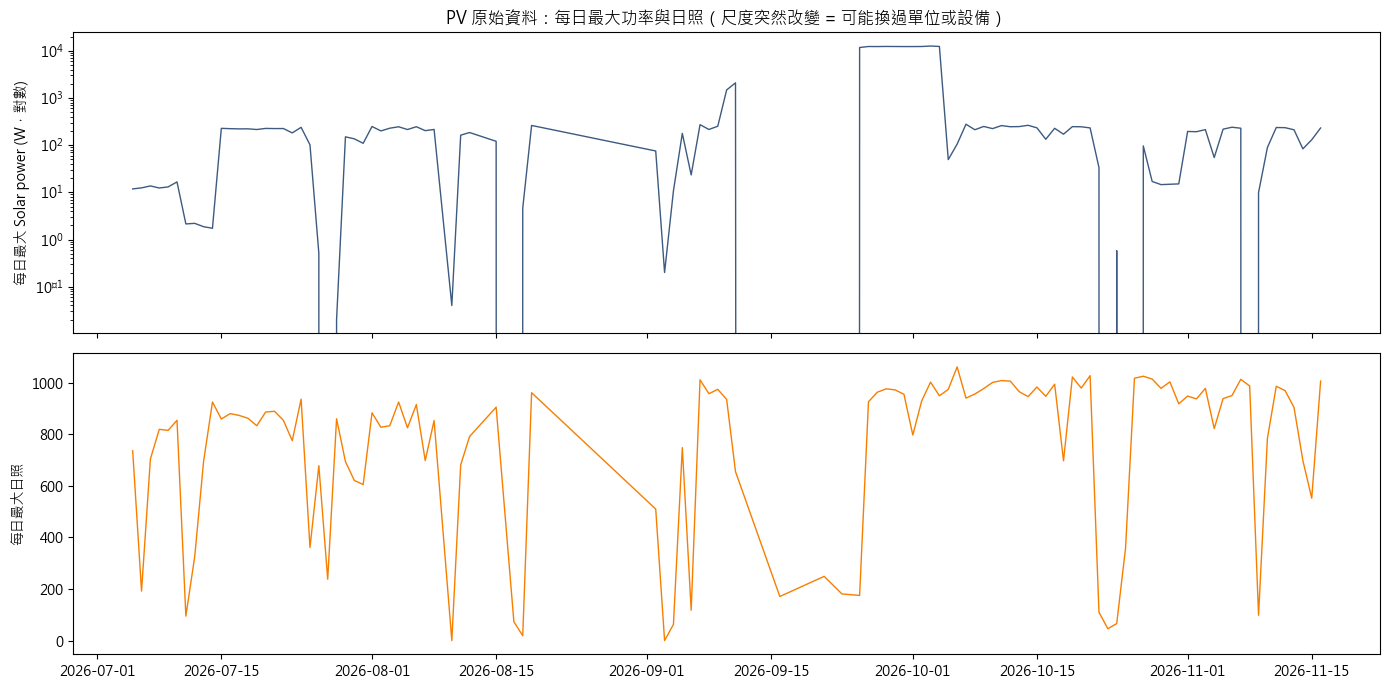

✓ 檢查結果已存：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\PV太陽光電\資料檢查\20261118_210541

[PV] PV_資料檢查　完成，耗時 0.1 分鐘
✓ 執行紀錄已存：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\PV太陽光電\執行紀錄\PV_資料檢查_20261118_2105.txt


In [28]:
with 記錄輸出('PV', 'PV_資料檢查'):
    ref = init_firebase(FIREBASE_CRED_JSON_PATH)
    pv_raw = solar_read_firebase()          # 只讀
    pv_check_table = pv_data_check(pv_raw)

### 執行：太陽光電多種 AI 模型公平比較（5 種子 × 研究版／部署版）

模型、公平規則和圖都和 ESS 相同；結果存到 `outputs_v13/PV太陽光電/公平比較/<時間>/`。沿用上一格（資料檢查）讀到的資料。

⚠ v11 起 PV 已加入新特徵、並調整 PV 衰退的注入時段（見 PV-1 函式格開頭的開關），所以數字不能直接和 v10 比。

In [29]:
with 記錄輸出('PV', 'PV_公平比較'):
    ref = init_firebase(FIREBASE_CRED_JSON_PATH)
    _raw = pv_raw if 'pv_raw' in globals() else solar_read_firebase()     # 沿用資料檢查格讀到的資料（只讀）
    pv_raw_df = solar_to_df(_raw)
    pv_zoo = pv_model_zoo(raw_df=pv_raw_df)

[PV] PV_公平比較　開始 2026-11-18 21:05:45

=== Firebase 初始化 ===
⚠ Firebase 已經初始化，刪除舊連接...
📊 專案 ID: essssimulation3
🔗 資料庫 URL: https://essssimulation3-default-rtdb.asia-southeast1.firebasedatabase.app/
✓ Firebase 連接成功!
  ⚠ 剔除疑似尖峰 / 不一致紀錄 1405 筆（10.02%）：相對日照異常高 1382、電流飽和327.67A 1271、超過裝置容量 749
✓ 太陽能資料：14027 筆有效紀錄 → 10min 平均後 12622 筆，2026-07-05 ~ 2026-11-16（缺漏時段直接略過，不補值）

   PV 太陽光電：多種 AI 模型公平比較

  ▶ PV｜研究版(含模擬特徵)｜種子 42
    特徵 41 → 清理後 33 個；交叉驗證 3 段（間隔 24 筆）；最終訓練 7485 筆（異常 616）、最後一段驗證 1325（異常 107）、測試 3787（異常 289）
    ── 調參（Optuna，每個模型 15 次）
    調參 Isolation Forest   CV PR-AUC 0.2865（13 次完成、2 次提前停止，7 秒）
    調參 LOF 局部離群因子         CV PR-AUC 0.1963（11 次完成、4 次提前停止，7 秒）
    調參 One-Class SVM      CV PR-AUC 0.1736（10 次完成、5 次提前停止，7 秒）
    調參 馬氏距離（Elliptic）     CV PR-AUC 0.2855（11 次完成、4 次提前停止，0 秒）
    調參 PCA 重建誤差           CV PR-AUC 0.4045（12 次完成、3 次提前停止，0 秒）
    調參 自編碼器 AE            CV PR-AUC 0.2954（8 次完成、7 次提前停止，30 秒）
    調參 邏輯迴歸               CV PR-AUC 0.9473（11 次完成、4 次提前停止，1 秒）
    調參 SVM（RBF）      

## B-3　EV 電動車

### 執行：啟動電動車歷史紀錄器（背景執行，只讀；建議最先執行，累積約一週）

In [30]:
ref = init_firebase(FIREBASE_CRED_JSON_PATH)
ev_hist = ev_collect_once()          # 先抓一次
ev_logger = start_ev_logger(interval_min=5)
# ⚠ 如果已經用下面『EV 獨立紀錄器』設定了 Windows 排程，就不要執行這格（避免兩邊同時寫同一個 CSV）
# 停止：stop_ev_logger()


=== Firebase 初始化 ===
⚠ Firebase 已經初始化，刪除舊連接...
📊 專案 ID: essssimulation3
🔗 資料庫 URL: https://essssimulation3-default-rtdb.asia-southeast1.firebasedatabase.app/
✓ Firebase 連接成功!
[21:34:47] EV 歷史 3 列（新增 0）→ d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\EV電動車\EV_history.csv
✓ EV 歷史紀錄器已啟動（每 5 分鐘只讀一次）；停止請執行 stop_ev_logger()


### 執行：EV 獨立紀錄器（v9 新增，建議；只要設定一次）

產生一個獨立的小程式，用 Windows 工作排程器每 5 分鐘執行一次。這樣關掉 Jupyter 也會繼續累積資料。執行後照畫面印出的步驟做。

⚠ **v13**：EV 歷史改存到 `outputs_v13/EV電動車/EV_history.csv`（第一次執行函式格時會自動把 v10 累積的歷史併進來，舊檔不修改）。如果你已經設定過 Windows 排程，**請再執行一次下面這格**，排程就會改寫到新位置（排程本身不用重設）。

In [31]:
write_ev_logger_script()

✓ 已產生：d:\260916數位孿生目前最終版計劃案代碼\ev_logger_standalone.py
          d:\260916數位孿生目前最終版計劃案代碼\ev_logger_every5min.bat

接下來（只要做一次）：
  1. 先在 notebook 執行 stop_ev_logger()（停掉 notebook 裡的紀錄器）
  2. 按開始 → 輸入 cmd → 開啟『命令提示字元』，貼上下面這一行後按 Enter：
     schtasks /Create /SC MINUTE /MO 5 /TN "EV_logger" /TR "\"d:\260916數位孿生目前最終版計劃案代碼\ev_logger_every5min.bat\"" /F
  3. 檢查：過 5 分鐘後執行 ev_logger_status()，或打開 outputs_v13/EV電動車/執行紀錄/EV_logger_排程.log
  停用排程：schtasks /Delete /TN "EV_logger" /F
  ※ 電腦睡眠時排程不會執行：設定 → 系統 → 電源 → 睡眠設為『永不』


### 執行：查看 EV 紀錄器現況（隨時可跑）

In [32]:
ev_logger_status()

EV 歷史：3 列（d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\EV電動車\EV_history.csv）
  charger_1：1 筆、0.0 天，最新 11-16 14:00（訓練需要 ≥ 500 筆且 ≥ 7 天）
  charger_2：1 筆、0.0 天，最新 11-16 14:00（訓練需要 ≥ 500 筆且 ≥ 7 天）
  charger_3：1 筆、0.0 天，最新 11-16 14:00（訓練需要 ≥ 500 筆且 ≥ 7 天）
⚠ EV_charger_data 已 55.6 小時沒有新資料，對方系統可能停止上傳，請聯絡負責的實驗室


,event_time,charger,name,current_a,voltage_v,soc,soh,max_temp_c,psu_current_a,load_current_a,output_on,battery_state,energy_flow,mode,dq_ok,dq_issues,message_id
0,2026-11-16 14:00:00,charger_1,動力輪組櫃,9.80,100.28,56,99,26,10.00,0.20,1,充電中,充電中：台電,自動雙向,True,NaN,charger-20261116-140000
1,2026-11-16 14:00:00,charger_2,電子負載櫃,9.86,100.56,66,99,26,9.95,0.09,1,充電中,充電中：台電,自動雙向,True,NaN,charger-20261116-140000
2,2026-11-16 14:00:00,charger_3,雙向直流負載櫃,-0.02,99.08,59,99,26,NaN,NaN,1,待機,待機,自動雙向,True,NaN,charger-20261116-140000


### 執行：電動車多種 AI 模型公平比較（累積足夠歷史後再執行）

模型、公平規則和圖都和 ESS 相同；結果存到 `outputs_v13/EV電動車/公平比較/<時間>/`。資料量不足時會自動略過。

In [33]:
with 記錄輸出('EV', 'EV_公平比較'):
    ev_zoo = ev_model_zoo()          # 讀 EV_history.csv；每櫃 ≥ 500 筆且 ≥ 7 天才會執行

[EV] EV_公平比較　開始 2026-11-18 21:35:51

   EV 電動車電池：多種 AI 模型公平比較
  charger_1：1 筆、0 天 ⊘ 未達 500 筆且 7 天
  charger_2：1 筆、0 天 ⊘ 未達 500 筆且 7 天
  charger_3：1 筆、0 天 ⊘ 未達 500 筆且 7 天
⊘ 資料量不足，請繼續累積歷史後再比較

[EV] EV_公平比較　完成，耗時 0.0 分鐘
✓ 執行紀錄已存：d:\260916數位孿生目前最終版計劃案代碼\outputs_v13\EV電動車\執行紀錄\EV_公平比較_20261118_2135.txt


## B-4　三個子系統總表

把 ESS、PV、EV 的比較合成總表：每個模型在每個子系統、每個情境的測試 F1 與事件 F1（多種子平均）。
存到 `outputs_v13/三子系統總表/<時間>/`：`單一模型F1_跨子系統熱圖.png`、`單一模型事件F1_跨子系統熱圖.png`、`各子系統最佳模型.csv`、`總結.txt`。還沒跑的子系統會自動略過。

In [34]:
with 記錄輸出('總表', '三子系統總表'):
    zoo_summary = zoo_cross_summary({'ESS': globals().get('ess_zoo'),
                                     'PV': globals().get('pv_zoo'),
                                     'EV': globals().get('ev_zoo')})

[總表] 三子系統總表　開始 2026-11-18 21:35:54
   多種 AI 模型比較總結：哪一種模型在哪個子系統表現最好（v13）

【ESS｜研究版】
  第一名：LightGBM（監督）F1 0.9825 ± 0.0049；事件 F1 0.9853
  與第一名差距在一個標準差內：LightGBM、隨機森林、XGBoost（臨界差異圖有統計檢定結果）
  監督 最佳：LightGBM 0.9825 ± 0.0049
  非監督 最佳：PCA 重建誤差 0.4335 ± 0.0194
  數位孿生（參考） 最佳：數位孿生 0.7995 ± 0.0131
  最佳組合（依驗證選）：隨機森林 + LightGBM［平均］ 0.9819 ± 0.0051（-0.0006 vs 最佳單一）

【ESS｜部署版】
  第一名：LightGBM（監督）F1 0.9478 ± 0.0093；事件 F1 0.9561
  與第一名差距在一個標準差內：LightGBM、XGBoost、隨機森林（臨界差異圖有統計檢定結果）
  監督 最佳：LightGBM 0.9478 ± 0.0093
  非監督 最佳：PCA 重建誤差 0.2695 ± 0.0346
  數位孿生（參考） 最佳：數位孿生 0.0618 ± 0.0275
  最佳組合（依驗證選）：隨機森林 + XGBoost［平均］ 0.9433 ± 0.0115（-0.0045 vs 最佳單一）

【PV｜研究版】
  第一名：隨機森林（監督）F1 0.9684 ± 0.0140；事件 F1 0.9702
  與第一名差距在一個標準差內：隨機森林、數位孿生、邏輯迴歸、LightGBM（臨界差異圖有統計檢定結果）
  監督 最佳：隨機森林 0.9684 ± 0.0140
  非監督 最佳：自編碼器 AE 0.6357 ± 0.1045
  數位孿生（參考） 最佳：數位孿生 0.9604 ± 0.0064
  最佳組合（依驗證選）：LightGBM + 隨機森林［平均］ 0.9582 ± 0.0164（-0.0103 vs 最佳單一）

【PV｜部署版】
  第一名：隨機森林（監督）F1 0.9399 ± 0.0128；事件 F1 0.9414
  監督 最佳：隨機森林 0.9399 ± 0.0128
  非監督 最佳：

# 第三部分：現場運行（三套都訓練好之後才開）

- 只要模型已存在資料夾中，Kernel 重開後不需重新訓練：重跑第一部分的函式格即可。
- ESS、PV、EV 的即時監測都是「一直輪詢直到按 ■」，同一個 notebook 一次只能跑一格；要同時跑請複製 notebook 分開開啟。
- 現場紀錄分別存在 `outputs_v13/ESS儲能/現場運行紀錄/`、`outputs_v13/PV太陽光電/現場運行紀錄/`、`outputs_v13/EV電動車/現場運行紀錄/`。

**v13**：現場運行用的是舊版 Hybrid 部署模型。如果還沒在 v13 跑過最後的「附錄：舊版 Hybrid 訓練」，會自動改用 v10 的模型（只讀，並印出提醒）；想用 v13 的資料重新訓練現場模型，就先跑附錄。

## C-0　載入已訓練模型（快速恢復也從這裡開始）

Kernel 重開後：先執行第一部分所有函式格（不用重新訓練），再執行這格。會載入**最新一次**訓練的 ESS 部署版模型。

In [35]:
_p = resolve_model_bundle()
model_bundle = joblib.load(_p)
if model_bundle.get('use_synthetic_diagnostic_features'):
    raise ValueError("這份是研究版模型（含模擬特徵），不能用於現場運行")
print(f"✓ 已載入 ESS 部署版模型：{_p}")
print(f"  模型檔時間：{datetime.fromtimestamp(Path(_p).stat().st_mtime):%Y-%m-%d %H:%M}")

⚠ v13 尚未訓練 ESS 部署模型，暫用 v10 的模型（只讀取，不會修改）：d:\260916數位孿生目前最終版計劃案代碼\outputs_ESS儲能\部署_僅真實欄位\20261117_235700\ems_model_bundle.joblib
✓ 已載入 ESS 部署版模型：d:\260916數位孿生目前最終版計劃案代碼\outputs_ESS儲能\部署_僅真實欄位\20261117_235700\ems_model_bundle.joblib
  模型檔時間：2026-11-17 23:58


## C-1　ESS 儲能

## 執行區塊三：Modbus 現場診斷（強烈建議在啟動即時監測前先跑這格）

**這一格完全不需要 Firebase，也不需要先訓練模型，隨時可以獨立執行。**

先確認：
1. TCP 是否連得上
2. FC03 是否收到有效 response
3. registers 原始值 + 解碼後的實際 kW / % 數值是否合理

主表、儲能電表應該已經可以直接成功（已用現場數值驗證過）。
EMS 預設是停用狀態，這格只會顯示「⊘ 已停用」，不會嘗試連線。
若要重新測試 EMS，把上面「Modbus 端點設定」那格的 `EMS_CFG['enabled']` 改成 `True` 再重跑這一格即可。


In [ ]:
def run_modbus_diagnostics():
    """單純測 TCP + Modbus 讀值是否正常，不寫 Firebase、不跑模型。"""
    print("\n" + "=" * 70)
    print("   Modbus 現場診斷")
    print("=" * 70)

    main_client, ess_client, ess_soc_client, ems_client = connect_all_modbus_clients()

    print(f"\n--- {MAIN_METER_CFG['name']} {MAIN_METER_CFG['ip']}:{MAIN_METER_CFG['port']} ---")
    try:
        value, regs = read_meter_power_kw(main_client, MAIN_METER_CFG)
        print(f"  ✓ FC03 0x{METER_POWER_SPEC['address']:04X} registers={regs} → {value:.3f} kW（= 調節後負載 after_load）")
        main_val = value
    except Exception as e:
        print(f"  ✗ {type(e).__name__}: {e}")

    print(f"\n--- {ESS_METER_CFG['name']} {ESS_METER_CFG['ip']}:{ESS_METER_CFG['port']} ---")
    try:
        value, regs = read_meter_power_kw(ess_client, ESS_METER_CFG)
        print(f"  ✓ FC03 0x{METER_POWER_SPEC['address']:04X} registers={regs} → {value:.3f} kW（= ESS功率）")
        if 'main_val' in locals():
            print(f"  → 調度前(原始負載) = 調節後 + ESS = {main_val:.2f} + ({value:.2f}) = {main_val + value:.2f} kW")
    except Exception as e:
        print(f"  ✗ {type(e).__name__}: {e}")

    print(f"\n--- {ESS_SOC_CFG['name']} {ESS_SOC_CFG['ip']}:{ESS_SOC_CFG['port']} ---")
    if not ESS_SOC_CFG.get('enabled', False):
        print("  ⊘ 已停用（ESS_SOC_CFG['enabled']=False）")
    else:
        try:
            soc, p_kw = read_ess_soc_power(ess_soc_client, ESS_SOC_CFG)
            print(f"  ✓ FC03 addr {ESS_SOC_SPEC['address']} → SOC={soc:.2f}%，"
                  f"FC03 addr {ESS_POWER_SPEC['address']} → 功率={p_kw:.3f} kW")
        except Exception as e:
            print(f"  ✗ {type(e).__name__}: {e}")

    print(f"\n--- {EMS_CFG['name']} {EMS_CFG['ip']}:{EMS_CFG['port']} ---")
    if not EMS_CFG.get('enabled', False):
        print("  ⊘ 已停用（EMS_CFG['enabled']=False）")
    else:
        try:
            status = read_ems_status(ems_client, EMS_CFG)
            print(f"  ✓ ess_power={status['ess_power']:.3f} kW, "
                  f"soc={status['soc']:.1f}%, soh={status['soh']:.1f}%")
        except Exception as e:
            print(f"  ✗ {type(e).__name__}: {e}")

    close_all_modbus_clients(main_client, ess_client, ess_soc_client, ems_client)
    print("\n診斷完成。")


run_modbus_diagnostics()


## 執行區塊四：【階段二】線上即時運行

**執行這格之前，強烈建議先跑過上面的「Modbus 現場診斷」格，確認主表/儲能電表/儲能主機(SOC) 都 GOOD。**

### v5：SOC 改用邱老師實驗室驗證過的來源，EMS 程式碼保留但停用

`ESS_SOC_CFG['enabled'] = True`：SOC 從 `192.168.1.200:502` 位址 199 讀取（跟邱老師實驗室
`ems_other_laboratory_renew.py` 用的是同一套後台、已驗證可穩定讀到）。

`EMS_CFG['enabled'] = False`：**EMS 相關的程式碼（`EMS_KAC50DP_LEVEL1_PROFILE`、
`read_ems_status`、EMS 連線）完全沒有刪除、原封不動保留**，之後若排查通了原本的 EMS，
只要把這個布林值改成 `True`，它讀到的值會優先覆蓋 `ess_power`/`soc`，其他程式碼都不用動。

在目前設定下：
- **主表、儲能電表、儲能主機(SOC) 照常讀取，正常寫入 Firebase**（`before_load` / `ess_power` / `after_load` / `soc`）。
- 只有在 `ESS_SOC_CFG` 也讀取失敗、且 EMS 也停用時，`soc` 才會維持 `None`，
  寫進 Firebase 時明確標成 `EMS_DISABLED`，不會偷偷補 0 或沿用上一筆冒充。
- 有 SOC 且累積資料足夠時才會跑模型推論；沒有 SOC 時 `anomaly_type` 標成 `EMS_DISABLED_NO_MODEL`。

### 執行

```python
ref = init_firebase(FIREBASE_CRED_JSON_PATH)

run_realtime_loop(
    ref,
    model_bundle=model_bundle,
    poll_interval_sec=60,
    align_to_clock=True,
    align_second_offset=10,
    max_iterations=None,        # 持續跑，Ctrl+C（或 Jupyter 的 Stop 方塊）中止
    upload_to_firebase=True,    # 主表/儲能電表/儲能主機(SOC) 資料正常寫入 Firebase
)
```


**v9**：啟動時會先從 Firebase `ems_data` 預載最近 20 分鐘內延續的現場資料（只讀），上次運行剛停不久就重開時，不用再等 30 分鐘。不想預載就把 `warm_start=False` 加進下一格。

In [ ]:
# =====================================================================
# 【貼在新的一格，放在「執行區塊四」上方，先執行一次】
# 現場即時運行紀錄圖：跑多久就畫多久
#   - 自動從 Firebase 讀回「這次運行」的資料（只讀取，不寫入、不刪除）
#   - 用同一個部署版 model_bundle 重播推論，得到每分鐘的混合分數
#   - 跨日運行也可以（例如 23:30 跑到隔天 01:00）
# =====================================================================
from collections import deque
from datetime import datetime, timedelta
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.dates as mdates


def plot_live_run(ref, model_bundle, run_start, run_end, poll_sec=60, save=True):
    # ---------- 1. 讀 Firebase：只取這次運行的時間範圍 ----------
    t0 = run_start.replace(second=0, microsecond=0)
    t1 = run_end.replace(second=0, microsecond=0)
    rows, d = [], t0.date()
    while d <= t1.date():
        day = d.strftime('%Y-%m-%d')
        raw = ref.child('ems_data').child(day).get() or {}
        for k, v in raw.items():
            if not isinstance(v, dict) or v.get('source', 'live') != 'live':
                continue
            ts = pd.Timestamp(f'{day} {k}')
            if t0 <= ts <= t1:
                rows.append(dict(v, timestamp=ts))
        d += timedelta(days=1)
    if not rows:
        print('⚠ 這段時間在 Firebase 找不到即時資料（upload_to_firebase 是否為 True？）')
        return None
    df = pd.DataFrame(rows).sort_values('timestamp').reset_index(drop=True)
    for c in ['after_load', 'before_load', 'ess_power', 'soc']:
        df[c] = pd.to_numeric(df.get(c), errors='coerce')

    # ---------- 2. 重播推論（與即時迴圈相同的 buffer 規則） ----------
    res_min = pd.Timedelta(model_bundle.get('resample_to', '15min')).total_seconds() / 60
    min_raw = max(5, int(res_min * 60 * 2 / poll_sec))
    buf, scores, states = deque(maxlen=400), [], []
    for _, r in df.iterrows():
        rec = r.to_dict(); rec['timestamp'] = r['timestamp'].to_pydatetime()
        ok = all(pd.notna(rec.get(c)) for c in ['after_load', 'ess_power', 'soc'])
        if ok:
            buf.append(rec)
        if not ok:
            scores.append(np.nan); states.append('FAILED')
        elif len(buf) < min_raw:
            scores.append(np.nan); states.append('ACCUMULATING')
        else:
            is_a, _, sc = infer_anomaly(model_bundle, buf)
            scores.append(sc); states.append('ANOMALY' if is_a else 'NORMAL')
    df['hybrid_score'], df['state'] = scores, states
    df['mode'] = np.select([df['ess_power'] > 2, df['ess_power'] < -2], ['放電', '充電'], '待機')

    # ---------- 3. 摘要 ----------
    cnt = df['state'].value_counts()
    n_acc, n_inf = cnt.get('ACCUMULATING', 0), cnt.get('NORMAL', 0) + cnt.get('ANOMALY', 0)
    n_alarm, n_fail = cnt.get('ANOMALY', 0), cnt.get('FAILED', 0)
    span = f"{df['timestamp'].iloc[0]:%Y-%m-%d %H:%M}–{df['timestamp'].iloc[-1]:%H:%M}"
    print(f"\n=== 現場運行摘要（{span}）===")
    print(f"輪詢 {len(df)} 次｜累積中 {n_acc}｜已推論 {n_inf}｜告警 {n_alarm}｜讀值失敗 {n_fail}")
    inf = df[df['state'].isin(['NORMAL', 'ANOMALY'])]
    if len(inf):
        print(f"混合分數 {inf['hybrid_score'].min():.3f}–{inf['hybrid_score'].max():.3f}（門檻 1.0）")
    for m, g in df.groupby('mode'):
        print(f"{m} {len(g)} 筆｜ESS 平均 {g['ess_power'].mean():.2f} kW｜after {g['after_load'].mean():.1f} kW｜"
              f"before {g['before_load'].mean():.1f} kW｜SoC {g['soc'].iloc[0]:.1f}% → {g['soc'].iloc[-1]:.1f}%")
    dis = df[df['mode'] == '放電']
    if len(dis) > 5 and dis['soc'].iloc[0] - dis['soc'].iloc[-1] > 5:
        e = dis['ess_power'].sum() * poll_sec / 3600
        ds = dis['soc'].iloc[0] - dis['soc'].iloc[-1]
        print(f"放電 ≈ {e:.1f} kWh、SoC 降 {ds:.1f} 點 → 推估容量 ≈ {e / (ds / 100):.0f} kWh")
    else:
        print('本次無足夠放電（SoC 降不到 5 點），不推估容量')
    print(f"before_load 為負：{(df['before_load'] < 0).sum()} 筆")

    # ---------- 4. 出圖 ----------
    t = df['timestamp']
    fig, ax = plt.subplots(4, 1, figsize=(13, 10), sharex=True,
                           gridspec_kw={'height_ratios': [1.3, 1, 1, 1]})
    ax[0].plot(t, df['after_load'], color='#2F6FDE', lw=1.6, label='after_load（主表量測，調節後）')
    ax[0].plot(t, df['before_load'], color='#E0823A', lw=1.4, ls='--', label='before_load = after + ESS（調度前）')
    ax[0].set_ylabel('負載 (kW)'); ax[0].legend(loc='upper left', fontsize=9)
    ax[1].plot(t, df['ess_power'], color='#2E8B57', lw=1.6)
    ax[1].axhline(0, color='gray', lw=0.8); ax[1].set_ylabel('儲能功率 (kW)\n正 = 放電')
    ax[2].plot(t, df['soc'], color='#7B4FBF', lw=1.6); ax[2].set_ylabel('SoC (%)')
    soc_rng = df['soc'].max() - df['soc'].min()
    if soc_rng < 2:   # SoC 幾乎不變時，避免軸被放大成雜訊
        m = df['soc'].mean(); ax[2].set_ylim(m - 2, m + 2)
    ax[3].plot(t, df['hybrid_score'], color='#D9661A', lw=1.6, marker='o', ms=3, label='混合分數（正規化）')
    ax[3].axhline(1.0, color='red', ls='--', lw=1, label='告警門檻 = 1')
    alarm = df[df['state'] == 'ANOMALY']
    if len(alarm):
        ax[3].scatter(alarm['timestamp'], alarm['hybrid_score'], color='red', zorder=5, label='告警')
    ax[3].set_ylim(0, max(1.2, np.nanmax(df['hybrid_score'].values) * 1.1 if n_inf else 1.2))
    ax[3].set_ylabel('混合分數'); ax[3].legend(loc='upper left', fontsize=9)
    acc = df[df['state'] == 'ACCUMULATING']
    if len(acc):
        for a in ax:
            a.axvspan(acc['timestamp'].iloc[0], acc['timestamp'].iloc[-1], color='#DDDDDD', alpha=0.5, lw=0)
        ax[3].text(acc['timestamp'].iloc[len(acc) // 2], 0.6, f'累積資料中\n（前 {min_raw} 筆不推論）',
                   ha='center', va='center', fontsize=9, color='#555555')
    for a in ax: a.grid(alpha=0.3)
    ax[3].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    fig.suptitle(f'現場即時運行紀錄（{span}，部署版模型，{poll_sec // 60} 分鐘輪詢）\n'
                 f'輪詢 {len(df)} 次｜累積 {n_acc}｜推論 {n_inf}｜告警 {n_alarm}', fontsize=13)
    fig.tight_layout()
    if save:
        folder = Path(OUT('現場運行紀錄')); folder.mkdir(exist_ok=True)
        tag = f"{df['timestamp'].iloc[0]:%Y%m%d_%H%M}-{df['timestamp'].iloc[-1]:%H%M}"
        png = folder / f'live_run_{tag}.png'
        fig.savefig(png, dpi=200, bbox_inches='tight')
        df.drop(columns=['modbus_status'], errors='ignore').to_csv(folder / f'live_run_{tag}.csv',
                                                                  index=False, encoding='utf-8-sig')
        print(f'✓ 圖：{png}\n✓ 資料：{folder / f"live_run_{tag}.csv"}')
    plt.show()
    return df


print('✓ plot_live_run 已定義')


# =====================================================================
# 【執行區塊四改成下面這樣】按 Stop 中止後會自動出圖
# =====================================================================
# ref = init_firebase(r"D:\260916數位孿生目前最終版計劃案代碼\essssimulation3-firebase-adminsdk-fbsvc-6b270aedbf.json")
# RUN_START = datetime.now()
# try:
#     run_realtime_loop(ref, model_bundle=model_bundle, poll_interval_sec=60,
#                       align_to_clock=True, align_second_offset=10,
#                       max_iterations=None, upload_to_firebase=True)
# finally:
#     RUN_END = datetime.now()
#     live_df = plot_live_run(ref, model_bundle, RUN_START, RUN_END)
#
# 想補畫某一段過去的運行（例如今天 12:11–13:16）：
# live_df = plot_live_run(ref, model_bundle, datetime(2026, 11, 14, 12, 11), datetime(2026, 11, 14, 13, 16))

In [ ]:
from datetime import datetime

ref = init_firebase(r"D:\260916數位孿生目前最終版計劃案代碼\essssimulation3-firebase-adminsdk-fbsvc-6b270aedbf.json")

RUN_START = datetime.now()          # 記下開始時間
try:
    run_realtime_loop(
        ref,
        model_bundle=model_bundle,
        poll_interval_sec=60,
        align_to_clock=True,
        align_second_offset=10,
        max_iterations=None,
        upload_to_firebase=True,     # 一定要 True，出圖要從 Firebase 讀資料
    )
finally:
    RUN_END = datetime.now()        # 按 Stop 後記下結束時間
    live_df = plot_live_run(ref, model_bundle, RUN_START, RUN_END)   # 自動出圖

## C-2　PV 太陽光電

### 執行：太陽光電近期評分（部署版，可重複執行）

In [ ]:
recent = solar_score_recent(last_n=300)      # 最近約 50 小時
recent.tail(10)

### 執行：太陽光電即時監測（每分鐘輪詢；按 ■ 中斷停止）

In [ ]:
ref = init_firebase(FIREBASE_CRED_JSON_PATH)
pv_log = pv_live_monitor(poll_sec=60, run_minutes=None)   # run_minutes=120 → 跑 2 小時自動停
plot_pv_live(pv_log)

## C-3　EV 電動車

### 執行：電動車即時監測（每分鐘輪詢；同時累積歷史；按 ■ 中斷停止）

In [ ]:
ref = init_firebase(FIREBASE_CRED_JSON_PATH)
stop_ev_logger()                                           # 若背景紀錄器在跑，先停掉避免重複讀取
ev_log = ev_live_monitor(poll_sec=60, run_minutes=None)
plot_ev_live(ev_log)

# 附錄：舊版 Hybrid 訓練與多種子實驗（只有現場運行需要）

論文的模型比較已改用第二部分的公平比較，這裡的 fig1～fig9、PV／EV 的「各模型比較」圖**不再用於結論**。
只有想用 v13 的資料重新訓練現場運行模型（ESS／PV／EV 部署版）時才需要執行。結果同樣放在 `outputs_v13/` 底下各子系統的 `研究_含模擬特徵/`、`部署_僅真實欄位/`、`多種子實驗/`。

## 附錄 ESS：執行區塊二：【階段一】離線訓練
第一次執行建議先把 `use_firebase=False`，確認訓練流程跑得通、模型存檔成功後，
再視需要打開 Firebase 上傳（需要先在上面把 `FIREBASE_CRED_JSON_PATH` 設成你的金鑰路徑）。

v4 預設 `use_synthetic_diagnostic_features=False`（真實欄位限定），跟現場目前
「EMS 停用、沒有即時 SOH/cell_v_diff」的狀況一致。


**★ 這格會訓練兩份模型：**
- **① 研究版**（含模擬電池診斷特徵）：論文實驗結果用，存在 `outputs_v13/ESS儲能/研究_含模擬特徵/`
- **② 部署版**（僅真實欄位）：現場讀不到 SOH / cell 電壓差 / 自放電率，【階段二】即時運行使用這份，存在 `outputs_v13/ESS儲能/部署_僅真實欄位/`
- 兩份模型都不使用契約容量相關特徵（設定值，且歷史 250 kW / 163.4 kW 不一致）


In [ ]:
with 記錄輸出('ESS', 'ESS_訓練_研究版與部署版'):      # 畫面輸出同步存到 ESS 資料夾的「執行紀錄/」
    # ① 研究版（論文實驗用）：含模擬電池診斷特徵 → 結果存到 outputs_v13/ESS儲能/研究_含模擬特徵/
    df, hybrid_result, final_metrics, multiclass_result, research_bundle = main_stage1_offline_training(
        csv_folder=CSV_FOLDER,
        anomaly_rate=0.08,
        resample_to='15min',
        auto_feature_selection=True,
        use_firebase=False,      # ← 需要更新儀表板的歷史資料時才改成 True（會覆寫 ems_data 同時間點的歷史筆數）
        upload_to_fb=False,      # ← 同上；只重新訓練、存模型時保持 False，不會寫入 Firebase
        use_synthetic_diagnostic_features=True,
        out_subdir='研究_含模擬特徵',
    )

    # ② 部署版（現場即時運行用）：只用現場讀得到的真實欄位 → 存到 outputs_v13/ESS儲能/部署_僅真實欄位/
    #    現場讀不到 SOH / cell 電壓差 / 自放電率，所以即時運行一定要用這份模型
    df_dep, hybrid_dep, metrics_dep, multiclass_dep, model_bundle = main_stage1_offline_training(
        csv_folder=CSV_FOLDER,
        anomaly_rate=0.08,
        resample_to='15min',
        auto_feature_selection=True,
        use_firebase=False,      # 部署版不重複上傳
        upload_to_fb=False,
        use_synthetic_diagnostic_features=False,
        out_subdir='部署_僅真實欄位',
    )
    print(f"\n✓ 【階段二】即時運行將使用部署版模型: {resolve_model_bundle()}")

## 附錄 ESS：執行區塊二之二：5 個隨機種子重複實驗（確認 Hybrid 的優勢不是單次運氣）

- 用 5 組不同的種子重新注入模擬異常（異常位置與數值都不同），研究版、部署版各完整重跑 5 次
- 特徵數 k 沿用上面正式訓練選出的值；門檻、權重仍只用驗證集決定
- 輸出：各模型 **平均 ± 標準差**、Hybrid 贏過 XGB 的次數、多分類 Macro F1
- 結果存到 `outputs_v13/ESS儲能/多種子實驗/`，**不覆蓋**正式訓練的圖與模型、**不寫 Firebase**
- ⏱ 約 15～30 分鐘（每次都重新做超參數尋優）


In [ ]:
# ======================================================================
# 多種子重複實驗：用 5 組不同的隨機種子重新「注入模擬異常」並完整重跑訓練，
# 報告各模型的 平均 ± 標準差，確認 Hybrid 的優勢不是單次運氣。
#   • 每個種子：異常的位置與數值都不同（augment seed），其餘流程與正式訓練完全相同
#   • 特徵數 k 固定沿用正式訓練選出的值，所有門檻/權重仍只用驗證集決定
#   • 結果另存到 outputs_v13/ESS儲能/多種子實驗/，不覆蓋正式訓練的圖與模型
# ======================================================================
import contextlib, io
from sklearn.metrics import average_precision_score

def _prepare_dataset(df_real, seed, use_synth, anomaly_rate=0.08):
    """與 main_stage1 相同的資料準備流程（只換異常注入的種子）"""
    with contextlib.redirect_stdout(io.StringIO()):
        df = augment_real_data_with_synthetic_anomalies(df_real, anomaly_rate=anomaly_rate, seed=seed)
        dfp = engineer_features_advanced(df)
        fc = select_features_for_if(dfp, use_synth)
        dfp = clean_nan_inf(dfp, fc)
        fc = select_features_for_if(dfp, use_synth)
    if use_synth:
        tmap = {'normal': 0, 'cell_inconsistency': 1, 'internal_short': 2, 'soh_degradation': 3}
    else:   # 部署版：真實欄位看不見的兩類視為正常（與正式訓練相同）
        inv = dfp['anomaly_type'].isin(['cell_inconsistency', 'internal_short'])
        dfp.loc[inv, 'is_anomaly'] = 0
        dfp.loc[inv, 'anomaly_type'] = 'normal'
        tmap = {'normal': 0, 'soh_degradation': 1}
    X, y = dfp[fc].values, dfp['is_anomaly'].values
    ym = dfp['anomaly_type'].map(tmap).fillna(0).astype(int).values
    s = int(len(X) * 0.7)
    names = [k for k, _ in sorted(tmap.items(), key=lambda kv: kv[1])]
    return X[:s], X[s:], y[:s], y[s:], ym[:s], ym[s:], fc, names


def run_multi_seed_experiment(csv_folder, k_research, k_deploy,
                              seeds=(42, 101, 202, 303, 404), resample_to='15min'):
    global NEW_OUT
    base_out = NEW_OUT
    out_dir = new_run_dir(base_out / '多種子實驗')         # v9：每次一個時間戳資料夾
    (out_dir / '_暫存').mkdir(parents=True, exist_ok=True)

    with contextlib.redirect_stdout(io.StringIO()):
        df_real = load_historical_csv(csv_folder, resample_to=resample_to)

    rows, mc_rows = [], []
    t_all = time.time()
    _show = plt.show
    plt.show = lambda *a, **k: plt.close('all')          # 重複實驗時不顯示圖
    NEW_OUT = out_dir / '_暫存'                            # 過程中的圖存到暫存資料夾，不覆蓋正式結果
    try:
        for mode, use_synth, k in [('研究版(含模擬特徵)', True, k_research), ('部署版(僅真實欄位)', False, k_deploy)]:
            for seed in seeds:
                t0 = time.time()
                Xtr, Xte, ytr, yte, ymtr, ymte, fc, names = _prepare_dataset(df_real, seed, use_synth)
                with contextlib.redirect_stdout(io.StringIO()):
                    hr = hybrid_detector_optimized(Xtr, ytr, Xte, yte, fc, auto_k=False, manual_k=k)
                    mc = train_multiclass_diagnostics(Xtr, ymtr, Xte, ymte, fc, optimal_k=k, class_names=names)
                for m, met in hr['all_metrics'].items():
                    rows.append({'模式': mode, 'seed': seed, '模型': m, 'F1': met['f1'],
                                 'Precision': met['precision'], 'Recall': met['recall']})
                rows.append({'模式': mode, 'seed': seed, '模型': 'Hybrid PR-AUC',
                             'F1': average_precision_score(yte, hr['combined_score']),
                             'Precision': np.nan, 'Recall': np.nan})
                soh = mc.get('class_report', {}).get('soh_degradation', {})
                mc_rows.append({'模式': mode, 'seed': seed, '選用模型': mc['model_name'],
                                'Macro F1': mc['f1_macro'], 'Accuracy': mc['accuracy'],
                                '健康度衰退 Recall': soh.get('recall', np.nan)})
                h, x = hr['all_metrics']['Hybrid']['f1'], hr['all_metrics']['XGB']['f1']
                print(f"  ✓ {mode} seed={seed:<4d}  Hybrid F1={h:.4f}  XGB F1={x:.4f}  "
                      f"差={h - x:+.4f}  多分類 MacroF1={mc['f1_macro']:.4f}  ({time.time() - t0:.0f}s)")
    finally:
        plt.show = _show
        NEW_OUT = base_out

    res, mres = pd.DataFrame(rows), pd.DataFrame(mc_rows)
    L = []
    P = L.append
    P('=' * 70); P(f'   多種子重複實驗（seeds = {list(seeds)}，共 {len(seeds)} 次）'); P('=' * 70)
    order = ['Hybrid', 'XGB', 'LGBM', 'RF', 'Ensemble', 'Twin', 'SOC物理殘差', 'AE', 'PCA', 'IF', 'IF(僅正常)']
    for mode in res['模式'].unique():
        r = res[res['模式'] == mode]
        P(f'\n【{mode}】二元檢測（平均 ± 標準差）')
        g = r.groupby('模型')[['F1', 'Precision', 'Recall']].agg(['mean', 'std'])
        P(f"  {'模型':14s}{'F1':>18s}{'Precision':>18s}{'Recall':>18s}")
        for m in [o for o in order if o in g.index]:
            P(f"  {m:14s}" + ''.join(f"{g.loc[m, (c, 'mean')]:10.4f} ± {g.loc[m, (c, 'std')]:.4f}"
                                     for c in ['F1', 'Precision', 'Recall']))
        pa = r[r['模型'] == 'Hybrid PR-AUC']['F1']
        P(f"  Hybrid PR-AUC = {pa.mean():.4f} ± {pa.std():.4f}")
        piv = r.pivot(index='seed', columns='模型', values='F1')
        for rival in ['XGB', 'Ensemble', 'Twin']:
            d = piv['Hybrid'] - piv[rival]
            P(f"  Hybrid − {rival:9s}: F1 差 = {d.mean():+.4f} ± {d.std():.4f}，Hybrid 較佳 {int((d > 0).sum())}/{len(d)} 次、"
              f"平手 {int((d == 0).sum())} 次")
        mr = mres[mres['模式'] == mode]
        P(f'\n【{mode}】多分類診斷')
        P(f"  Macro F1 = {mr['Macro F1'].mean():.4f} ± {mr['Macro F1'].std():.4f}｜"
          f"健康度衰退 Recall = {mr['健康度衰退 Recall'].mean():.4f} ± {mr['健康度衰退 Recall'].std():.4f}")
        P('  各次選用模型: ' + ', '.join(f"seed{s}={m}" for s, m in zip(mr['seed'], mr['選用模型'])))
    P(f'\n總耗時 {(time.time() - t_all) / 60:.1f} 分鐘')
    text = '\n'.join(L)
    print('\n' + text)

    res.to_csv(out_dir / 'multi_seed_binary.csv', index=False, encoding='utf-8-sig')
    mres.to_csv(out_dir / 'multi_seed_multiclass.csv', index=False, encoding='utf-8-sig')
    (out_dir / 'multi_seed_report.txt').write_text(text, encoding='utf-8')

    # 圖：各模型 F1 平均 ± 標準差（兩種模式並排）
    show = ['IF', 'Twin', 'RF', 'XGB', 'LGBM', 'Ensemble', 'Hybrid']
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for ax, mode in zip(axes, res['模式'].unique()):
        g = res[(res['模式'] == mode) & res['模型'].isin(show)].groupby('模型')['F1'].agg(['mean', 'std']).reindex(show)
        colors = ['#6366f1', '#06b6d4', '#10b981', '#f59e0b', '#ef4444', '#64748b', '#f97316']
        ax.bar(show, g['mean'], yerr=g['std'], capsize=5, color=colors, edgecolor='white')
        for i_, (mu, sd) in enumerate(zip(g['mean'], g['std'])):
            ax.text(i_, mu + (sd if sd == sd else 0) + 0.02, f'{mu:.3f}', ha='center', fontsize=9, fontweight='bold')
        ax.set_ylim(0, 1.15); ax.set_ylabel('F1 (mean ± std)', fontweight='bold')
        ax.set_title(f'{mode}：{len(seeds)} 個種子', fontweight='bold')
        ax.grid(axis='y', alpha=0.25); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    plt.tight_layout()
    plt.savefig(out_dir / 'fig9_multi_seed_f1.png', dpi=150, bbox_inches='tight')
    plt.show()
    mark_latest(base_out / '多種子實驗', out_dir)
    print(f"\n✓ 多種子結果已存到: {out_dir}")
    print("   multi_seed_report.txt / multi_seed_binary.csv / multi_seed_multiclass.csv / fig9_multi_seed_f1.png")
    return res, mres


with 記錄輸出('ESS', 'ESS_多種子實驗'):      # 畫面輸出同步存到 ESS 資料夾的「執行紀錄/」
    # 執行（需先跑完上面的「執行區塊二」）
    ms_binary, ms_multiclass = run_multi_seed_experiment(
        CSV_FOLDER,
        k_research=hybrid_result['optimal_k'],   # 研究版正式訓練選出的特徵數
        k_deploy=hybrid_dep['optimal_k'],        # 部署版正式訓練選出的特徵數
        seeds=(42, 101, 202, 303, 404),
    )

## 附錄 PV：執行：太陽光電訓練（研究版＋部署版；只讀 solar_data_from_cycu）


In [ ]:
with 記錄輸出('PV', 'PV_訓練_研究版與部署版'):      # 畫面輸出同步存到 PV 資料夾的「執行紀錄/」
    ref = init_firebase(FIREBASE_CRED_JSON_PATH)
    _raw = pv_raw if 'pv_raw' in globals() else None      # 沿用資料檢查格讀到的資料
    pv_bundles, pv_raw_df = main_pv_training(seed=42, raw=_raw)   # 每次存到 研究_含模擬特徵/<時間>/、部署_僅真實欄位/<時間>/

## 附錄 PV：執行：太陽光電多種子重複實驗（5 組種子 × 2 情境，約數十分鐘）


In [ ]:
with 記錄輸出('PV', 'PV_多種子實驗'):      # 畫面輸出同步存到 PV 資料夾的「執行紀錄/」
    pv_seed_df, pv_seed_summary = pv_multi_seed(raw_df=pv_raw_df)     # 沿用上一格讀到的資料，不重複讀取

## 附錄 EV：執行：電動車訓練（研究版＋部署版；累積足夠歷史後再執行）


In [ ]:
with 記錄輸出('EV', 'EV_訓練_研究版與部署版'):      # 畫面輸出同步存到 EV 資料夾的「執行紀錄/」
    ev_bundles = main_ev_training(seed=42)

## 附錄 EV：執行：電動車多種子重複實驗（累積足夠歷史後再執行）


In [ ]:
with 記錄輸出('EV', 'EV_多種子實驗'):      # 畫面輸出同步存到 EV 資料夾的「執行紀錄/」
    ev_seed_results = ev_multi_seed()

# 工具（平常不用執行）

In [ ]:
# ⚠ 刪除 ems_data 某一天資料的工具格（預設『不會』刪除任何東西）
#   只會刪 ems_data/<DELETE_DATE>，絕不碰 solar_data_from_cycu、EV_charger_data 等其他節點
#   真的要刪：把 DELETE_DATE 改成要刪的日期，並把 CONFIRM_DELETE 改成 True 再執行
DELETE_DATE = '2026-11-14'
CONFIRM_DELETE = False
if CONFIRM_DELETE:
    ref = init_firebase(FIREBASE_CRED_JSON_PATH)
    ref.child('ems_data').child(DELETE_DATE).delete()
    print(f'已刪除 ems_data/{DELETE_DATE}')
else:
    print(f'⊘ 未確認（CONFIRM_DELETE=False），沒有刪除任何資料（目標 ems_data/{DELETE_DATE}）')